# Ultimate 25k+ Matches Football Database - European

## Introduction

Football (or soccer) has a long history. Football in its current form arose in England in the middle of the 19th century.

The most admitted story tells that the game was developed in England in the 12th century. In this century, games that resembled football were played on meadows and roads in England. Besides from kicks, the game involved also punches of the ball with the fist. This early form of football was also much more rough and violent than the modern way of playing.

It took, however, long time until the features of today’s football had been taken into practice. For a long time there was no clear distinction between football and rugby. There were also many variations concerning the size of the ball, the number of players and the length of a match.

The game was often played in schools and two of the predominant schools were Rugby and Eton. At Rugby the rules included the possibility to take up the ball with the hands and the game we today know as rugby has its origin from here. At Eton on the other hand the ball was played exclusively with the feet and this game can be seen as a close predecessor to the modern football. 

Another important event in the history of football came about in 1863 in London when the first Football association was formed in England. It was decided that carrying the ball with the hands wasn't allowed. The meeting also resulted in a standardization of the size and weight of the ball. A consequence of the London meeting was that the game was divided into two codes: association football and rugby. (Source: https://www.footballhistory.org/)

**Dataset information**

This is dataset taken from kaggle (https://www.kaggle.com/datasets/prajitdatta/ultimate-25k-matches-football-database-european).

The ultimate Soccer database for data analysis and machine learning. What you get:
- +25,000 matches
- +10,000 players
- 11 European Countries with their lead championship
- Seasons 2008 to 2016
- Players and Teams' attributes* sourced from EA Sports' FIFA video game series, including the weekly updates - - Team line up with squad formation (X, Y coordinates)
- Betting odds from up to 10 providers
- Detailed match events (goal types, possession, corner, cross, fouls, cards etc…) for +10,000 matches


**Project**

Ultimate 25k+ Matches Football Database -European dataset is used for Data analysis capstone project of Data Analysis module sprint 4. Data analysis is done using python and pandas library. For visualization matplotlib and seaborn libraries were used. The project is done in Jupyter notebooks (4.1.2).

The project is done using python (version 3.11.4), duckdb (0.9.1), seaborn (0.12.2), matplotlib (3.7.3), pandas (2.0.3), plotly (5.17.0), sklearn (1.3.0), statsmodels (0.14.1), imlearn (0.0) and scipy (1.11.2) libraries.

**Plan**

Firstly, all of the data in the tables will be explored, in order find out which leagues are in which countries, which leagues score the most/fewest goals, who are the top scorers in each team and league, and other points.

Second, few hypotheses will be tested to try and answer questions such as is there such a thing as home advantage? Do taller players have higher overall rating compared to short ones?

Lastly, models will be created to try and predict how many goals each team will make in each match and who will win? Models will be made using only Spain LIGA BBVA league data from seasons 2009/2010, 2010/2011, 2011/2012, 2013/2014, 2014/2015 to predict outcomes in season 2015/2016.

**Dashboard**

Link to dashboard: https://lookerstudio.google.com/reporting/a0665545-904c-42cb-a48f-09e180ee0841


# Preparation

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
import duckdb as db
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.api as sm
import xml.etree.ElementTree as ET
import warnings
from os.path import exists
from scipy import stats
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn import preprocessing
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, r2_score
from scripts import *

In [2]:
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', None)

## Loading the data

In [3]:
address = "data/database.sqlite"
con = sqlite3.connect(address)

query = """
SELECT * 
FROM sqlite_master 
WHERE type = 'table'
"""

table = pd.read_sql(query, con)
table

,type,name,tbl_name,rootpage,sql
0,table,sqlite_sequence,sqlite_sequence,4,"CREATE TABLE sqlite_sequence(name,seq)"
1,table,Player_Attributes,Player_Attributes,11,"CREATE TABLE ""Player_Attributes"" (\n\t`id`\tIN..."
2,table,Player,Player,14,CREATE TABLE `Player` (\n\t`id`\tINTEGER PRIMA...
3,table,Match,Match,18,CREATE TABLE `Match` (\n\t`id`\tINTEGER PRIMAR...
4,table,League,League,24,CREATE TABLE `League` (\n\t`id`\tINTEGER PRIMA...
5,table,Country,Country,26,CREATE TABLE `Country` (\n\t`id`\tINTEGER PRIM...
6,table,Team,Team,29,"CREATE TABLE ""Team"" (\n\t`id`\tINTEGER PRIMARY..."
7,table,Team_Attributes,Team_Attributes,2,CREATE TABLE `Team_Attributes` (\n\t`id`\tINTE...


There are 8 tables in our dataset: sqlite_sequence, Player_Attributes, Player, Match, League, Country, Team and Team_Attributes.

In [4]:
query = """
SELECT * 
FROM sqlite_sequence
"""

sqlite_sequence = pd.read_sql(query, con)
sqlite_sequence

,name,seq
0,Team,103916
1,Country,51958
2,League,51958
3,Match,51958
4,Player,11075
5,Player_Attributes,183978
6,Team_Attributes,1458


The sqlite_sequence table is created and initialized automatically whenever a normal table that contains an AUTOINCREMENT column is created. It keeps track of AUTOINCREMENT columns for tables you create. The auto increment in SQL is a feature that is applied to a field so that it can automatically generate and provide a unique value to every record that you enter into an SQL table. This field is often used as the PRIMARY KEY column, where you need to provide a unique value for every record you add.

In [5]:
query = """
SELECT * 
FROM Player_Attributes
"""

player_att = pd.read_sql(query, con)
player_att.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18 00:00:00,67.0,71.0,right,medium,medium,49.0,44.0,71.0,61.0,44.0,51.0,45.0,39.0,64.0,49.0,60.0,64.0,59.0,47.0,65.0,55.0,58.0,54.0,76.0,35.0,71.0,70.0,45.0,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
1,2,218353,505942,2015-11-19 00:00:00,67.0,71.0,right,medium,medium,49.0,44.0,71.0,61.0,44.0,51.0,45.0,39.0,64.0,49.0,60.0,64.0,59.0,47.0,65.0,55.0,58.0,54.0,76.0,35.0,71.0,70.0,45.0,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
2,3,218353,505942,2015-09-21 00:00:00,62.0,66.0,right,medium,medium,49.0,44.0,71.0,61.0,44.0,51.0,45.0,39.0,64.0,49.0,60.0,64.0,59.0,47.0,65.0,55.0,58.0,54.0,76.0,35.0,63.0,41.0,45.0,54.0,48.0,65.0,66.0,69.0,6.0,11.0,10.0,8.0,8.0
3,4,218353,505942,2015-03-20 00:00:00,61.0,65.0,right,medium,medium,48.0,43.0,70.0,60.0,43.0,50.0,44.0,38.0,63.0,48.0,60.0,64.0,59.0,46.0,65.0,54.0,58.0,54.0,76.0,34.0,62.0,40.0,44.0,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0
4,5,218353,505942,2007-02-22 00:00:00,61.0,65.0,right,medium,medium,48.0,43.0,70.0,60.0,43.0,50.0,44.0,38.0,63.0,48.0,60.0,64.0,59.0,46.0,65.0,54.0,58.0,54.0,76.0,34.0,62.0,40.0,44.0,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0


In [6]:
query = """
SELECT * 
FROM Player
"""

player = pd.read_sql(query, con)
player.head()

,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,1,505942,Aaron Appindangoye,218353,1992-02-29 00:00:00,182.88,187
1,2,155782,Aaron Cresswell,189615,1989-12-15 00:00:00,170.18,146
2,3,162549,Aaron Doran,186170,1991-05-13 00:00:00,170.18,163
3,4,30572,Aaron Galindo,140161,1982-05-08 00:00:00,182.88,198
4,5,23780,Aaron Hughes,17725,1979-11-08 00:00:00,182.88,154


In [7]:
query = """
SELECT * 
FROM Match
"""

match = pd.read_sql(query, con).set_index('id')
match.head()

,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_X1,home_player_X2,home_player_X3,home_player_X4,home_player_X5,home_player_X6,home_player_X7,home_player_X8,home_player_X9,home_player_X10,home_player_X11,away_player_X1,away_player_X2,away_player_X3,away_player_X4,away_player_X5,away_player_X6,away_player_X7,away_player_X8,away_player_X9,away_player_X10,away_player_X11,home_player_Y1,home_player_Y2,home_player_Y3,home_player_Y4,home_player_Y5,home_player_Y6,home_player_Y7,home_player_Y8,home_player_Y9,home_player_Y10,home_player_Y11,away_player_Y1,away_player_Y2,away_player_Y3,away_player_Y4,away_player_Y5,away_player_Y6,away_player_Y7,away_player_Y8,away_player_Y9,away_player_Y10,away_player_Y11,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11,goal,shoton,shotoff,foulcommit,card,cross,corner,possession,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.73,3.40,5.00,1.75,3.35,4.20,1.85,3.2,3.5,1.80,3.3,3.75,NaN,NaN,NaN,1.70,3.30,4.33,1.90,3.3,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.95,3.20,3.60,1.80,3.30,3.95,1.90,3.2,3.5,1.90,3.2,3.50,NaN,NaN,NaN,1.83,3.30,3.60,1.95,3.3,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,2.38,3.30,2.75,2.40,3.30,2.55,2.60,3.1,2.3,2.50,3.2,2.50,NaN,NaN,NaN,2.50,3.25,2.40,2.63,3.3,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.44,3.75,7.50,1.40,4.00,6.80,1.40,3.9,6.0,1.44,3.6,6.50,NaN,NaN,NaN,1.44,3.75,6.00,1.44,4.0,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,5.00,3.50,1.65,5.00,3.50,1.60,4.00,3.3,1.7,4.00,3.4,1.72,NaN,NaN,NaN,4.20,3.40,1.70,4.50,3.5,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [8]:
query = """
SELECT * 
FROM League
"""

league = pd.read_sql(query, con)
league

,id,country_id,name
0,1,1,Belgium Jupiler League
1,1729,1729,England Premier League
2,4769,4769,France Ligue 1
3,7809,7809,Germany 1. Bundesliga
4,10257,10257,Italy Serie A
5,13274,13274,Netherlands Eredivisie
6,15722,15722,Poland Ekstraklasa
7,17642,17642,Portugal Liga ZON Sagres
8,19694,19694,Scotland Premier League
9,21518,21518,Spain LIGA BBVA


In [9]:
query = """
SELECT * 
FROM Country
"""

country = pd.read_sql(query, con)
country

,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy
5,13274,Netherlands
6,15722,Poland
7,17642,Portugal
8,19694,Scotland
9,21518,Spain


In [10]:
query = """
SELECT * 
FROM Team
"""

team = pd.read_sql(query, con)
team.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


In [11]:
query = """
SELECT * 
FROM Team_Attributes
"""

team_att = pd.read_sql(query, con)
team_att.head()

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,buildUpPlayPositioningClass,chanceCreationPassing,chanceCreationPassingClass,chanceCreationCrossing,chanceCreationCrossingClass,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,Organised,60,Normal,65,Normal,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,Organised,54,Normal,63,Normal,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,Organised,54,Normal,63,Normal,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,Organised,70,Risky,70,Lots,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,Organised,53,Normal,48,Normal,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [12]:
# Downloading table as CSV file for Dashboard:
file_exists = exists(r"data/player_info.csv")
if not file_exists:
    query = """
    WITH T1 AS (
        SELECT p.player_name, AVG(pa.overall_rating) average_rating
        FROM player_att pa
        JOIN player p ON p.player_api_id = pa.player_api_id
        GROUP BY p.player_name
        ORDER BY AVG(pa.overall_rating) DESC
        ),
        
        T2 AS (
        SELECT player_name, team_long_name, season, league, count(player_name) goals
        FROM goals        
        WHERE goal_type IN ('n', 'p')
        GROUP BY player_name, team_long_name, season, league
        )

    SELECT DISTINCT p.player_name, p.birthday, p.height, p.weight, p.year, 
        T1.average_rating, T2.team_long_name, T2.season, T2.league, COALESCE(T2.goals, 0) goals
    FROM player p
    JOIN T1 ON p.player_name = T1.player_name
    LEFT JOIN T2 ON p.player_name = T2.player_name
    ORDER BY p.player_name
    """
    player_info = db.sql(query).df()
    player_info.to_csv("data/player_info.csv", sep=",", index=False, encoding="utf-8")

# Exploratory Data Analysis

Time to go through each of the tables.

## League and Country tables

In [13]:
league.dtypes

id             int64
country_id     int64
name          object
dtype: object

In [14]:
country.dtypes

id       int64
name    object
dtype: object

In [15]:
country_league = league.merge(country, left_on=['id'], right_on=['id'], how='inner')

# Dropping 'country_id' column because it is the same as 'id'.
country_league = country_league.drop(columns=['country_id']).rename(columns={'name_x': 'league', 'name_y': 'country'})
country_league

,id,league,country
0,1,Belgium Jupiler League,Belgium
1,1729,England Premier League,England
2,4769,France Ligue 1,France
3,7809,Germany 1. Bundesliga,Germany
4,10257,Italy Serie A,Italy
5,13274,Netherlands Eredivisie,Netherlands
6,15722,Poland Ekstraklasa,Poland
7,17642,Portugal Liga ZON Sagres,Portugal
8,19694,Scotland Premier League,Scotland
9,21518,Spain LIGA BBVA,Spain


In [16]:
# Adding row for UK, as Scotland and England are not separate countries.
uk_row = {
    'id': 99999,
    'league': 'England – England Premier League; Scotland – Scotland Premier League',
    'country': 'United Kingdom',
}

country_league_map = country_league.drop([1, 8]).copy()
country_league_map.loc[len(country_league)] = uk_row

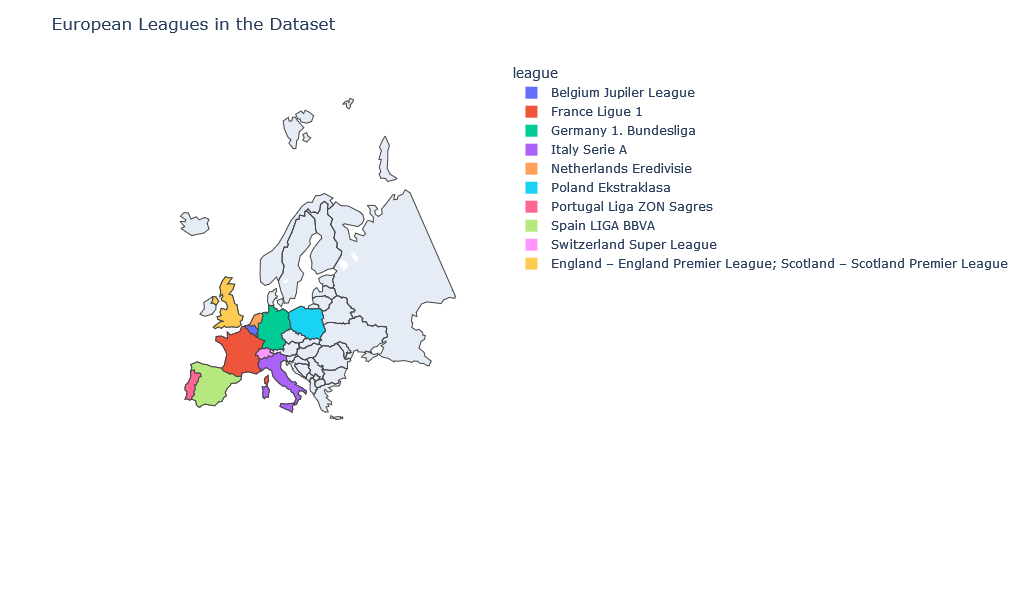

In [17]:
fig = px.choropleth(
    country_league_map,
    locations="country",
    hover_name="league",
    color="league",
    scope='europe',
    locationmode='country names',
)

fig.update_layout(width=1100, height=600, title_text='European Leagues in the Dataset')
fig.show()

## Team table

In [18]:
team.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


### Nulls and duplicates

In [19]:
team.dtypes

id                    int64
team_api_id           int64
team_fifa_api_id    float64
team_long_name       object
team_short_name      object
dtype: object

In [20]:
team.columns.duplicated().any()

False

In [21]:
team.duplicated().any()

False

There appears to be no duplicated entries in the dataset.

In [22]:
team_times_in_dataset = team.team_long_name.value_counts()
mask = team_times_in_dataset > 1
duplicated_team = team_times_in_dataset[mask]
duplicated_team

team_long_name
Widzew Łódź             2
Royal Excel Mouscron    2
Polonia Bytom           2
Name: count, dtype: int64

In [23]:
mask = team.team_long_name.isin(duplicated_team.index)
duplicated_teams = team[mask]
duplicated_teams

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
15,16,9996,111560.0,Royal Excel Mouscron,MOU
24,2510,274581,111560.0,Royal Excel Mouscron,MOP
182,31444,8031,111429.0,Polonia Bytom,POB
183,31445,8020,111429.0,Polonia Bytom,GOR
189,31451,8244,301.0,Widzew Łódź,LOD
199,32409,8024,301.0,Widzew Łódź,WID


There are no duplicate entries, but there are some duplicated teams it seems. Their team_api_ids and team_short_names are different, however they have same team_fifa_api_id. Duplicates were not removed from the dataset.

In [24]:
len(team)

299

In [25]:
len(team.team_short_name.unique())

259

It seems that team_short_name are not unique and could repeat for some teams.

In [26]:
team.isnull().sum()

id                   0
team_api_id          0
team_fifa_api_id    11
team_long_name       0
team_short_name      0
dtype: int64

In [27]:
mask = team.isnull().any(axis=1)
team[mask]

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
8,9,7947,NaN,FCV Dender EH,DEN
14,15,4049,NaN,Tubize,TUB
170,26561,6601,NaN,FC Volendam,VOL
204,34816,177361,NaN,Termalica Bruk-Bet Nieciecza,TBN
208,35286,7992,NaN,Trofense,TRO
213,35291,10213,NaN,Amadora,AMA
223,36248,9765,NaN,Portimonense,POR
225,36723,4064,NaN,Feirense,FEI
232,38789,6367,NaN,Uniao da Madeira,MAD
233,38791,188163,NaN,Tondela,TON


These teams do not have team_fifa_api_id.

### Data exploration

In [28]:
len(team)

299

In [29]:
team_amount = len(team.team_long_name.unique())
team_amount

296

There are 296 unique teams in the dataset, 3 of them are entered two times.

In [30]:
len(team.team_fifa_api_id.dropna().unique())

285

In total there are 285 teams with unique team_fifa_api_id.

## Team attribute table

In [31]:
team_att.head()

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,buildUpPlayPositioningClass,chanceCreationPassing,chanceCreationPassingClass,chanceCreationCrossing,chanceCreationCrossingClass,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,Organised,60,Normal,65,Normal,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,Organised,54,Normal,63,Normal,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,Organised,54,Normal,63,Normal,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,Organised,70,Risky,70,Lots,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,Organised,53,Normal,48,Normal,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [32]:
team_att['date'] = team_att.date.astype('datetime64[ns]')

In [33]:
team_att.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458 entries, 0 to 1457
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              1458 non-null   int64         
 1   team_fifa_api_id                1458 non-null   int64         
 2   team_api_id                     1458 non-null   int64         
 3   date                            1458 non-null   datetime64[ns]
 4   buildUpPlaySpeed                1458 non-null   int64         
 5   buildUpPlaySpeedClass           1458 non-null   object        
 6   buildUpPlayDribbling            489 non-null    float64       
 7   buildUpPlayDribblingClass       1458 non-null   object        
 8   buildUpPlayPassing              1458 non-null   int64         
 9   buildUpPlayPassingClass         1458 non-null   object        
 10  buildUpPlayPositioningClass     1458 non-null   object        
 11  chan

In [34]:
len(team_att.team_fifa_api_id.unique())

285

In [35]:
len(team_att.team_api_id.unique())

288

There are 299 entries in the teams table and 296 unique teams, therefore it seems that not every team is in the team attribute table. It seems that 11 teams which do not have team_fifa_api_id are not included in this dataset.

In [36]:
team_att.date.groupby(team_att.date.dt.year).value_counts()

date  date      
2010  2010-02-22    241
2011  2011-02-22    244
2012  2012-02-22    242
2013  2013-09-20    242
2014  2014-09-19    244
2015  2015-09-10    245
Name: count, dtype: int64

The dataset was started in 2010-02-22 and each year till 2015-09-10, from 241 to 245 entries were added.

### Adding seasons

Football seasons start in August and end in next year April.

In [37]:
def season_f(date):
    '''
    This is a helper function to classify seasons for team attribute table.
    If there is no information about the season, it will be classified as other.
    '''

    date = str(date)[0:10]

    if date == '2010-02-22':
        return '2009/2010'
    elif date == '2011-02-22':
        return '2010/2011'
    elif date == '2012-02-22':
        return '2011/2012'
    elif date == '2013-09-20':
        return '2013/2014'
    elif date == '2014-09-19':
        return '2014/2015'
    elif date == '2015-09-10':
        return '2015/2016'
    else:
        return 'other'


team_att['season'] = team_att.date.apply(season_f)
team_att.season.unique()

array(['2009/2010', '2014/2015', '2015/2016', '2010/2011', '2011/2012',
       '2013/2014'], dtype=object)

### Nulls and duplicates

In [38]:
team_att.isnull().sum()

id                                  0
team_fifa_api_id                    0
team_api_id                         0
date                                0
buildUpPlaySpeed                    0
buildUpPlaySpeedClass               0
buildUpPlayDribbling              969
buildUpPlayDribblingClass           0
buildUpPlayPassing                  0
buildUpPlayPassingClass             0
buildUpPlayPositioningClass         0
chanceCreationPassing               0
chanceCreationPassingClass          0
chanceCreationCrossing              0
chanceCreationCrossingClass         0
chanceCreationShooting              0
chanceCreationShootingClass         0
chanceCreationPositioningClass      0
defencePressure                     0
defencePressureClass                0
defenceAggression                   0
defenceAggressionClass              0
defenceTeamWidth                    0
defenceTeamWidthClass               0
defenceDefenderLineClass            0
season                              0
dtype: int64

There are some nulls only in buildUpPlayDribbling attribute.

In [39]:
mask = team_att.date < '2014'
entries_bef_2014 = team_att[mask].buildUpPlayDribbling
print(f'Total entries before 2014: {len(entries_bef_2014)}.')
print(f'Null entries for buildUpPlayDribbling before 2014: {entries_bef_2014.isnull().sum()}.')

Total entries before 2014: 969.
Null entries for buildUpPlayDribbling before 2014: 969.


It seems that buildUpPlayDribbling attribute was introduced only in 2014, therefore before that year every value for it is missing.

In [40]:
team_att.columns.duplicated().any()

False

In [41]:
team_att.duplicated().any()

False

In [42]:
team_times_entered = team_att.team_fifa_api_id.groupby(team_att.team_fifa_api_id).count()
team_times_entered.value_counts()

team_fifa_api_id
6    189
5     28
3     21
4     17
2     16
1     13
8      1
Name: count, dtype: int64

There is one team entered into the dataset 8 times even if the dataset has been collected for 6 years.

In [43]:
mask = team_times_entered == 8
team_8_times_entered = team_times_entered[mask].index[0]
team_8_times_entered

301

In [44]:
dup_teams_ids = duplicated_teams.team_fifa_api_id.unique()
dup_teams_ids

array([111560., 111429.,    301.])

In [45]:
mask = team_att.team_fifa_api_id.isin(dup_teams_ids)
team_att[mask].sort_values(by=['team_fifa_api_id'])

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,buildUpPlayPositioningClass,chanceCreationPassing,chanceCreationPassingClass,chanceCreationCrossing,chanceCreationCrossingClass,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass,season
754,755,301,8244,2011-02-22,63,Balanced,NaN,Little,48,Mixed,Organised,48,Normal,68,Lots,53,Normal,Organised,37,Medium,58,Press,63,Normal,Cover,2010/2011
755,756,301,8244,2012-02-22,66,Balanced,NaN,Little,72,Long,Organised,70,Risky,61,Normal,54,Normal,Organised,32,Deep,32,Contain,62,Normal,Cover,2011/2012
756,757,301,8244,2013-09-20,66,Balanced,NaN,Little,59,Mixed,Organised,43,Normal,61,Normal,54,Normal,Organised,32,Deep,43,Press,46,Normal,Cover,2013/2014
757,758,301,8244,2014-09-19,66,Balanced,52.0,Normal,72,Long,Organised,66,Normal,67,Lots,51,Normal,Organised,36,Medium,38,Press,65,Normal,Cover,2014/2015
1394,1395,301,8024,2011-02-22,63,Balanced,NaN,Little,48,Mixed,Organised,48,Normal,68,Lots,53,Normal,Organised,37,Medium,58,Press,63,Normal,Cover,2010/2011
1395,1396,301,8024,2012-02-22,66,Balanced,NaN,Little,72,Long,Organised,70,Risky,61,Normal,54,Normal,Organised,32,Deep,32,Contain,62,Normal,Cover,2011/2012
1396,1397,301,8024,2013-09-20,66,Balanced,NaN,Little,59,Mixed,Organised,43,Normal,61,Normal,54,Normal,Organised,32,Deep,43,Press,46,Normal,Cover,2013/2014
1397,1398,301,8024,2014-09-19,66,Balanced,52.0,Normal,72,Long,Organised,66,Normal,67,Lots,51,Normal,Organised,36,Medium,38,Press,65,Normal,Cover,2014/2015
522,523,111429,8020,2010-02-22,30,Slow,NaN,Little,50,Mixed,Organised,45,Normal,35,Normal,70,Lots,Organised,60,Medium,70,Double,55,Normal,Cover,2009/2010
523,524,111429,8020,2011-02-22,46,Balanced,NaN,Little,38,Mixed,Organised,36,Normal,33,Little,53,Normal,Organised,53,Medium,54,Press,55,Normal,Cover,2010/2011


It seems that teams which were duplicated in teams table are also duplicated in team_attributes table as well. It also seems that even if the 1st column - id - is different, rest of columns might be the same.

In [46]:
team_att.iloc[:, 1:].duplicated().sum()

1

There is only one instance of duplicated rows. Therefore row 860 will be dropped.

In [47]:
team_att.drop(index=860, inplace=True)

In [48]:
team_att.iloc[:, 1:].duplicated().sum()

0

In [49]:
# Checking if there are any other teams which were added twise in a year.

team_att_entries_year = team_att.team_fifa_api_id.groupby(team_att.date.dt.year).value_counts()
max_entries = team_att_entries_year.max()
mask = team_att_entries_year == max_entries
team_att_entries_year[mask]

date  team_fifa_api_id
2010  111429              2
2011  301                 2
      111429              2
2012  301                 2
2013  301                 2
2014  301                 2
2015  111560              2
Name: count, dtype: int64

Only the teams which had two team_api_ids has been entered twice. The duplicates will not be removed as they have different team_api_id and which is used in Match table. Due to low amount of duplicates the impact of them on statistics will be minimal and insignificant.

### Data exploration

In [50]:
team_att.team_fifa_api_id.groupby(team_att.date.dt.year).count()

date
2010    241
2011    244
2012    242
2013    242
2014    244
2015    244
Name: team_fifa_api_id, dtype: int64

In [51]:
team_att_num_feat = team_att.iloc[:, 4:].select_dtypes(include=['number'])
team_att_stats = team_att_num_feat.describe()
team_att_stats

,buildUpPlaySpeed,buildUpPlayDribbling,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
count,1457.000000,488.000000,1457.000000,1457.000000,1457.000000,1457.000000,1457.000000,1457.000000,1457.000000
mean,52.463967,48.604508,48.489362,52.166781,53.734386,53.971860,46.017845,49.253946,52.187371
std,11.549653,9.688015,10.899771,10.364195,11.090171,10.330588,10.230702,9.740734,9.577828
min,20.000000,24.000000,20.000000,21.000000,20.000000,22.000000,23.000000,24.000000,29.000000
25%,45.000000,42.000000,40.000000,46.000000,47.000000,48.000000,39.000000,44.000000,47.000000
50%,52.000000,49.000000,50.000000,52.000000,53.000000,53.000000,45.000000,48.000000,52.000000
75%,62.000000,55.000000,55.000000,59.000000,62.000000,61.000000,51.000000,55.000000,58.000000
max,80.000000,77.000000,80.000000,80.000000,80.000000,80.000000,72.000000,72.000000,73.000000


In [52]:
team_att_numerical = team_att_stats.columns

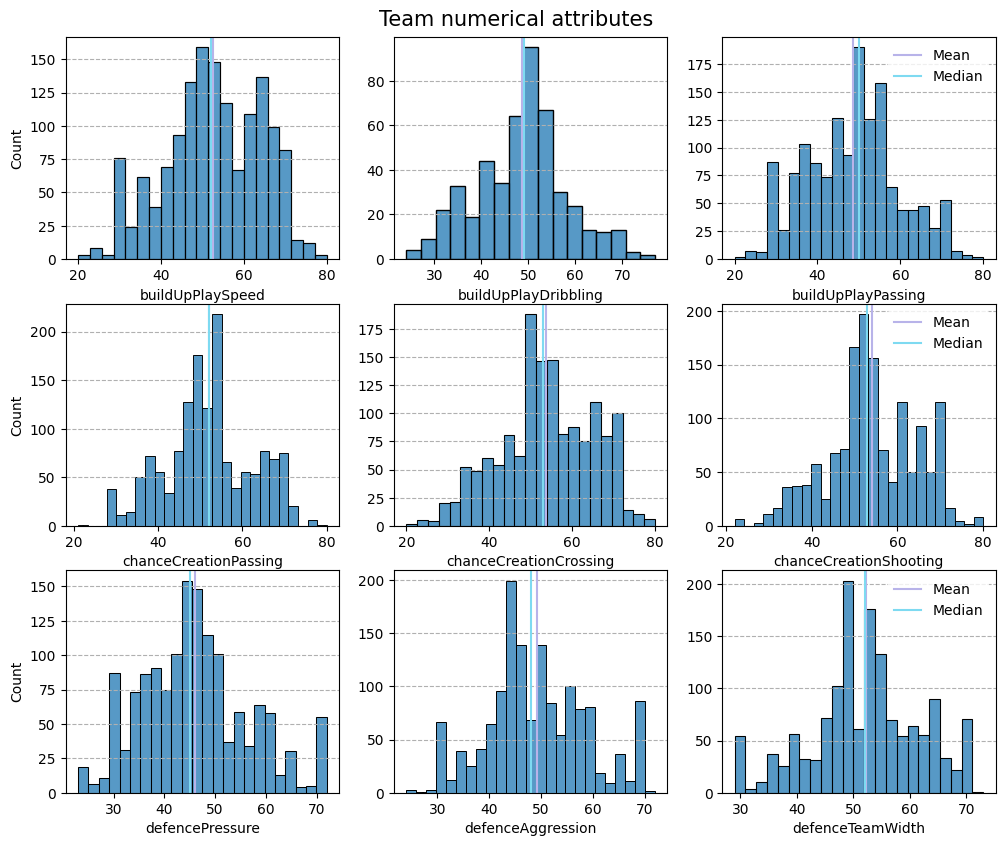

In [53]:
fig, axs = plt.pyplot.subplots(3, 3, figsize=(12, 9))
fig.suptitle('Team numerical attributes', fontsize=15)
fig.subplots_adjust(top=0.95)

i = 0
j = 0
for col in team_att_numerical:
    ax = histplot_f(team_att.loc[:, col], ax=axs[j, i])

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    # Leaving only right most legends
    if i == 2:
        pass
    else:
        ax.get_legend().set_visible(False)

    i += 1
    if i == 3:
        i = 0
        j += 1

plt.pyplot.tight_layout;

Every attribute is distributed approximately normally and range from 20 to 80. Every attributes mean is around 50 and median is also around that value. There are no obvious outliers. Some of the attributes, like buildUpPlaySpeed, defenceAggression and defenceTeamWidth are distributed multimodaly. Few distributions are slightly skewed to the left like changeCreationCrossing and changeCreationShooting.

In [54]:
team_att_categorical = team_att.select_dtypes(include=['object']).columns

# Not selecting seasons column:
team_att_categorical = team_att_categorical[:-1]
len(team_att_categorical)

12

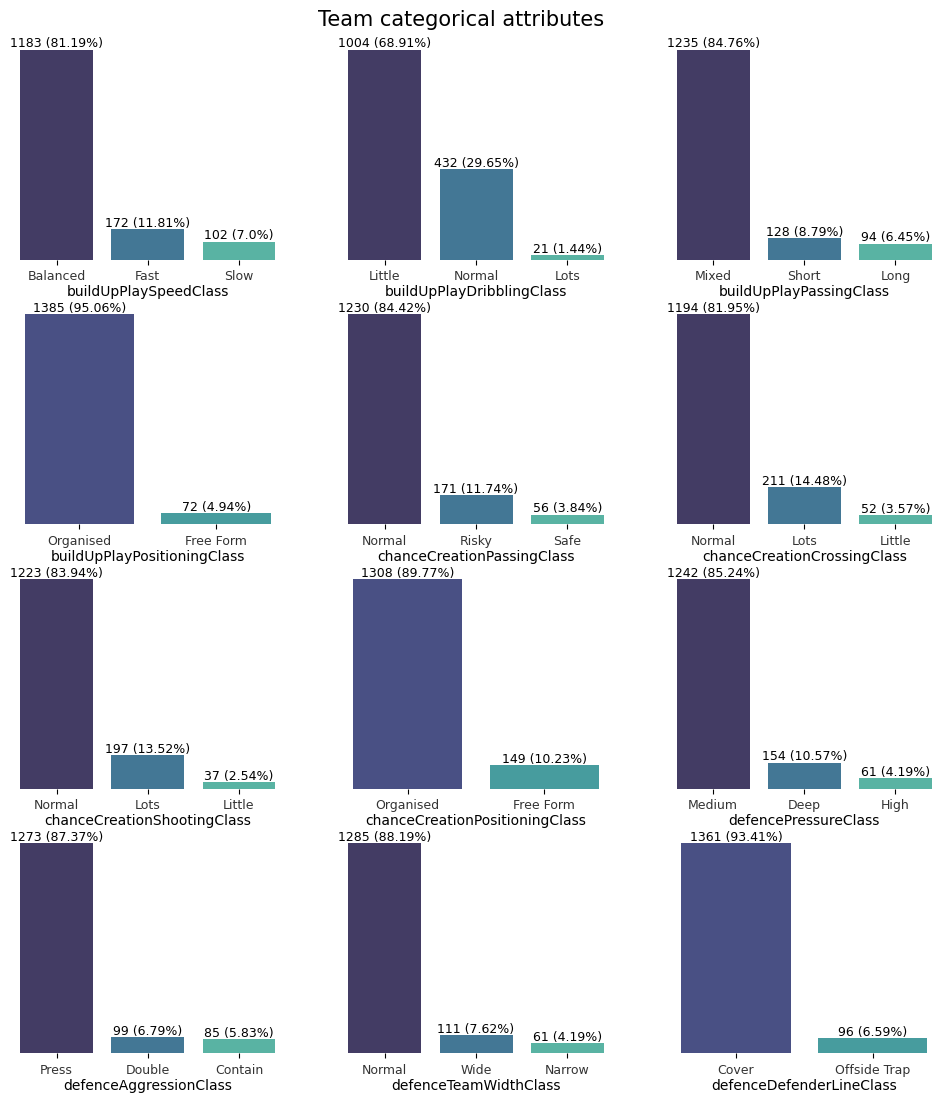

In [55]:
fig, axs = plt.pyplot.subplots(4, 3, figsize=(12, 12))
fig.suptitle('Team categorical attributes', fontsize=15)
fig.subplots_adjust(top=0.955)

i = 0
j = 0
for col in team_att_categorical:
    ax = bar_plot_f_perc(team_att.loc[:, col].value_counts(), palet='mako', ax=axs[j, i])
    ax.set_title(col, fontsize=10, y=-0.2)

    i += 1
    if i == 3:
        i = 0
        j += 1

plt.pyplot.tight_layout
sns.despine(left=True, bottom=True)

In categorical attributes we can see that there is a preference for a specific category in each of the attributes for majority of teams. For example, 88.2% of teams have normal defenceTeamWidthClass, while only 7.61% Wide and 4.18% Narrow. This makes the dataset unbalanced in regards to the different category attributes, as there are rare and common categories.

In [56]:
team_att_corr = team_att_num_feat.corr()

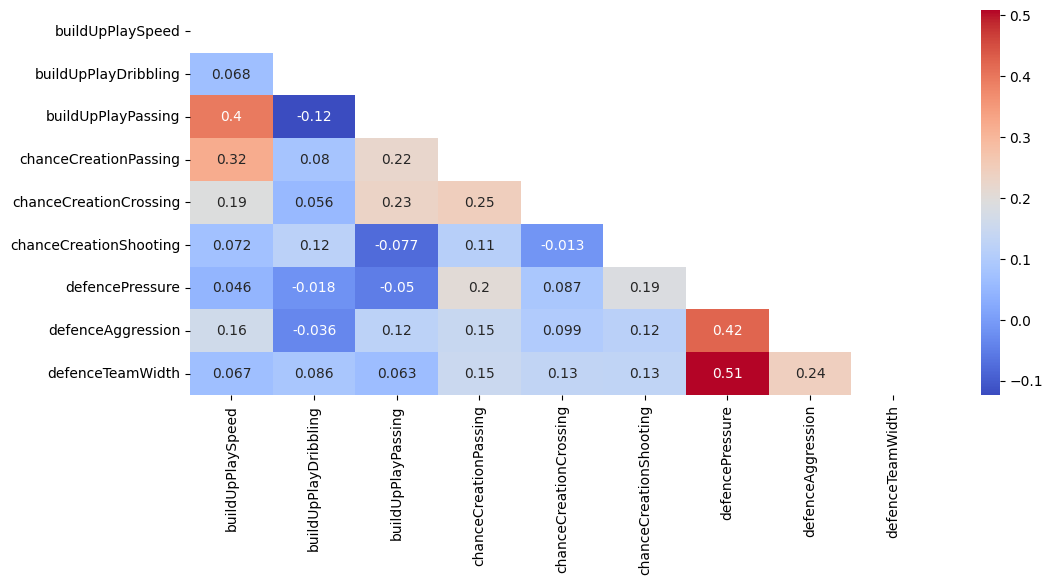

In [57]:
fig = plt.pyplot.figure(figsize=(12, 5))

# To make a triangle mask
mask = np.triu(np.ones_like(team_att_corr))

corr_plot = sns.heatmap(team_att_corr, cmap=sns.color_palette("coolwarm", as_cmap=True), annot=True, mask=mask)

Defence pressure is moderately positively correlated with defence team width (0.51) and weakly with defence aggression (0.42). Build up play speed is weakly positively correlated with build up play passing (0.4) and chance creation passing (0.32). Rest of correlation coefficients are even weaker and are between -0.12 and 0.25.

#### Outliers

In [58]:
team_att_out = outlier_f(team_att_num_feat)
print(f'There are {len(team_att_out)} teams with outlier attributes.')

There are 130 teams with outlier attributes.


In [59]:
team_att_out.count(axis=0)

buildUpPlaySpeed           0
buildUpPlayDribbling       1
buildUpPlayPassing         2
chanceCreationPassing      2
chanceCreationCrossing     4
chanceCreationShooting     9
defencePressure           55
defenceAggression          5
defenceTeamWidth          54
dtype: int64

In [60]:
outlier_f(team_att_num_feat, lower=True).count(axis=0)

buildUpPlaySpeed           0
buildUpPlayDribbling       0
buildUpPlayPassing         0
chanceCreationPassing      1
chanceCreationCrossing     4
chanceCreationShooting     9
defencePressure            0
defenceAggression          4
defenceTeamWidth          54
dtype: int64

In [61]:
outlier_f(team_att_num_feat, upper=True).count(axis=0)

buildUpPlaySpeed           0
buildUpPlayDribbling       1
buildUpPlayPassing         2
chanceCreationPassing      1
chanceCreationCrossing     0
chanceCreationShooting     0
defencePressure           55
defenceAggression          1
defenceTeamWidth           0
dtype: int64

In [62]:
team_att_out_nr = team_att_out.count(axis=1)

for i in range(1, team_att_out_nr.max() + 1):
    temp = 0
    for row in team_att_out_nr:
        if row == i:
            temp += 1
    print(f'{temp} {"team" if temp == 1 else "teams have"} {i} outlier {"attribute" if i == 1 else "attributes"}.')

128 teams have 1 outlier attribute.
2 teams have 2 outlier attributes.


In [63]:
mask = team_att_out_nr == team_att_out_nr.max()
team_att_out[mask].dropna(axis=1, how='all')

,chanceCreationShooting,defencePressure,defenceTeamWidth
39,NaN,70.0,30.0
147,22.0,72.0,NaN


There are two teams with 2 outlier attributes in the dataset. Both of them have outlier defence pressure and one other attribute as an outlier.

#### Drawing a radar chart for a team

In [64]:
query = """
SELECT t.team_long_name, t.team_fifa_api_id, ta.date, 
       ta.buildUpPlaySpeed, 
       ta.buildUpPlayPassing,
       ta.chanceCreationPassing,
       ta.chanceCreationCrossing,
       ta.chanceCreationShooting,
       ta.defencePressure,
       ta.defenceAggression,
       ta.defenceTeamWidth
FROM team t
JOIN team_att ta ON ta.team_fifa_api_id = t.team_fifa_api_id
WHERE t.team_fifa_api_id = 77
"""
team_77 = db.sql(query).df()
team_77

,team_long_name,team_fifa_api_id,date,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
0,Aberdeen,77.0,2010-02-22,70,70,70,70,70,60,70,70
1,Aberdeen,77.0,2011-02-22,47,52,53,48,52,47,47,52
2,Aberdeen,77.0,2012-02-22,58,62,45,70,55,40,40,60
3,Aberdeen,77.0,2013-09-20,62,45,40,50,55,42,42,60
4,Aberdeen,77.0,2014-09-19,58,62,56,68,57,41,42,60
5,Aberdeen,77.0,2015-09-10,59,53,51,72,63,49,45,63


In [65]:
for_radar = team_77.iloc[:, 3:]

In [66]:
theta = for_radar.columns

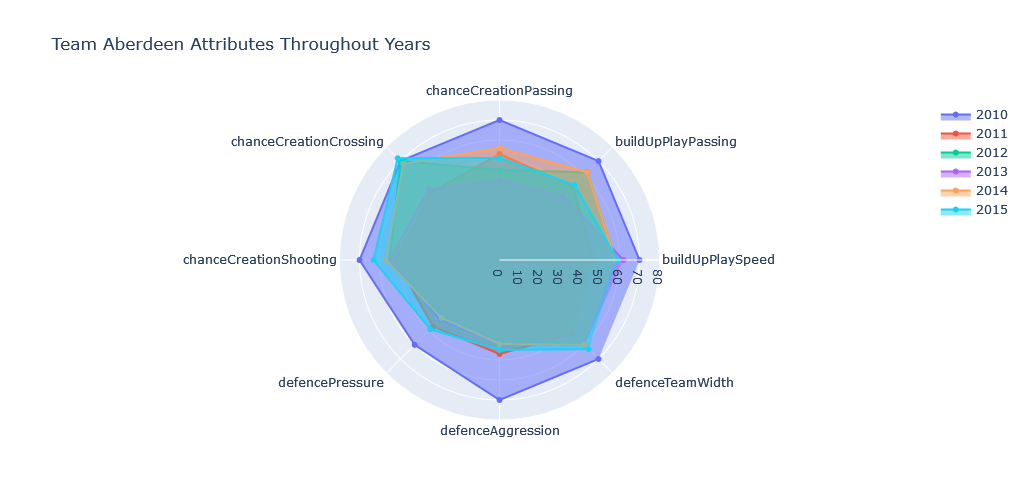

In [67]:
fig = go.Figure()

# All of the years team was added to the dataset:
years = np.sort(team_77.date.dt.year.unique())

for i in range(len(years)):
    fig.add_trace(go.Scatterpolar(r=for_radar.iloc[i].values, theta=theta, fill='toself', name=str(years[i])))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True, range=[0, 80])),
    width=800,
    height=500,
    title_text='Team Aberdeen Attributes Throughout Years',
)

fig.show()

## Player table

In [68]:
player.head()

,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,1,505942,Aaron Appindangoye,218353,1992-02-29 00:00:00,182.88,187
1,2,155782,Aaron Cresswell,189615,1989-12-15 00:00:00,170.18,146
2,3,162549,Aaron Doran,186170,1991-05-13 00:00:00,170.18,163
3,4,30572,Aaron Galindo,140161,1982-05-08 00:00:00,182.88,198
4,5,23780,Aaron Hughes,17725,1979-11-08 00:00:00,182.88,154


In [69]:
player['birthday'] = player.birthday.astype('datetime64[ns]')

In [70]:
player.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11060 entries, 0 to 11059
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id                  11060 non-null  int64         
 1   player_api_id       11060 non-null  int64         
 2   player_name         11060 non-null  object        
 3   player_fifa_api_id  11060 non-null  int64         
 4   birthday            11060 non-null  datetime64[ns]
 5   height              11060 non-null  float64       
 6   weight              11060 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(4), object(1)
memory usage: 605.0+ KB


In [71]:
print(f'There are {len(player.player_fifa_api_id.unique())} players in the dataset.')

There are 11060 players in the dataset.


### Nulls and duplicates

In [72]:
player.isnull().any().any()

False

In [73]:
player.columns.duplicated().any()

False

In [74]:
player.duplicated().any()

False

In [75]:
player.player_name.value_counts().max()

7

In [76]:
player.player_fifa_api_id.value_counts().max()

1

There are some people with same names, however all of player_fifa_api_ids are different, therefore there are no duplicates in the dataset.

### Data exploration

In [77]:
player.iloc[:, 4:].describe()

,birthday,height,weight
count,11060,11060.000000,11060.000000
mean,1987-02-03 21:19:20.072332800,181.867445,168.380289
min,1967-01-23 00:00:00,157.480000,117.000000
25%,1983-03-17 00:00:00,177.800000,159.000000
50%,1987-07-08 00:00:00,182.880000,168.000000
75%,1991-04-12 00:00:00,185.420000,179.000000
max,1999-04-24 00:00:00,208.280000,243.000000
std,NaN,6.369201,14.990217


In [78]:
player['year'] = player.birthday.dt.year

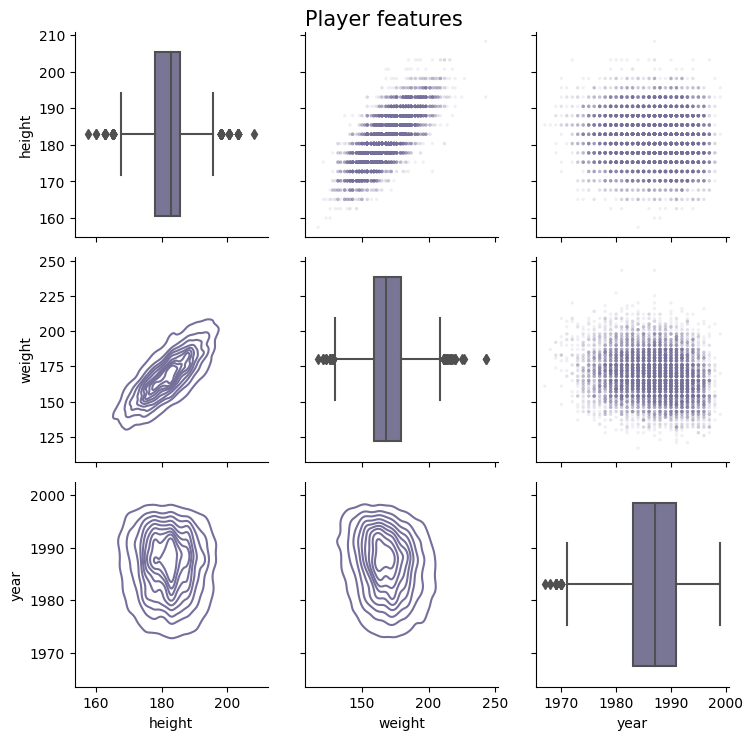

In [79]:
g = sns.PairGrid(player.iloc[:, 5:])
g.fig.subplots_adjust(top=0.95)
g.fig.suptitle('Player features', fontsize=15)
g.map_lower(sns.kdeplot, color="#756F9B")
g.map_diag(sns.boxplot, color="#756F9B")
g.map_upper(sns.scatterplot, color='#756F9B', s=6, alpha=0.1, edgecolor='none');

We can see that there are some outliers on both ends of height and weight distributions. On birth year there are only outliers on left side – players who were born earlier. We can also see that weight and height should have strong positive correlation and birth year should not correlate with other other features.

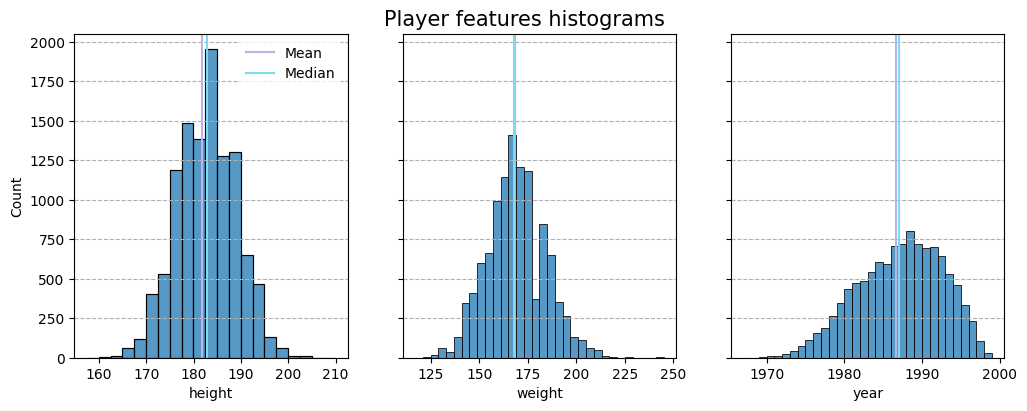

In [80]:
fig, axs = plt.pyplot.subplots(1, 3, sharey=True, figsize=(12, 4))
fig.suptitle('Player features histograms', fontsize=15)
fig.subplots_adjust(top=0.92)

ax0 = histplot_f(player.height, ax=axs[0], binwidth=2.5)

ax1 = histplot_f(player.weight, ax=axs[1], binwidth=4)
ax1.get_legend().set_visible(False)

ax2 = histplot_f(player.year, ax=axs[2], binwidth=1)
ax2.get_legend().set_visible(False)

plt.pyplot.tight_layout;

All of the player features are distributed approximately normally. We can see that weight distribution is skewed to the right and player birth year distribution is skewed to the left.

In [81]:
player_corr = player.iloc[:, 5:].corr()

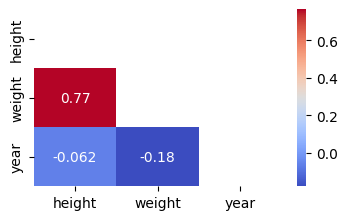

In [82]:
fig = plt.pyplot.figure(figsize=(4, 2.3))

# To make a triangle mask
mask = np.triu(np.ones_like(player_corr))

corr_plot = sns.heatmap(player_corr, cmap=sns.color_palette("coolwarm", as_cmap=True), annot=True, mask=mask)

There is strong positive correlation between weight and height (0.77). Correlation between year and height is insignificant (-0.062) and correlation between year and weight is weak and negative (-0.18).

## Player Attributes dataset

In [83]:
player_att.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18 00:00:00,67.0,71.0,right,medium,medium,49.0,44.0,71.0,61.0,44.0,51.0,45.0,39.0,64.0,49.0,60.0,64.0,59.0,47.0,65.0,55.0,58.0,54.0,76.0,35.0,71.0,70.0,45.0,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
1,2,218353,505942,2015-11-19 00:00:00,67.0,71.0,right,medium,medium,49.0,44.0,71.0,61.0,44.0,51.0,45.0,39.0,64.0,49.0,60.0,64.0,59.0,47.0,65.0,55.0,58.0,54.0,76.0,35.0,71.0,70.0,45.0,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
2,3,218353,505942,2015-09-21 00:00:00,62.0,66.0,right,medium,medium,49.0,44.0,71.0,61.0,44.0,51.0,45.0,39.0,64.0,49.0,60.0,64.0,59.0,47.0,65.0,55.0,58.0,54.0,76.0,35.0,63.0,41.0,45.0,54.0,48.0,65.0,66.0,69.0,6.0,11.0,10.0,8.0,8.0
3,4,218353,505942,2015-03-20 00:00:00,61.0,65.0,right,medium,medium,48.0,43.0,70.0,60.0,43.0,50.0,44.0,38.0,63.0,48.0,60.0,64.0,59.0,46.0,65.0,54.0,58.0,54.0,76.0,34.0,62.0,40.0,44.0,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0
4,5,218353,505942,2007-02-22 00:00:00,61.0,65.0,right,medium,medium,48.0,43.0,70.0,60.0,43.0,50.0,44.0,38.0,63.0,48.0,60.0,64.0,59.0,46.0,65.0,54.0,58.0,54.0,76.0,34.0,62.0,40.0,44.0,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0


In [84]:
player_att['date'] = player_att.date.astype('datetime64[ns]')

In [85]:
player_att.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183978 entries, 0 to 183977
Data columns (total 42 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   id                   183978 non-null  int64         
 1   player_fifa_api_id   183978 non-null  int64         
 2   player_api_id        183978 non-null  int64         
 3   date                 183978 non-null  datetime64[ns]
 4   overall_rating       183142 non-null  float64       
 5   potential            183142 non-null  float64       
 6   preferred_foot       183142 non-null  object        
 7   attacking_work_rate  180748 non-null  object        
 8   defensive_work_rate  183142 non-null  object        
 9   crossing             183142 non-null  float64       
 10  finishing            183142 non-null  float64       
 11  heading_accuracy     183142 non-null  float64       
 12  short_passing        183142 non-null  float64       
 13  volleys       

Here are descriptions for some of the player attributes:

- Acceleration: The rate at which a player’s running speed increases.
- Aggression: A player’s degree of aggressiveness.
- Agility: Determines a player’s ability to manage and control the ball quickly and gracefully.
- Balance: The even distribution of enabling a player to remain upright and keep going.
- Ball Control: A player’s ability to keep possession of the ball.
- Crossing: The quality and accuracy of a player’s crosses. A cross is a medium- to-long-range pass from a wide area of the pitch towards the centre of the field near the opponent's goal.
- Curve: A player’s ability to curve the ball when passing and shooting.
- Dribbling: A player’s ability to carry the ball and past an opponent.
- Finishing: The ability of a player to score.
- Free Kick: The precision with which a player takes free kicks.
- Heading: A player’s accuracy when using the head to pass, shoot or clear the ball.
- Interceptions: The ability of a player to intercept the ball.
- Jumping: The ability of a player to jump off the ground for headers.
- Long Passing: A player’s accuracy for the long passes.
- Long Shot: A player’s accuracy for the shots taking from long distances.
- Marking: The ability of a player to mark an opponent.
- Penalties: A player’s accuracy for taking penalty shots.
- Reactions: A player’s reaction time in response to events taking place around them.
- Short Passing: A player’s accuracy for the short passes.
- Shot Power: The strength of a player’s shoots.
- Sliding Tackle: The ability to pull off a sliding tackle.
- Sprint Speed: Defines the speed rate of a player’s sprinting.
- Stamina: A player’s ability to sustain prolonged physical or mental effort.
- Standing Tackle: The ability of performing standing tackle.
- Strength: The quality or state of being physically strong.
- Vision: A player’s mental awareness about his teammates’ positioning, for passing the ball to them.
- Volleys: The ability of a player to perform volleys. A volley is an air-borne strike in association football, where a player's foot meets and directs the ball in an angled direction before it has time to reach the ground.

Sources: 
https://www.fifplay.com/fifa-22-player-attributes/ ;
https://en.wikipedia.org/wiki/Volley_(association_football) ; 
https://en.wikipedia.org/wiki/Cross_(association_football) .

In [86]:
query = """
SELECT YEAR(date) AS year, COUNT() count
FROM player_att
GROUP BY YEAR(date) 
ORDER BY YEAR(date)
"""

player_att_entries_year = db.sql(query).df().set_index('year').squeeze()
player_att_entries_year

year
2007    16138
2008     5798
2009     8993
2010    10829
2011    11976
2012    12632
2013    38867
2014    32808
2015    31834
2016    14103
Name: count, dtype: int64

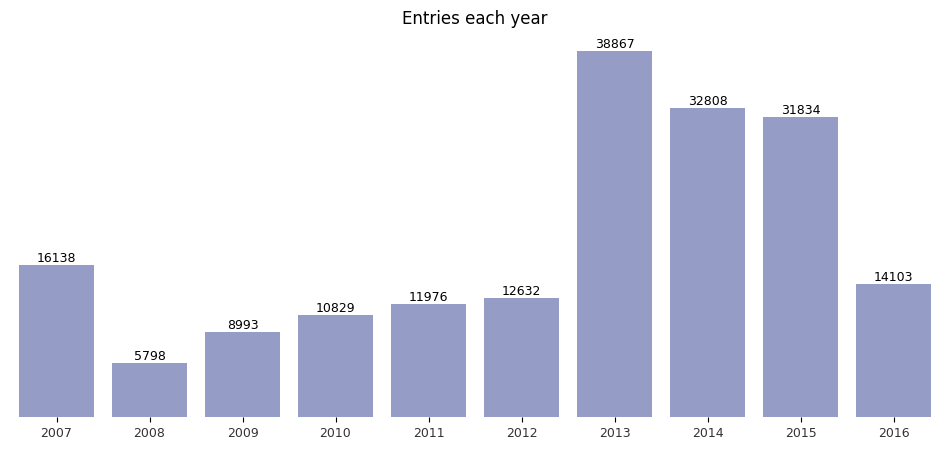

In [87]:
fig = plt.pyplot.figure(figsize=(12, 5))

ax = bar_plot_f(player_att_entries_year, name='Entries each year', color='#8D97CE')

sns.despine(left=True, bottom=True)

The dataset spawns from year 2007 to 2016. Highest amount of entries entered is for 2013, lowest for 2008.

In [88]:
query = """
SELECT COUNT(DISTINCT player_fifa_api_id) player_count
FROM player_att
"""

db.sql(query).df()

,player_count
0,11062


In the player attribute table there are 11062 players, while in the player table there are 11060.

### Nulls and duplicates

In [89]:
query = '''
SELECT *, COUNT(*)
FROM player_att
GROUP BY *
HAVING COUNT(*) > 1
'''

db.sql(query).df()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes,count_star()


There are no obvious duplicates in the dataset.

In [90]:
player_att.columns.duplicated().any()

False

In [91]:
player_att.attacking_work_rate.unique()

array(['medium', 'high', None, 'low', 'None', 'le', 'norm', 'stoc', 'y'],
      dtype=object)

There are some values which are None but are in text format. Attacking_work_rate should be medium, high or low, therefore rest of the values are also going to be replaces with None.

In [92]:
player_att = player_att.replace(['None', 'le', 'norm', 'stoc', 'y'], None)

In [93]:
player_att.attacking_work_rate.unique()

array(['medium', 'high', None, 'low'], dtype=object)

In [94]:
player_def_work_rate_values = player_att.defensive_work_rate.unique().copy()
player_def_work_rate_values

array(['medium', 'high', 'low', '_0', None, '5', 'ean', 'o', '1', 'ormal',
       '7', '2', '8', '4', 'tocky', '0', '3', '6', '9', 'es'],
      dtype=object)

Player defensive work rate should also be just medium, high and low, therefore other values are going to be replaced to None.

In [95]:
items_to_none = np.delete(player_def_work_rate_values, [0, 1, 2], None)
items_to_none

array(['_0', None, '5', 'ean', 'o', '1', 'ormal', '7', '2', '8', '4',
       'tocky', '0', '3', '6', '9', 'es'], dtype=object)

In [96]:
player_att.defensive_work_rate.replace(items_to_none, None, inplace=True)

In [97]:
player_att.isnull().sum()

id                        0
player_fifa_api_id        0
player_api_id             0
date                      0
overall_rating          836
potential               836
preferred_foot          836
attacking_work_rate    7516
defensive_work_rate    7659
crossing                836
finishing               836
heading_accuracy        836
short_passing           836
volleys                2713
dribbling               836
curve                  2713
free_kick_accuracy      836
long_passing            836
ball_control            836
acceleration            836
sprint_speed            836
agility                2713
reactions               836
balance                2713
shot_power              836
jumping                2713
stamina                 836
strength                836
long_shots              836
aggression              836
interceptions           836
positioning             836
vision                 2713
penalties               836
marking                 836
standing_tackle     

In [98]:
mask = player_att["overall_rating"].isnull()
player_att[mask].head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
483,484,33022,31684,2007-02-22,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
983,984,111085,29904,2007-02-22,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1752,1753,165740,24159,2007-02-22,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2089,2090,176941,31916,2007-02-22,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2482,2483,177615,37249,2007-02-22,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


There seems to be a lot of entries without overall rating. They will be dropped out of the dataset.

In [99]:
player_att = player_att.dropna(subset=['overall_rating'])
player_att.isnull().sum()

id                        0
player_fifa_api_id        0
player_api_id             0
date                      0
overall_rating            0
potential                 0
preferred_foot            0
attacking_work_rate    6680
defensive_work_rate    6823
crossing                  0
finishing                 0
heading_accuracy          0
short_passing             0
volleys                1877
dribbling                 0
curve                  1877
free_kick_accuracy        0
long_passing              0
ball_control              0
acceleration              0
sprint_speed              0
agility                1877
reactions                 0
balance                1877
shot_power                0
jumping                1877
stamina                   0
strength                  0
long_shots                0
aggression                0
interceptions             0
positioning               0
vision                 1877
penalties                 0
marking                   0
standing_tackle     

In [100]:
# Picking one of the attributes with null
# to check if others are also null at the same time.
mask = player_att.sliding_tackle.isnull()
player_att[mask].date.agg(['min', 'max'])

min   2007-02-22
max   2010-02-22
Name: date, dtype: datetime64[ns]

In [101]:
mask = player_att.date <= '2010-02-22'
player_att_2010 = player_att[mask].loc[
    :, ['player_fifa_api_id', 'volleys', 'curve', 'agility', 'balance', 'jumping', 'vision', 'sliding_tackle']
]

In [102]:
player_att_2010.isnull().sum()

player_fifa_api_id       0
volleys               1877
curve                 1877
agility               1877
balance               1877
jumping               1877
vision                1877
sliding_tackle        1877
dtype: int64

In [103]:
player_att_2010.isnull().any(axis=1).sum()

1877

All of these attributes are missing together.

In [104]:
mask = player_att_2010.isnull().any(axis=1)
player_att_2010_null_count = player_att_2010[mask].player_fifa_api_id.value_counts()
player_att_2010_null_count.head(10)

player_fifa_api_id
51725     7
122428    7
138430    7
176962    7
53056     7
5060      6
103783    6
7514      6
137486    6
4596      6
Name: count, dtype: int64

In [105]:
player_att_2010_null_count.tail()

player_fifa_api_id
116873    2
157498    2
171248    2
53469     2
27544     2
Name: count, dtype: int64

It seems that some of the attributes are missing for some players added on 2010 02 22 and before.

In [106]:
mask = player_att.attacking_work_rate.isnull()
player_att[mask].date.agg(['min', 'max'])

min   2007-02-22
max   2016-06-30
Name: date, dtype: datetime64[ns]

In [107]:
mask = player_att.defensive_work_rate.isnull()
player_att[mask].date.agg(['min', 'max'])

min   2007-02-22
max   2016-06-30
Name: date, dtype: datetime64[ns]

There seems to be some attacking work rates missing in whole dataset. Same goes for defensive work rate.

In [108]:
mask = player_att.iloc[:, 2:].duplicated()
player_att[mask]

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes


In [109]:
query = '''
SELECT player_fifa_api_id, date, COUNT(*) number
FROM player_att
GROUP BY player_fifa_api_id, date
HAVING COUNT(*) > 1
'''

duplicate_player = db.sql(query).df()
duplicate_player.head()

,player_fifa_api_id,date,number
0,208618,2015-02-20,2
1,208618,2012-08-31,2
2,190195,2016-05-05,2
3,190195,2013-04-05,2
4,184431,2016-04-14,2


In [110]:
query = '''
SELECT player_fifa_api_id, player_api_id, date, COUNT(*) number
FROM player_att
GROUP BY player_fifa_api_id, player_api_id, date
HAVING COUNT(*) > 1
'''

db.sql(query).df()

,player_fifa_api_id,player_api_id,date,number


In [111]:
duplicate_player.number.max()

2

In [112]:
duplicate_player_ids = duplicate_player.player_fifa_api_id.unique()
duplicate_player_ids

array([208618, 190195, 184431, 206652, 198394, 118359, 192635],
      dtype=int64)

In [113]:
mask = player_att.player_fifa_api_id.isin(duplicate_player_ids)
duplicate_player_att = player_att[mask]
duplicate_player_att

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
6984,6985,198394,282274,2016-03-31,71.0,74.0,left,medium,medium,68.0,67.0,61.0,72.0,62.0,75.0,61.0,62.0,53.0,73.0,82.0,79.0,85.0,68.0,76.0,65.0,49.0,67.0,61.0,59.0,43.0,31.0,70.0,72.0,54.0,27.0,26.0,28.0,16.0,7.0,12.0,8.0,15.0
6985,6986,198394,282274,2015-12-24,71.0,74.0,left,medium,medium,68.0,67.0,61.0,72.0,62.0,75.0,61.0,62.0,53.0,73.0,82.0,79.0,85.0,68.0,76.0,65.0,49.0,67.0,61.0,59.0,43.0,31.0,70.0,72.0,54.0,27.0,26.0,28.0,16.0,7.0,12.0,8.0,15.0
6986,6987,198394,282274,2015-11-06,72.0,75.0,left,medium,medium,68.0,67.0,61.0,75.0,62.0,76.0,61.0,62.0,53.0,74.0,82.0,79.0,87.0,68.0,76.0,65.0,49.0,67.0,61.0,59.0,43.0,31.0,70.0,72.0,54.0,27.0,26.0,28.0,16.0,7.0,12.0,8.0,15.0
6987,6988,198394,282274,2015-10-09,72.0,76.0,left,medium,medium,68.0,67.0,61.0,75.0,62.0,76.0,61.0,62.0,53.0,74.0,82.0,79.0,87.0,68.0,76.0,65.0,49.0,67.0,61.0,59.0,43.0,31.0,70.0,72.0,54.0,27.0,26.0,28.0,16.0,7.0,12.0,8.0,15.0
6988,6989,198394,282274,2015-09-25,73.0,78.0,left,medium,medium,70.0,67.0,61.0,79.0,62.0,80.0,61.0,62.0,53.0,76.0,82.0,79.0,87.0,68.0,76.0,65.0,49.0,67.0,61.0,59.0,43.0,31.0,70.0,72.0,54.0,27.0,26.0,28.0,16.0,7.0,12.0,8.0,15.0
6989,6990,198394,282274,2015-09-21,73.0,78.0,left,medium,medium,70.0,67.0,61.0,79.0,62.0,80.0,61.0,62.0,53.0,76.0,82.0,79.0,87.0,68.0,76.0,65.0,49.0,67.0,61.0,59.0,43.0,31.0,70.0,72.0,54.0,27.0,26.0,28.0,16.0,7.0,12.0,8.0,15.0
6990,6991,198394,282274,2015-04-10,72.0,77.0,left,medium,medium,69.0,71.0,60.0,78.0,61.0,79.0,60.0,61.0,52.0,75.0,82.0,79.0,87.0,67.0,76.0,64.0,49.0,67.0,61.0,58.0,42.0,30.0,69.0,71.0,53.0,26.0,25.0,27.0,15.0,6.0,11.0,7.0,14.0
6991,6992,198394,282274,2015-01-09,72.0,77.0,left,high,medium,69.0,71.0,60.0,78.0,61.0,79.0,60.0,61.0,52.0,75.0,82.0,79.0,87.0,67.0,76.0,64.0,49.0,67.0,61.0,58.0,42.0,30.0,69.0,71.0,53.0,26.0,25.0,27.0,15.0,6.0,11.0,7.0,14.0
6992,6993,198394,282274,2014-09-18,72.0,77.0,left,high,medium,69.0,71.0,60.0,78.0,61.0,79.0,60.0,61.0,52.0,75.0,82.0,79.0,87.0,67.0,76.0,64.0,49.0,67.0,61.0,58.0,42.0,30.0,69.0,71.0,53.0,26.0,25.0,27.0,15.0,6.0,11.0,7.0,14.0
6993,6994,198394,282274,2014-01-31,72.0,81.0,left,high,medium,69.0,71.0,60.0,78.0,61.0,79.0,60.0,61.0,52.0,75.0,83.0,79.0,84.0,67.0,76.0,64.0,49.0,67.0,61.0,58.0,42.0,30.0,69.0,71.0,53.0,26.0,25.0,27.0,15.0,6.0,11.0,7.0,14.0


In [114]:
len(duplicate_player_att)

288

In [115]:
duplicate_player_att.groupby('player_fifa_api_id').player_api_id.unique()

player_fifa_api_id
118359      [32968, 38966]
184431      [96540, 42116]
190195     [37254, 156664]
192635    [150396, 164128]
198394    [282274, 163838]
206652     [300532, 30271]
208618     [359193, 11285]
Name: player_api_id, dtype: object

There are some of the players which have two player_api_id, therefore they are added twice into the dataset. They have different player_api_id's they were not removed, as the player_api_id is used in the match table. Since there is relatively a small amount of duplicates the impact of them on statistics will be minimal and insignificant. Therefore, the duplicates were not removed.

### Data exploration

In [116]:
player_att_stats = player_att.iloc[:, 4:].describe()
player_att_stats

,overall_rating,potential,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
count,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,181265.000000,183142.000000,181265.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,181265.000000,183142.000000,181265.000000,183142.000000,181265.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,181265.000000,183142.000000,183142.000000,183142.000000,181265.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000
mean,68.600015,73.460353,55.086883,49.921078,57.266023,62.429672,49.468436,59.175154,52.965675,49.380950,57.069880,63.388879,67.659357,68.051244,65.970910,66.103706,65.189496,61.808427,66.969045,67.038544,67.424529,53.339431,60.948046,52.009271,55.786504,57.873550,55.003986,46.772242,50.351257,48.001462,14.704393,16.063612,20.998362,16.132154,16.441439
std,7.041139,6.592271,17.242135,19.038705,16.488905,14.194068,18.256618,17.744688,18.255788,17.831746,14.394464,15.196671,12.983326,12.569721,12.954585,9.155408,13.063188,16.135143,11.006734,13.165262,12.072280,18.367025,16.089521,19.450133,18.448292,15.144086,15.546519,21.227667,21.483706,21.598778,16.865467,15.867382,21.452980,16.099175,17.198155
min,33.000000,39.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,2.000000,1.000000,3.000000,5.000000,10.000000,12.000000,11.000000,17.000000,12.000000,2.000000,14.000000,10.000000,10.000000,1.000000,6.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,64.000000,69.000000,45.000000,34.000000,49.000000,57.000000,35.000000,52.000000,41.000000,36.000000,49.000000,58.000000,61.000000,62.000000,58.000000,61.000000,58.000000,54.000000,60.000000,61.000000,60.000000,41.000000,51.000000,34.000000,45.000000,49.000000,45.000000,25.000000,29.000000,25.000000,7.000000,8.000000,8.000000,8.000000,8.000000
50%,69.000000,74.000000,59.000000,53.000000,60.000000,65.000000,52.000000,64.000000,56.000000,50.000000,59.000000,67.000000,69.000000,69.000000,68.000000,67.000000,67.000000,65.000000,68.000000,69.000000,69.000000,58.000000,64.000000,57.000000,60.000000,60.000000,57.000000,50.000000,56.000000,53.000000,10.000000,11.000000,12.000000,11.000000,11.000000
75%,73.000000,78.000000,68.000000,65.000000,68.000000,72.000000,64.000000,72.000000,67.000000,63.000000,67.000000,73.000000,77.000000,77.000000,75.000000,72.000000,74.000000,73.000000,74.000000,76.000000,76.000000,67.000000,73.000000,68.000000,69.000000,69.000000,67.000000,66.000000,69.000000,67.000000,13.000000,15.000000,15.000000,15.000000,15.000000
max,94.000000,97.000000,95.000000,97.000000,98.000000,97.000000,93.000000,97.000000,94.000000,97.000000,97.000000,97.000000,97.000000,97.000000,96.000000,96.000000,96.000000,97.000000,96.000000,96.000000,96.000000,96.000000,97.000000,96.000000,96.000000,97.000000,96.000000,96.000000,95.000000,95.000000,94.000000,93.000000,97.000000,96.000000,96.000000


In [117]:
query = """
SELECT p.player_name, AVG(pa.overall_rating) average_rating
FROM player_att pa
JOIN player p ON p.player_api_id = pa.player_api_id
GROUP BY p.player_name
ORDER BY AVG(pa.overall_rating) DESC
"""

player_ratings = db.sql(query).df()
display(player_ratings.head())
display(player_ratings.tail())

,player_name,average_rating
0,Lionel Messi,92.192308
1,Cristiano Ronaldo,91.280000
2,Franck Ribery,88.458333
3,Andres Iniesta,88.320000
4,Zlatan Ibrahimovic,88.285714


,player_name,average_rating
10843,Jordan Kirkpatrick,45.50
10844,Boubacar Mansaly,45.20
10845,Badis Lebbihi,45.00
10846,Gianluca D'Angelo,43.75
10847,Frederic Schaub,43.00


Lionel Messi had the highest average overall rating, and average rating belongs to Frederic Schaub.

In [118]:
query = """
SELECT date, COUNT() count
FROM player_att
GROUP BY date 
ORDER BY date
"""

player_att_entries_date = db.sql(query).df().set_index('date').squeeze()

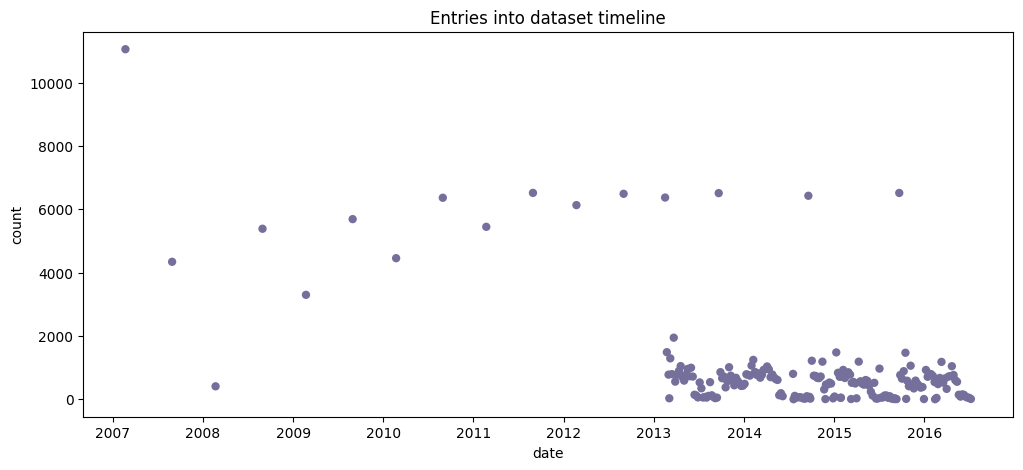

In [119]:
fig = plt.pyplot.figure(figsize=(12, 5))

ax = sns.scatterplot(player_att_entries_date, color="#756F9B", edgecolor='None')

ax.set(title='Entries into dataset timeline');

Entries are from 2007 to middle of 2016. Overtime, the entries became more frequent, but less entries were made.

#### Player attributes distributions

In [120]:
player_att_numerical = player_att_stats.columns

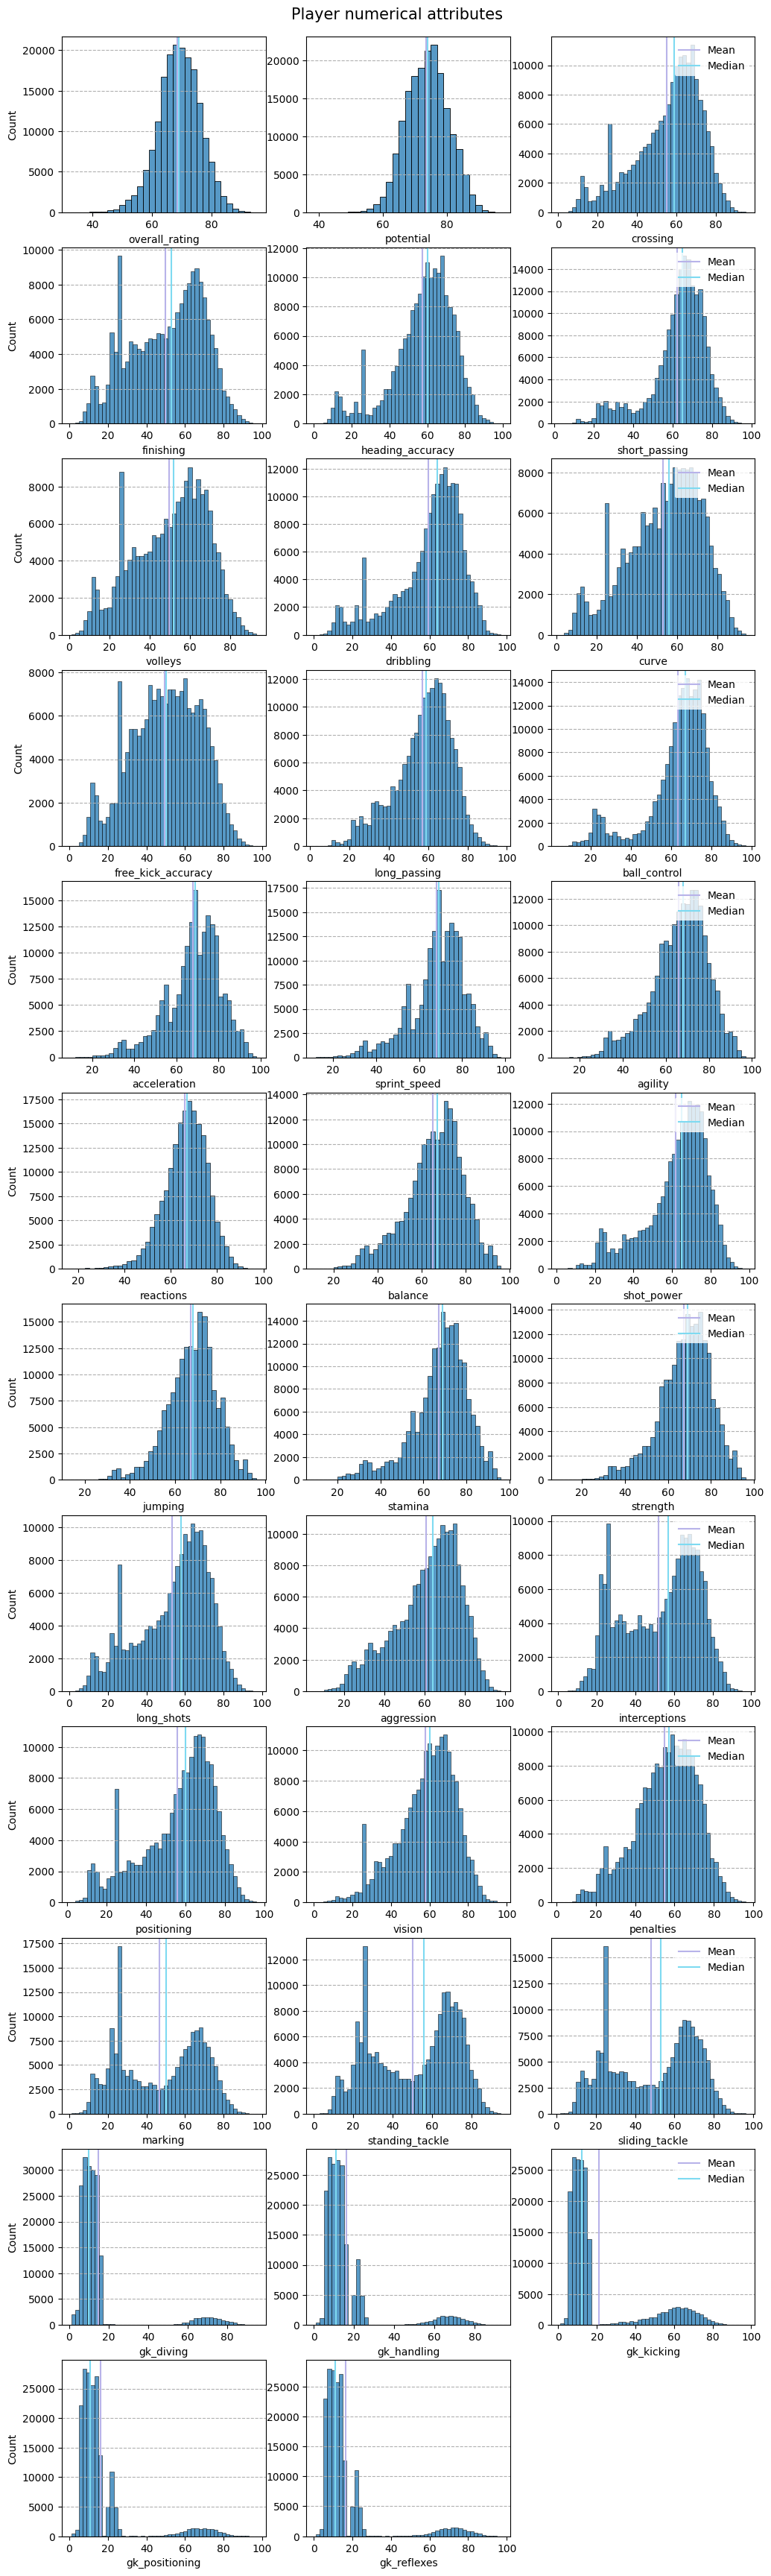

In [121]:
fig, axs = plt.pyplot.subplots(12, 3, figsize=(12, 39))
fig.suptitle('Player numerical attributes', fontsize=15)
fig.subplots_adjust(top=0.97)

i = 0
j = 0
for col in player_att_numerical:
    if i == 3:
        i = 0
        j += 1

    ax = histplot_f(player_att.loc[:, col], binwidth=2, ax=axs[j, i])

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    # Leaving only right most legends
    if i == 2:
        pass
    else:
        ax.get_legend().set_visible(False)

    i += 1


# Deleting empty ax
while i < 3:
    fig.delaxes(axs[j, i])
    i += 1

plt.pyplot.tight_layout;

Majority of distributions are approximately normal. There are some which are skewed to the left and some also are multimodal.

In [122]:
player_att_categorical = player_att.select_dtypes(include=['object']).columns
player_att_categorical

Index(['preferred_foot', 'attacking_work_rate', 'defensive_work_rate'], dtype='object')

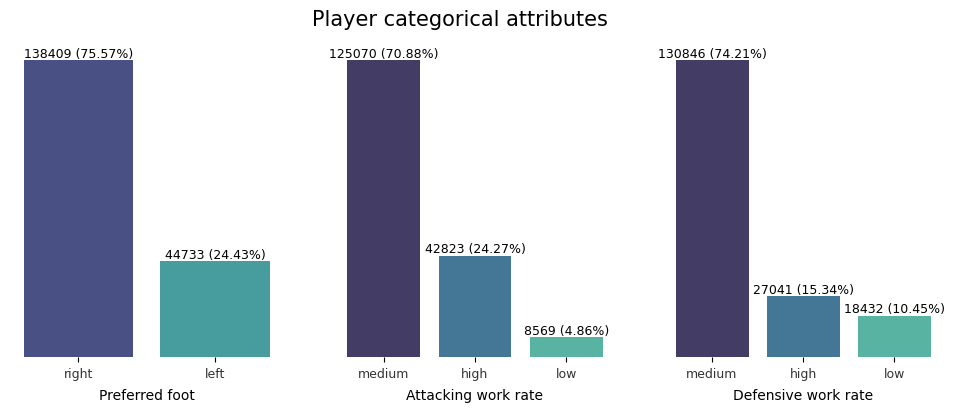

In [123]:
fig, axs = plt.pyplot.subplots(1, 3, figsize=(12, 4))
fig.suptitle('Player categorical attributes', fontsize=15)
fig.subplots_adjust(top=0.89)

ax0 = bar_plot_f_perc(player_att.preferred_foot.value_counts(), palet='mako', ax=axs[0])
ax0.set_title('Preferred foot', fontsize=10, y=-0.16)

ax0 = bar_plot_f_perc(player_att.attacking_work_rate.value_counts(), palet='mako', ax=axs[1])
ax0.set_title('Attacking work rate', fontsize=10, y=-0.16)

ax0 = bar_plot_f_perc(player_att.defensive_work_rate.value_counts(), palet='mako', ax=axs[2])
ax0.set_title('Defensive work rate', fontsize=10, y=-0.16)

plt.pyplot.tight_layout
sns.despine(left=True, bottom=True)

Majority of players prefer right foot to left. Also, majority of players have medium attacking and defensive work rates.

#### Player attributes correlation

In [124]:
player_att_num_feat = player_att.iloc[:, 3:].select_dtypes(include=['number'])

In [125]:
player_att_corr = player_att_num_feat.corr()

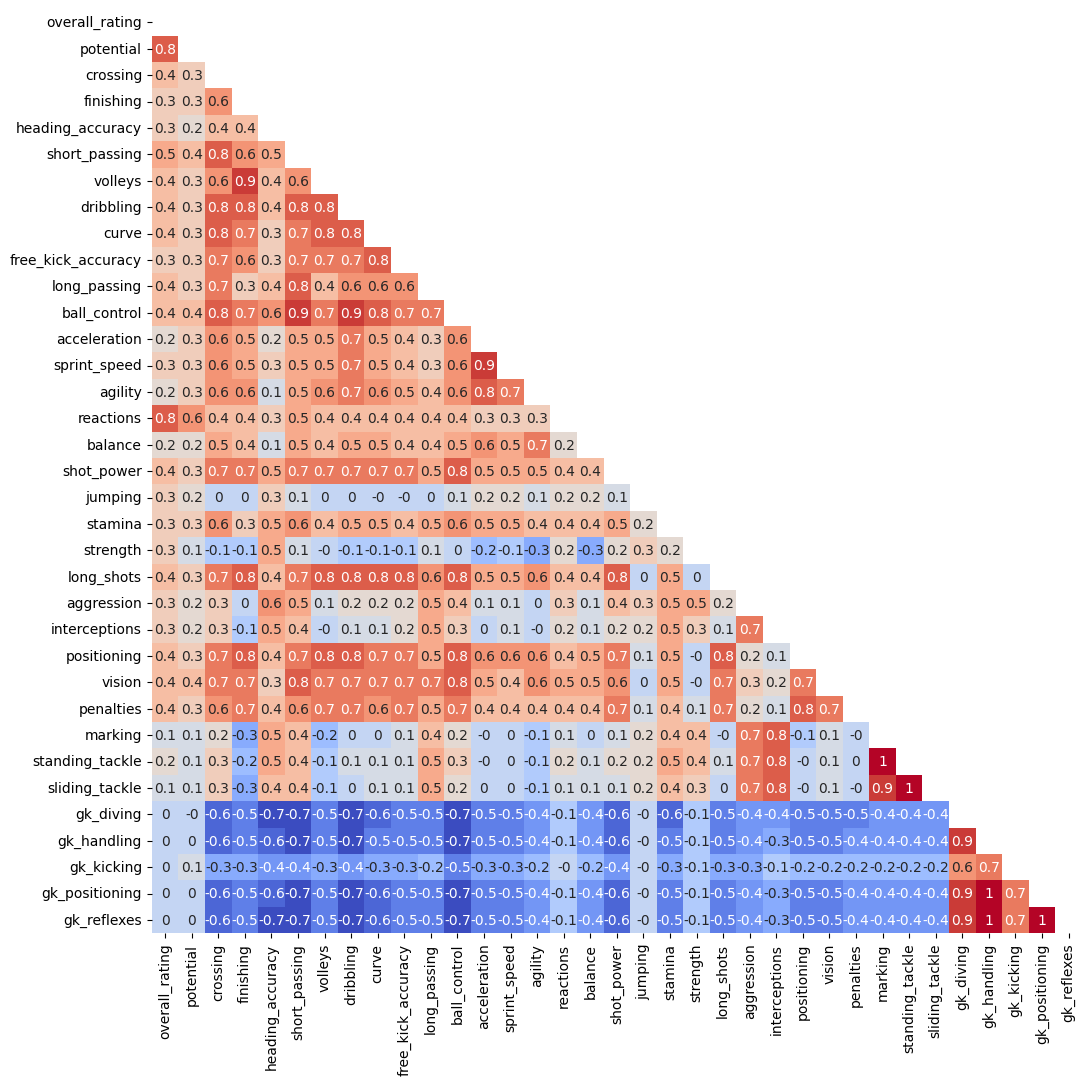

In [126]:
fig = plt.pyplot.figure(figsize=(12, 12))

# To make a triangle mask
mask = np.triu(np.ones_like(player_att_corr))

corr_plot = sns.heatmap(
    player_att_corr.round(1), cmap=sns.color_palette("coolwarm", as_cmap=True), cbar=False, annot=True, mask=mask
)

In this graph correlation coefficients are rounded to one decimal place. There are a lot of features which correlate well with each other, either positively or negatively. It can be taken into account, which features to select when making a model.

#### Player attributes outliers

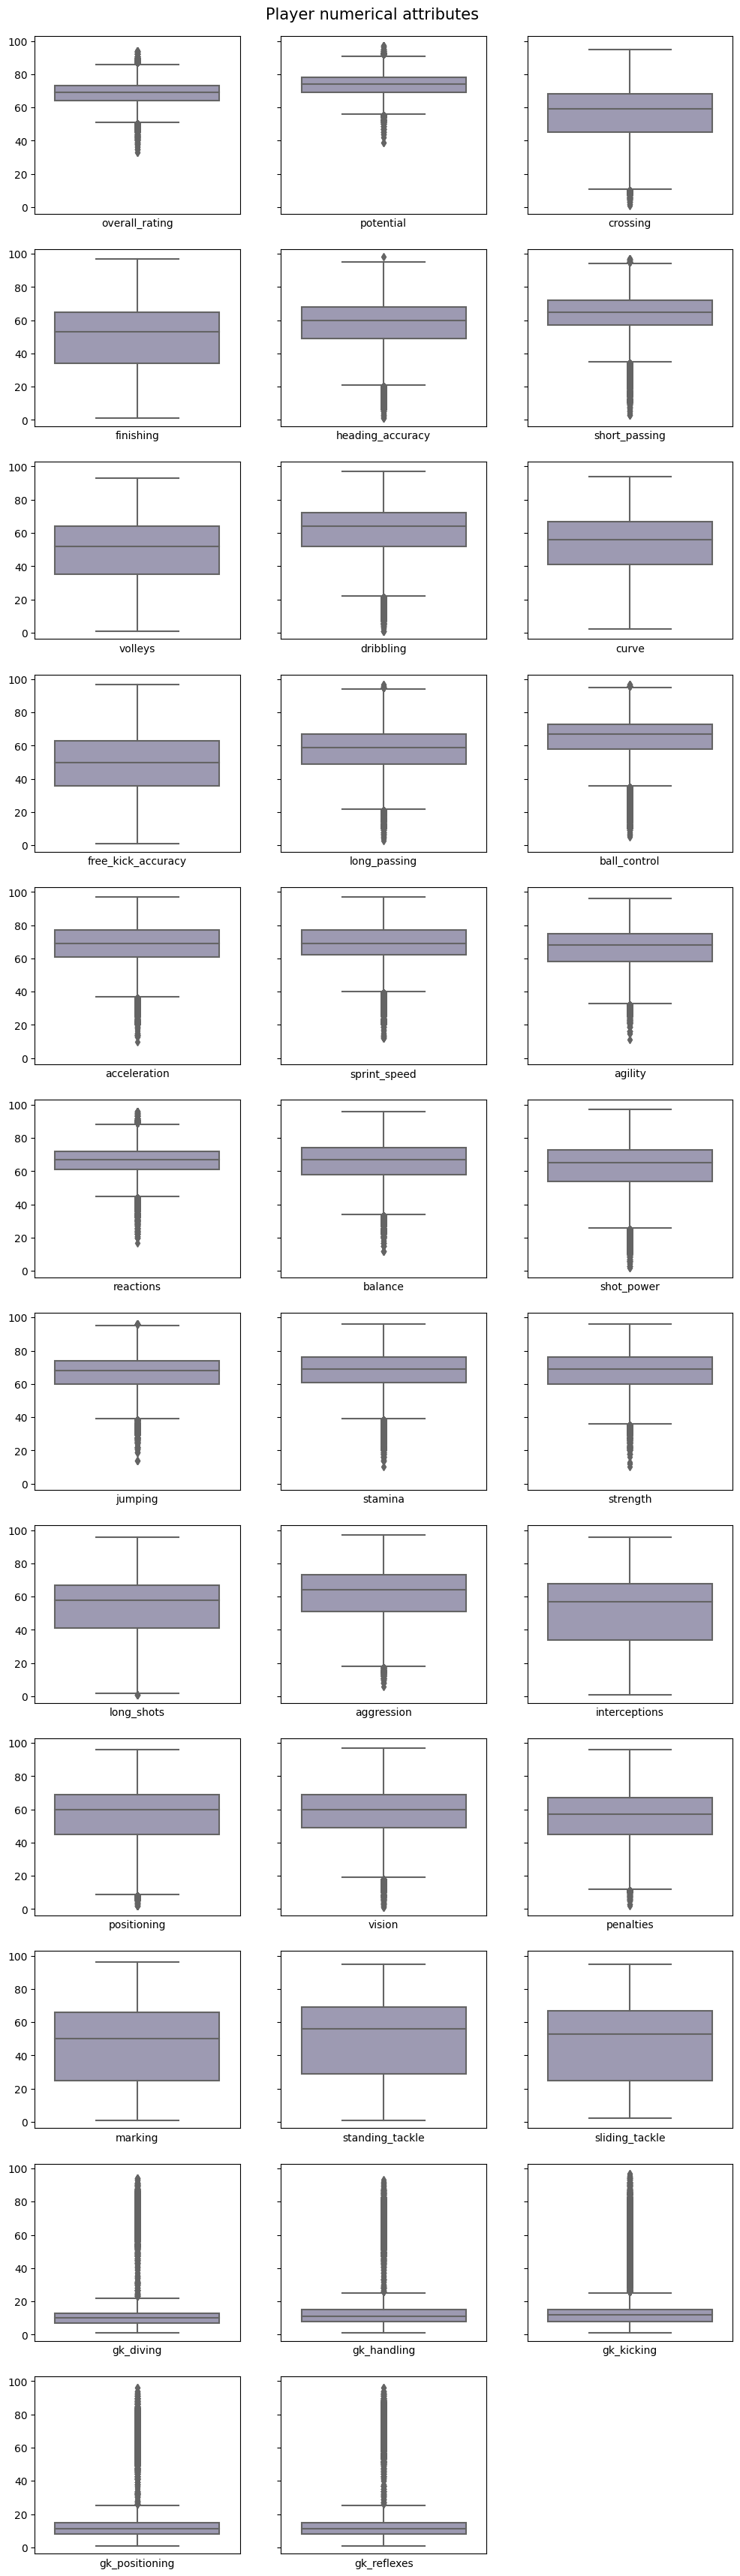

In [127]:
fig, axs = plt.pyplot.subplots(12, 3, sharey=True, figsize=(12, 39))
fig.suptitle('Player numerical attributes', fontsize=15)
fig.subplots_adjust(top=0.97)

i = 0
j = 0
for col in player_att_numerical:
    if i == 3:
        i = 0
        j += 1

    ax = sns.boxplot(player_att.loc[:, col], color="#9A96B6", ax=axs[j, i])
    ax.set(xlabel=col)
    ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    i += 1

# Deleting empty ax
while i < 3:
    fig.delaxes(axs[j, i])
    i += 1

plt.pyplot.tight_layout;

There are some attributes with no outliers at all (like finishing and volleys) and some attributes with a lot of outliers, like (gk positioning and gk reflexes).

In [128]:
player_att_out = outlier_f(player_att_num_feat)
print(f'There are {len(player_att_out)} players with outlier attributes.')

There are 55557 players with outlier attributes.


In [129]:
player_att_out_count = player_att_out.count(axis=0)
player_att_out_count

overall_rating         2383
potential               850
crossing               1389
finishing                 0
heading_accuracy       7633
short_passing         13199
volleys                   0
dribbling              9266
curve                     0
free_kick_accuracy        0
long_passing           2834
ball_control          15512
acceleration           5757
sprint_speed           6171
agility                2655
reactions              3699
balance                3853
shot_power             9249
jumping                3260
stamina                8550
strength               3307
long_shots                6
aggression              628
interceptions             0
positioning             440
vision                 1803
penalties               606
marking                   0
standing_tackle           0
sliding_tackle            0
gk_diving             15086
gk_handling           15002
gk_kicking            40196
gk_positioning        15019
gk_reflexes           15036
dtype: int64

There are a lot of entries with outlier attributes in various attributes.

## Match table

In [130]:
match.head()

,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_X1,home_player_X2,home_player_X3,home_player_X4,home_player_X5,home_player_X6,home_player_X7,home_player_X8,home_player_X9,home_player_X10,home_player_X11,away_player_X1,away_player_X2,away_player_X3,away_player_X4,away_player_X5,away_player_X6,away_player_X7,away_player_X8,away_player_X9,away_player_X10,away_player_X11,home_player_Y1,home_player_Y2,home_player_Y3,home_player_Y4,home_player_Y5,home_player_Y6,home_player_Y7,home_player_Y8,home_player_Y9,home_player_Y10,home_player_Y11,away_player_Y1,away_player_Y2,away_player_Y3,away_player_Y4,away_player_Y5,away_player_Y6,away_player_Y7,away_player_Y8,away_player_Y9,away_player_Y10,away_player_Y11,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11,goal,shoton,shotoff,foulcommit,card,cross,corner,possession,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.73,3.40,5.00,1.75,3.35,4.20,1.85,3.2,3.5,1.80,3.3,3.75,NaN,NaN,NaN,1.70,3.30,4.33,1.90,3.3,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.95,3.20,3.60,1.80,3.30,3.95,1.90,3.2,3.5,1.90,3.2,3.50,NaN,NaN,NaN,1.83,3.30,3.60,1.95,3.3,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,2.38,3.30,2.75,2.40,3.30,2.55,2.60,3.1,2.3,2.50,3.2,2.50,NaN,NaN,NaN,2.50,3.25,2.40,2.63,3.3,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.44,3.75,7.50,1.40,4.00,6.80,1.40,3.9,6.0,1.44,3.6,6.50,NaN,NaN,NaN,1.44,3.75,6.00,1.44,4.0,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,5.00,3.50,1.65,5.00,3.50,1.60,4.00,3.3,1.7,4.00,3.4,1.72,NaN,NaN,NaN,4.20,3.40,1.70,4.50,3.5,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [131]:
match['date'] = match.date.astype('datetime64[ns]')

In [132]:
# Country_id is the same as league_id, so it can be dropped.
match = match.drop(columns='country_id')

Home/away player X and Y are team line up with squad formation (X, Y coordinates). This information will not be used further in the dataset, therefore these columns are going to be dropped.

In [133]:
to_drop = match.loc[:, 'home_player_X1':'away_player_Y11'].columns
match = match.drop(columns=to_drop)
match.head()

,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11,goal,shoton,shotoff,foulcommit,card,cross,corner,possession,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,1,2008/2009,1,2008-08-17,492473,9987,9993,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.73,3.40,5.00,1.75,3.35,4.20,1.85,3.2,3.5,1.80,3.3,3.75,NaN,NaN,NaN,1.70,3.30,4.33,1.90,3.3,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
2,1,2008/2009,1,2008-08-16,492474,10000,9994,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.95,3.20,3.60,1.80,3.30,3.95,1.90,3.2,3.5,1.90,3.2,3.50,NaN,NaN,NaN,1.83,3.30,3.60,1.95,3.3,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
3,1,2008/2009,1,2008-08-16,492475,9984,8635,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,2.38,3.30,2.75,2.40,3.30,2.55,2.60,3.1,2.3,2.50,3.2,2.50,NaN,NaN,NaN,2.50,3.25,2.40,2.63,3.3,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
4,1,2008/2009,1,2008-08-17,492476,9991,9998,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.44,3.75,7.50,1.40,4.00,6.80,1.40,3.9,6.0,1.44,3.6,6.50,NaN,NaN,NaN,1.44,3.75,6.00,1.44,4.0,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
5,1,2008/2009,1,2008-08-16,492477,7947,9985,1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,5.00,3.50,1.65,5.00,3.50,1.60,4.00,3.3,1.7,4.00,3.4,1.72,NaN,NaN,NaN,4.20,3.40,1.70,4.50,3.5,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [134]:
match.iloc[:, 0:100].info()

<class 'pandas.core.frame.DataFrame'>
Index: 25979 entries, 1 to 25979
Data columns (total 69 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   league_id         25979 non-null  int64         
 1   season            25979 non-null  object        
 2   stage             25979 non-null  int64         
 3   date              25979 non-null  datetime64[ns]
 4   match_api_id      25979 non-null  int64         
 5   home_team_api_id  25979 non-null  int64         
 6   away_team_api_id  25979 non-null  int64         
 7   home_team_goal    25979 non-null  int64         
 8   away_team_goal    25979 non-null  int64         
 9   home_player_1     24755 non-null  float64       
 10  home_player_2     24664 non-null  float64       
 11  home_player_3     24698 non-null  float64       
 12  home_player_4     24656 non-null  float64       
 13  home_player_5     24663 non-null  float64       
 14  home_player_6     24654 non

In [135]:
np.sort(match.stage.unique())

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38], dtype=int64)

A Stage is a collection of rounds within a Tournament. Stages can either be a complete group stage, e.g. one round within a Tournament or a collection of rounds in a knockout cup. The English Premier League, Spain's La Liga, Italy's Serie A and France's Ligue 1 – the other leagues considered Europe's "big five" – all consist of 20 teams, resulting in 38 rounds of fixtures.

Sources: https://www.bundesliga.com/en/faq/what-are-the-rules-and-regulations-of-soccer/how-is-european-soccer-structured-with-leagues-and-cup-competitions-10568 ; https://help.leaguerepublic.com/en/articles/634280-what-are-stages-rounds-ties-and-legs .

In [136]:
query = '''
SELECT c.league, MAX(m.stage) highest_stage
FROM match m
JOIN country_league c ON m.league_id = c.id
GROUP BY c.league
'''

db.sql(query).df()

,league,highest_stage
0,Italy Serie A,38
1,Scotland Premier League,38
2,Spain LIGA BBVA,38
3,Belgium Jupiler League,34
4,Portugal Liga ZON Sagres,34
5,France Ligue 1,38
6,England Premier League,38
7,Germany 1. Bundesliga,34
8,Netherlands Eredivisie,34
9,Poland Ekstraklasa,30


- Goal column has information about made goals, which team and players. Player1 is the API ID of player who scores, player2 - player who assists. Goal type include: n - goal, p - penalty, dg - goal disallowed, o - own goal, npm - penalty saved by the goalkeeper, psm - missed penalty, rp - retake penalty. Only "n", "o" and "p" are considered as valid goals.
- Shoton is a shot on target is defined as an intentional shot that goes into the net, or would have gone into the net if not for being stopped by the goalkeeper or the last defender. Shoton column doesn't contain goal information in this dataset, only if attempt was made and blocked.
- Shotoff is a deliberate attempt to score that misses the target, without contact from a player diverting the ball from on target to off target. A shot hitting the frame of the Goal is classified as a Shot Off Target unless the ball subsequently enters the net. A Blocked Shot is not classified as a Shot Off Target. 
- Foulcommit contains what kind of foul, card type for the foul, elapsed time, who was fouled and who committed the fault.
- Card contains who gets the card, card type and elapsed time. Cards are collected, when a player has committed an offense, as yellow, 2nd yellow or red card. 
- Cross is a ball played from a wide position targeting a teammate(s) in a central area within proximity to the Goal. The delivery must have an element of lateral movement from a wider position to more central area in front of Goal.
- Corner - A corner kick is awarded when the whole of the ball passes over the goal line, on the ground or in the air, having last touched a player of the defending team, and a goal is not scored. Contains which team and which player plays the corner.
- Possession - contains who possesses the ball: homepos (home team possession of ball up to this time), awaypos (away team possession of ball up to this time).

Sources: https://www.kaggle.com/datasets/jiezi2004/soccer ; https://www.statsperform.com/opta-event-definitions/ ; https://www.thefa.com/football-rules-governance/lawsandrules/laws/football-11-11/law-17---the-corner-kick .

### Betting odds

Odds serve as a representation of the relationship between your wager and the potential winnings for a specific outcome. These odds are determined by bookmakers – and if you decide to bet on a particular outcome, you will use these odds to calculate your potential payout. 

Typically, odds are presented as fractions (eg, 2/1), but they can also be displayed as decimals (3.0 is equivalent to 2/1 as a fractional price). The bookmaker you are betting with allows you the flexibility to choose how odds are presented. For instance, if the odds for a game are 2/1, you will receive £2 for every £1 you bet, in addition to having your initial stake returned. Alternatively, placing the same bet with decimal odds of 3.0 means you will receive a total return of £3 for every £1 wagered. (Source: https://www.telegraph.co.uk/betting/sports-guides/football-betting-guide/)

From 86th column there are betting odds:
- B365H = Bet365 home win odds
- B365D = Bet365 draw odds
- B365A = Bet365 away win odds
- BSH = Blue Square home win odds
- BSD = Blue Square draw odds
- BSA = Blue Square away win odds
- BWH = Bet&Win home win odds
- BWD = Bet&Win draw odds
- BWA = Bet&Win away win odds
- GBH = Gamebookers home win odds
- GBD = Gamebookers draw odds
- GBA = Gamebookers away win odds
- IWH = Interwetten home win odds
- IWD = Interwetten draw odds
- IWA = Interwetten away win odds
- LBH = Ladbrokes home win odds
- LBD = Ladbrokes draw odds
- LBA = Ladbrokes away win odds
- PSH = Pinnacle Sports home win odds
- PSD = Pinnacle Sports draw odds
- PSA = Pinnacle Sports away win odds
- SJH = Stan James home win odds
- SJD = Stan James draw odds
- SJA = Stan James away win odds
- VCH = VC Bet home win odds
- VCD = VC Bet draw odds
- VCA = VC Bet away win odds
- WHH = William Hill home win odds
- WHD = William Hill draw odds
- WHA = William Hill away win odds

Source: https://github.com/woobe/footballytics/blob/master/data/notes.txt

In [137]:
betting_odds = match.loc[:, 'B365H':]
betting_odds_stats = betting_odds.describe()
betting_odds_stats

,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
count,22592.000000,22592.000000,22592.000000,22575.000000,22575.000000,22575.000000,22520.000000,22520.000000,22520.000000,22556.000000,22556.000000,22556.000000,11168.000000,11168.000000,11168.000000,22571.000000,22571.000000,22571.000000,17097.000000,17097.000000,17097.000000,22568.000000,22568.000000,22568.000000,14162.000000,14162.000000,14162.000000,14161.000000,14161.000000,14161.000000
mean,2.628818,3.839684,4.662222,2.559245,3.747597,4.396949,2.467613,3.608932,4.150575,2.536202,3.711740,4.385351,2.816447,4.132324,4.972744,2.578737,3.665295,4.482585,2.566061,3.755879,4.622343,2.668107,3.899048,4.840281,2.498764,3.648189,4.353097,2.497894,3.660742,4.405663
std,1.794463,1.118269,3.730104,1.637983,1.033468,3.292265,1.445642,0.803582,2.858912,1.640648,1.003846,3.398285,2.187924,1.516680,4.475458,1.685725,0.958069,3.585083,1.655535,0.999582,3.632164,1.928753,1.248221,4.318338,1.489299,0.867440,3.010189,1.507793,0.868272,3.189814
min,1.040000,1.400000,1.080000,1.030000,1.650000,1.100000,1.030000,1.500000,1.100000,1.040000,1.400000,1.100000,1.040000,2.200000,1.090000,1.020000,1.020000,1.080000,1.040000,1.400000,1.100000,1.030000,1.620000,1.080000,1.050000,1.450000,1.120000,1.040000,1.330000,1.120000
25%,1.670000,3.300000,2.500000,1.650000,3.200000,2.500000,1.650000,3.200000,2.500000,1.670000,3.200000,2.500000,1.720000,3.410000,2.560000,1.670000,3.200000,2.500000,1.670000,3.250000,2.500000,1.700000,3.300000,2.550000,1.670000,3.200000,2.500000,1.670000,3.250000,2.500000
50%,2.100000,3.500000,3.500000,2.100000,3.400000,3.400000,2.100000,3.300000,3.300000,2.100000,3.400000,3.300000,2.200000,3.640000,3.610000,2.150000,3.300000,3.400000,2.100000,3.400000,3.500000,2.150000,3.500000,3.500000,2.100000,3.300000,3.400000,2.100000,3.400000,3.400000
75%,2.800000,4.000000,5.250000,2.750000,3.800000,5.000000,2.600000,3.700000,4.600000,2.700000,3.750000,5.000000,2.980000,4.230000,5.410000,2.750000,3.750000,5.000000,2.750000,3.800000,5.250000,2.800000,4.000000,5.400000,2.650000,3.750000,5.000000,2.620000,3.750000,5.000000
max,26.000000,17.000000,51.000000,34.000000,19.500000,51.000000,20.000000,11.000000,25.000000,26.000000,19.000000,51.000000,36.000000,29.000000,47.500000,26.000000,17.000000,51.000000,23.000000,15.000000,41.000000,36.000000,26.000000,67.000000,21.000000,11.000000,34.000000,17.000000,13.000000,34.000000


This dataset includes decimal odds, which are most commonly present in Europe, and they stand for the total payout, including the original stake. 
Higher the odds, the bigger the payout, therefore the lower the probability of the event happening (home win, away win or draw).

### Null and duplicates

In [138]:
query = '''
SELECT *, COUNT(*)
FROM match
GROUP BY *
HAVING COUNT(*) > 1
'''

len(db.sql(query).df())

0

There are no obvious duplicates in the dataset.

In [139]:
match.columns.duplicated().any()

False

In [140]:
match.isnull().sum()

league_id               0
season                  0
stage                   0
date                    0
match_api_id            0
home_team_api_id        0
away_team_api_id        0
home_team_goal          0
away_team_goal          0
home_player_1        1224
home_player_2        1315
home_player_3        1281
home_player_4        1323
home_player_5        1316
home_player_6        1325
home_player_7        1227
home_player_8        1309
home_player_9        1273
home_player_10       1436
home_player_11       1555
away_player_1        1234
away_player_2        1278
away_player_3        1293
away_player_4        1321
away_player_5        1335
away_player_6        1313
away_player_7        1235
away_player_8        1341
away_player_9        1328
away_player_10       1441
away_player_11       1554
goal                11762
shoton              11762
shotoff             11762
foulcommit          11762
card                11762
cross               11762
corner              11762
possession  

There is a moderate amount of home/away players' coordinates and players ids, betting odds, goal, shoton, shotoff and etc. information missing, however all of country, league, home/away team ids are in place. Also, numbers for home team goals, away team goals, seasons, stages and dates seem to be there.

### Data exploration

In [141]:
query = """
SELECT season, COUNT() count
FROM match
GROUP BY season 
ORDER BY season
"""

match_entries_season = db.sql(query).df().set_index('season').squeeze()
match_entries_season

season
2008/2009    3326
2009/2010    3230
2010/2011    3260
2011/2012    3220
2012/2013    3260
2013/2014    3032
2014/2015    3325
2015/2016    3326
Name: count, dtype: int64

In [142]:
mean_matches_season = round(match_entries_season.mean(), 0)
mean_matches_season

3247.0

In [143]:
mean_matches_season_sem = round(match_entries_season.sem(), 0)
mean_matches_season_sem

34.0

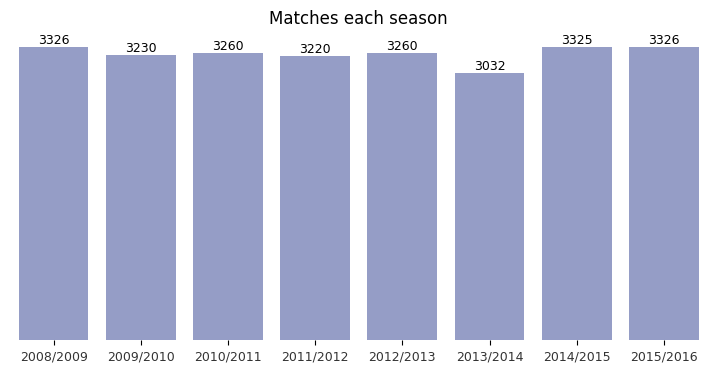

In [144]:
fig = plt.pyplot.figure(figsize=(9, 4))

ax = bar_plot_f(match_entries_season, name='Matches each season', color='#8D97CE')

sns.despine(left=True, bottom=True)

On average there are 3247 ± 34 matches each season.

In [145]:
query = '''
SELECT c.league, m.season, m.stage,
       th.team_long_name home_team, ta.team_long_name away_team,
       m.home_team_goal, m.away_team_goal, 
       m.home_team_goal + m.away_team_goal AS total_goals
FROM match m
JOIN country_league c ON m.league_id = c.id
JOIN team th ON m.home_team_api_id = th.team_api_id
JOIN team ta ON m.away_team_api_id = ta.team_api_id
'''

league_goals = db.sql(query).df()
league_goals.head()

,league,season,stage,home_team,away_team,home_team_goal,away_team_goal,total_goals
0,Belgium Jupiler League,2008/2009,1,KRC Genk,Beerschot AC,1,1,2
1,Belgium Jupiler League,2008/2009,1,KSV Cercle Brugge,RSC Anderlecht,0,3,3
2,Belgium Jupiler League,2008/2009,1,KAA Gent,RAEC Mons,5,0,5
3,Belgium Jupiler League,2008/2009,1,FCV Dender EH,Standard de Liège,1,3,4
4,Belgium Jupiler League,2008/2009,1,KV Mechelen,Club Brugge KV,1,1,2


In [146]:
query = '''
SELECT league, season, COUNT() matches
FROM league_goals
GROUP BY league, season 
ORDER BY league, season
'''

league_games_season = db.sql(query).df()
league_games_season_median = league_games_season.groupby('league').matches.median()

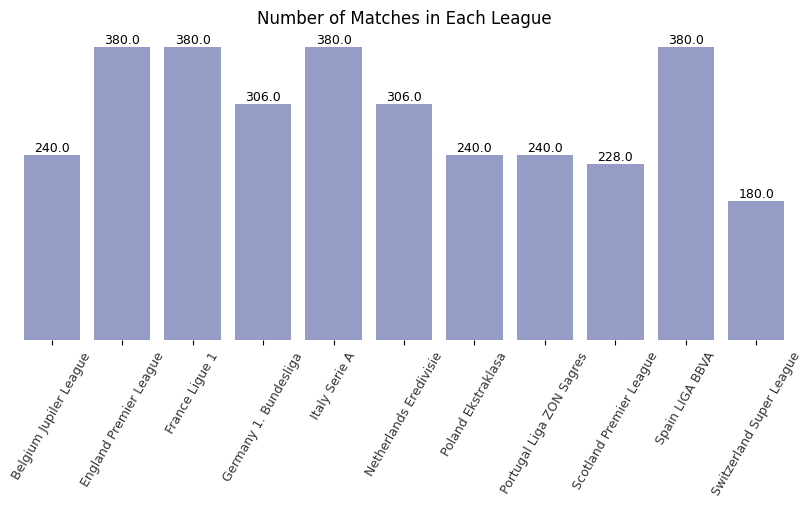

In [147]:
fig = plt.pyplot.figure(figsize=(10, 4))

ax = bar_plot_f(league_games_season_median, name='Number of Matches in Each League', color='#8D97CE')
ax.tick_params(axis='x', rotation=60)

sns.despine(left=True, bottom=True)

This bar graph represents the median of matches held in each league over the seasons. In English Premier League, France Ligue 1, Italy Serie A and Spain LIGA BBVA there are the most matches held, while in Switzerland Super League there are the least.

#### Team goals

In [148]:
query = '''
SELECT AVG(home_team_goal) average_home_team_goals,
       AVG(away_team_goal) average_away_team_goals, 
       AVG(total_goals) average_goals_per_match,
       SUM(home_team_goal) total_home_team_goals, 
       SUM(away_team_goal) total_away_team_goals,
       SUM(total_goals) total_goals
FROM league_goals
'''

db.sql(query).df()

,average_home_team_goals,average_away_team_goals,average_goals_per_match,total_home_team_goals,total_away_team_goals,total_goals
0,1.544594,1.160938,2.705531,40127.0,30160.0,70287.0


In [149]:
query = '''
SELECT *
FROM league_goals
WHERE home_team_goal = (SELECT MAX(home_team_goal) FROM league_goals)
'''

db.sql(query).df()

,league,season,stage,home_team,away_team,home_team_goal,away_team_goal,total_goals
0,Netherlands Eredivisie,2010/2011,10,PSV,Feyenoord,10,0,10
1,Spain LIGA BBVA,2015/2016,16,Real Madrid CF,Rayo Vallecano,10,2,12


In [150]:
query = '''
SELECT *
FROM league_goals
WHERE away_team_goal = (SELECT MAX(away_team_goal) FROM league_goals)
'''

db.sql(query).df()

,league,season,stage,home_team,away_team,home_team_goal,away_team_goal,total_goals
0,France Ligue 1,2015/2016,30,ES Troyes AC,Paris Saint-Germain,0,9,9


In [151]:
query = '''
SELECT *
FROM league_goals
WHERE total_goals = (SELECT MAX(total_goals) FROM league_goals)
'''

db.sql(query).df()

,league,season,stage,home_team,away_team,home_team_goal,away_team_goal,total_goals
0,Scotland Premier League,2009/2010,37,Motherwell,Hibernian,6,6,12
1,Spain LIGA BBVA,2015/2016,16,Real Madrid CF,Rayo Vallecano,10,2,12


#### League goals

In [152]:
query = '''
SELECT league,
       AVG(home_team_goal) average_home_team_goals,
       AVG(away_team_goal) average_away_team_goals, 
       AVG(total_goals) average_goals_per_match,
       SUM(home_team_goal) total_home_team_goals, 
       SUM(away_team_goal) total_away_team_goals,
       SUM(total_goals) total_goals
FROM league_goals
GROUP BY 1
'''

league_goals_avg = db.sql(query).df()
league_goals_avg.head()

,league,average_home_team_goals,average_away_team_goals,average_goals_per_match,total_home_team_goals,total_away_team_goals,total_goals
0,France Ligue 1,1.402961,1.040132,2.443092,4265.0,3162.0,7427.0
1,England Premier League,1.550987,1.159539,2.710526,4715.0,3525.0,8240.0
2,Germany 1. Bundesliga,1.626634,1.274918,2.901552,3982.0,3121.0,7103.0
3,Netherlands Eredivisie,1.779820,1.301062,3.080882,4357.0,3185.0,7542.0
4,Poland Ekstraklasa,1.394792,1.030208,2.425000,2678.0,1978.0,4656.0


In [153]:
# Creating dataframe to draw a graph
part1 = league_goals_avg.loc[:, ['league', 'average_home_team_goals', 'total_home_team_goals']]
part1['tmp'] = 'home'
part2 = league_goals_avg.loc[:, ['league', 'average_away_team_goals', 'total_away_team_goals']]
part2['tmp'] = 'away'
part3 = league_goals_avg.loc[:, ['league', 'average_goals_per_match', 'total_goals']]
part3['tmp'] = 'total'

new_columns = ["league", "average_goals", 'total_goals', 'attribute']
part1.columns = new_columns
part2.columns = new_columns
part3.columns = new_columns

league_goals_avg_concat = pd.concat([part1, part2, part3], ignore_index=True)
league_goals_avg_concat.head()

,league,average_goals,total_goals,attribute
0,France Ligue 1,1.402961,4265.0,home
1,England Premier League,1.550987,4715.0,home
2,Germany 1. Bundesliga,1.626634,3982.0,home
3,Netherlands Eredivisie,1.779820,4357.0,home
4,Poland Ekstraklasa,1.394792,2678.0,home


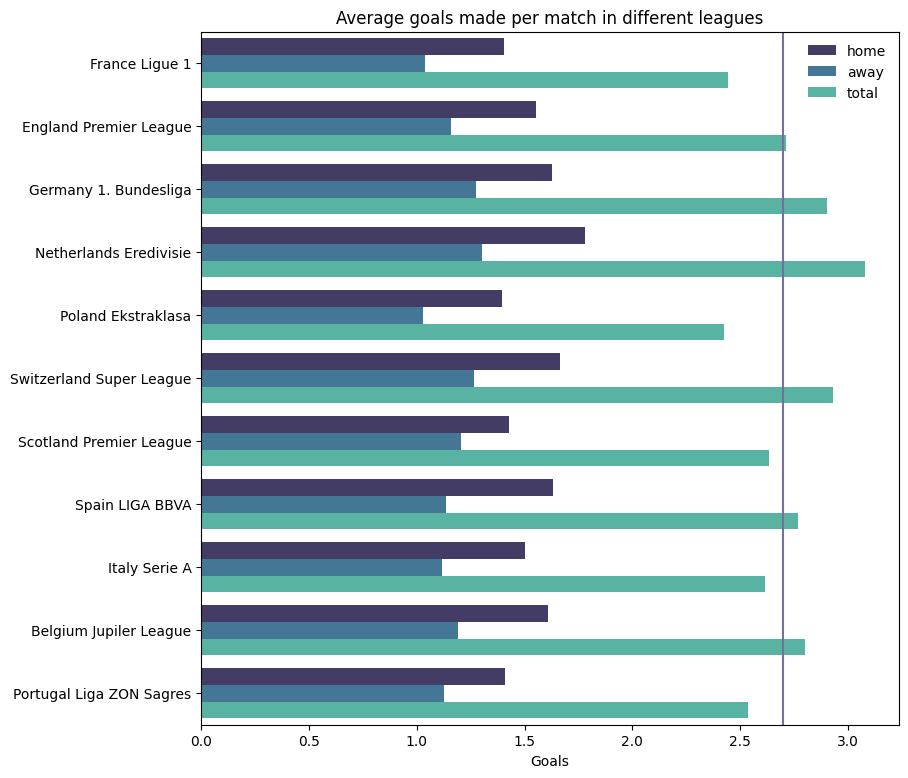

In [154]:
fig = plt.pyplot.figure(figsize=(9, 9))

ax = sns.barplot(league_goals_avg_concat, x="average_goals", y="league", palette='mako', hue="attribute")
ax.set(title='Average goals made per match in different leagues', ylabel='', xlabel='Goals')
ax.legend(title='', edgecolor='none')
ax.axvline(x=2.7, color='#756F9B', label='Average total');

Purple line shows how many goals are made on average over all leagues. There are most goals per match on average in Netherlands Eredivisie league, and least in Poland Ekstraklasa. 

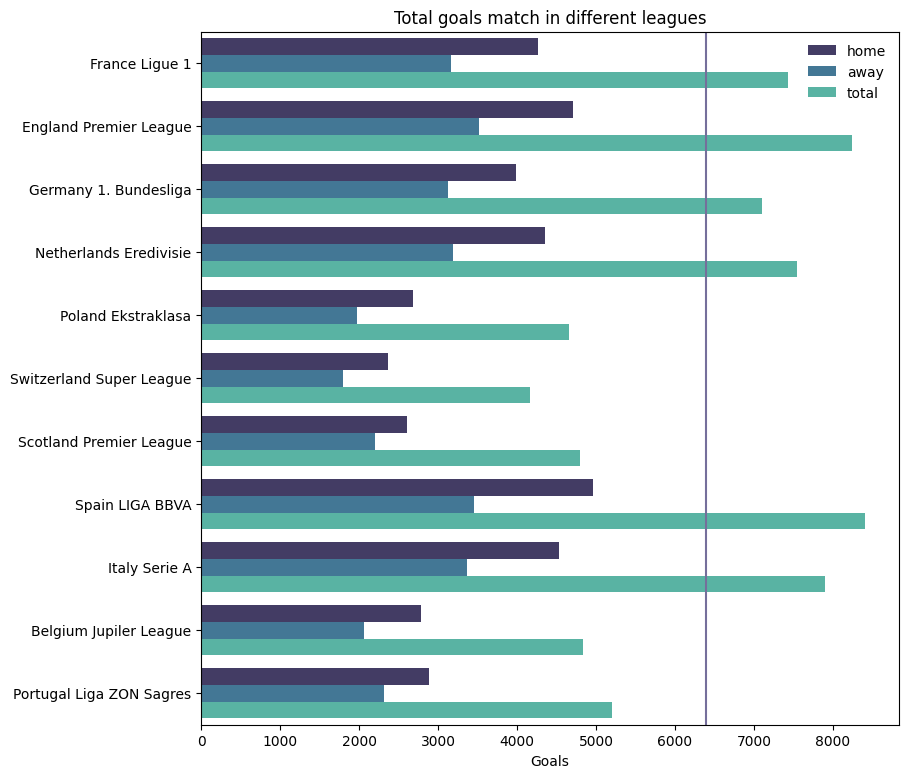

In [155]:
fig = plt.pyplot.figure(figsize=(9, 9))

ax = sns.barplot(league_goals_avg_concat, x="total_goals", y="league", palette='mako', hue="attribute")
ax.set(title='Total goals match in different leagues', ylabel='', xlabel='Goals')
ax.legend(title='', edgecolor='none')
ax.axvline(x=league_goals_avg.total_goals.mean(), color='#756F9B', label='Average total');

Purple line shows how many goals were made on average over all leagues. Most goals over 2008/2009 - 2015/2016 seasons were made on Spain LIGA BBVA league, least - in Switzerland Super League. This might be because there is least amount of matches in Switzerland Super League.

#### Season goals

In [156]:
query = '''
SELECT season,
       AVG(home_team_goal) average_home_team_goals,
       AVG(away_team_goal) average_away_team_goals, 
       AVG(total_goals) average_goals_per_match,
       SUM(home_team_goal) total_home_team_goals, 
       SUM(away_team_goal) total_away_team_goals,
       SUM(total_goals) total_goals
FROM league_goals
GROUP BY 1
ORDER BY 1
'''

season_goals_avg = db.sql(query).df()
season_goals_avg

,season,average_home_team_goals,average_away_team_goals,average_goals_per_match,total_home_team_goals,total_away_team_goals,total_goals
0,2008/2009,1.505412,1.101924,2.607336,5007.0,3665.0,8672.0
1,2009/2010,1.541176,1.131269,2.672446,4978.0,3654.0,8632.0
2,2010/2011,1.548466,1.135276,2.683742,5048.0,3701.0,8749.0
3,2011/2012,1.572671,1.143789,2.716460,5064.0,3683.0,8747.0
4,2012/2013,1.550000,1.222699,2.772699,5053.0,3986.0,9039.0
5,2013/2014,1.578826,1.187995,2.766821,4787.0,3602.0,8389.0
6,2014/2015,1.520301,1.155489,2.675789,5055.0,3842.0,8897.0
7,2015/2016,1.543897,1.210764,2.754660,5135.0,4027.0,9162.0


In [157]:
# Creating dataframe to draw a graph
part1 = season_goals_avg.loc[:, ['season', 'average_home_team_goals', 'total_home_team_goals']]
part1['tmp'] = 'home'
part2 = season_goals_avg.loc[:, ['season', 'average_away_team_goals', 'total_away_team_goals']]
part2['tmp'] = 'away'
part3 = season_goals_avg.loc[:, ['season', 'average_goals_per_match', 'total_goals']]
part3['tmp'] = 'total'

new_columns = ["season", "average_goals", 'total_goals', 'attribute']
part1.columns = new_columns
part2.columns = new_columns
part3.columns = new_columns

season_goals_avg_concat = pd.concat([part1, part2, part3], ignore_index=True)
season_goals_avg_concat.head()

,season,average_goals,total_goals,attribute
0,2008/2009,1.505412,5007.0,home
1,2009/2010,1.541176,4978.0,home
2,2010/2011,1.548466,5048.0,home
3,2011/2012,1.572671,5064.0,home
4,2012/2013,1.550000,5053.0,home


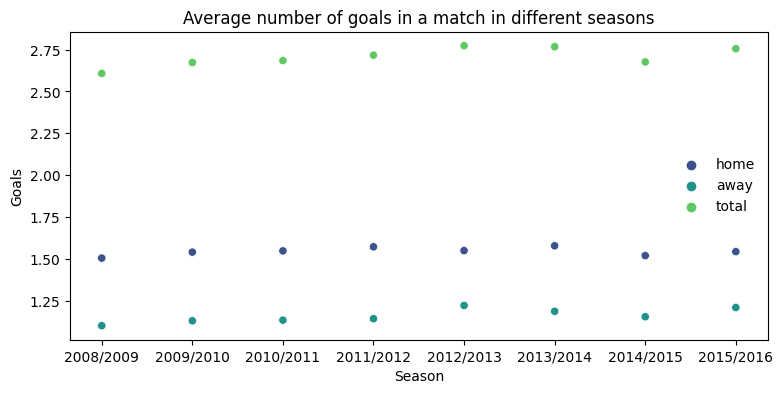

In [158]:
fig = plt.pyplot.figure(figsize=(9, 4))

ax = sns.scatterplot(season_goals_avg_concat, x="season", y="average_goals", palette='viridis', hue="attribute")
ax.set(title='Average number of goals in a match in different seasons', ylabel='Goals', xlabel='Season')
ax.legend(title='', edgecolor='none');

Average amount of goals scored in a match each season is similar. Also, on average there are more goals scored by a home team.

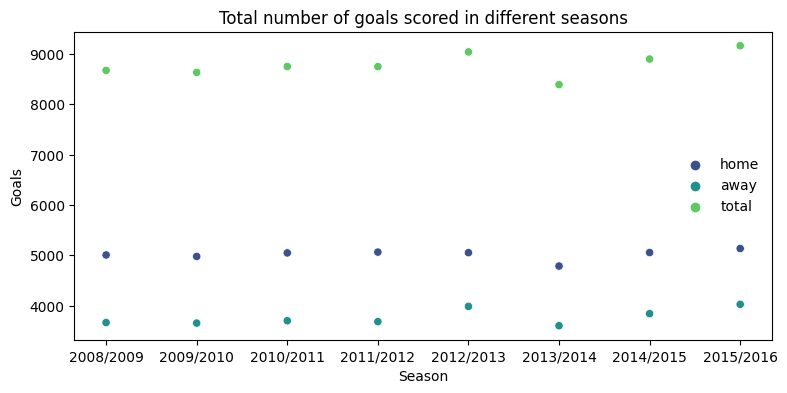

In [159]:
fig = plt.pyplot.figure(figsize=(9, 4))

ax = sns.scatterplot(season_goals_avg_concat, x="season", y="total_goals", palette='viridis', hue="attribute")
ax.set(title='Total number of goals scored in different seasons', ylabel='Goals', xlabel='Season')
ax.legend(title='', edgecolor='none');

Total amount of goals scored each season is also similar.

#### Stage goals

In [160]:
query = '''
SELECT stage,
       AVG(home_team_goal) avg_home_goals,
       AVG(away_team_goal) avg_away_goals 
FROM league_goals
GROUP BY 1
ORDER BY 1
'''

stage_goals_avg = db.sql(query).df()
stage_goals_avg.head()

,stage,avg_home_goals,avg_away_goals
0,1,1.433784,1.151351
1,2,1.539189,1.183784
2,3,1.463514,1.145946
3,4,1.593243,1.143243
4,5,1.441892,1.133784


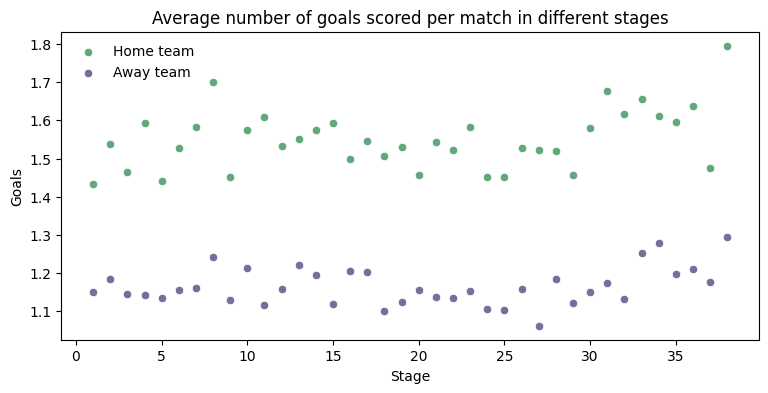

In [161]:
fig = plt.pyplot.figure(figsize=(9, 4))

ax1 = sns.scatterplot(stage_goals_avg, x="stage", y="avg_home_goals", color='#62A87C')
ax1 = sns.scatterplot(stage_goals_avg, x="stage", y="avg_away_goals", color="#756F9B")
ax1.set(title='Average number of goals scored per match in different stages', ylabel='Goals', xlabel='Stage')
ax1.legend(title='', labels=['Home team', 'Away team'], edgecolor='none');

There seems to be slight tendency to have more goals at later stages, but that is likely due to penalties, as the game cannot end in a draw.

In [162]:
stage_goals_avg_corr = stage_goals_avg.corr()

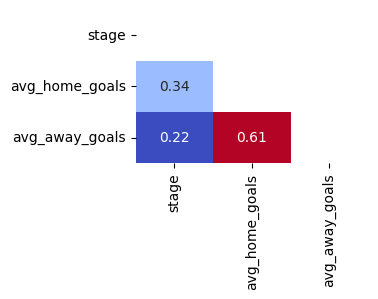

In [163]:
fig = plt.pyplot.figure(figsize=(3, 2))

# To make a triangle mask
mask = np.triu(np.ones_like(stage_goals_avg_corr))

corr_plot = sns.heatmap(
    stage_goals_avg_corr, cmap=sns.color_palette("coolwarm", as_cmap=True), cbar=False, annot=True, mask=mask
)

There seems to be weak/moderate positive correlation between stage and goals made. There also is a positive correlation between how many goals does the home team and away team make.

#### Top Scorers

In [164]:
# get all tags in xml
def getTags(xMLcolumnNm):
    elemList = []
    # iterate each row in the XML column
    for index, row in match[pd.notnull(match[xMLcolumnNm])].iterrows():
        # read in xml data
        tree = ET.ElementTree(ET.fromstring(row[xMLcolumnNm]))
        for elem in tree.iter():
            elemList.append(elem.tag)  # append tag name

    # remove duplicates of tag names
    return list(set(elemList))


# parse all information from XML column
def parseXMLData(xMLcolumnNm):
    tags = getTags(xMLcolumnNm)  # get a list of all tags

    tagLists = {}  # host all other tags
    pos = []
    otherList = {'match_id': [], 'pos_x': [], 'pos_y': []}  # host match id

    for tag in tags:
        tagLists[tag] = []  # initiate tag lists

    for index, row in match[pd.notnull(match[xMLcolumnNm])].iterrows():
        game_id = row['match_api_id']  # this helps identify match
        # rea-in XML data
        tree = ET.ElementTree(ET.fromstring(row[xMLcolumnNm]))
        root = tree.getroot()

        for event in root.findall('value'):
            otherList['match_id'].append(game_id)
            for tag in tags:
                if event.find(tag) is None:
                    tagLists[tag].append(None)
                else:
                    tagLists[tag].append(event.find(tag).text)

            # get position information
            if event.find('coordinates') is None:
                pos.append(None)
                pos.append(None)
            else:
                for value in event.findall("coordinates/value"):
                    pos.append(value.text)

    otherList['pos_y'] = pos[1::2]  # Elements from list1 starting from 1 iterating by 2
    otherList['pos_x'] = pos[0::2]  # Elements from list1 starting from 0 iterating by 2

    xmlInfo = {**otherList, **tagLists}
    return pd.DataFrame(xmlInfo)


goal_detail = parseXMLData('goal')

Code in above cell is taken from https://www.kaggle.com/code/jiezi2004/the-beautiful-game-1-data-preparation

In [165]:
goal_detail.head()

,match_id,pos_x,pos_y,elapsed_plus,value,event_incident_typefk,n,player1,stats,shotoff,subtype,penalties,elapsed,sortorder,type,id,comment,player2,team,goal_type,owngoals,del,coordinates,goal,goals,shoton
0,489042,None,None,None,None,406,295,37799,None,None,header,None,22,5,goal,378998,n,38807,10261,n,None,None,None,None,None,None
1,489042,None,None,None,None,393,298,24148,None,None,shot,None,24,4,goal,379019,n,24154,10260,n,None,None,None,None,None,None
2,489043,None,None,None,None,393,231,26181,None,None,shot,None,4,2,goal,375546,n,39297,9825,n,None,None,None,None,None,None
3,489044,None,None,None,None,407,344,30853,None,None,distance,None,83,0,goal,378041,n,30889,8650,n,None,None,None,None,None,None
4,489045,None,None,None,None,393,244,23139,None,None,shot,None,4,2,goal,376060,n,36394,8654,n,None,None,None,None,None,None


In [166]:
query = '''
SELECT gd.match_id, gd.elapsed, gd.elapsed_plus, 
       p.player_name, gd.goal_type, t.team_long_name, 
       m.season, c.league, p.player_api_id
FROM goal_detail gd
JOIN player p ON gd.player1 = p.player_api_id
JOIN team t ON gd.team = t.team_api_id
JOIN match m ON gd.match_id = m.match_api_id
JOIN country_league c ON m.league_id = c.id
'''

goals = db.sql(query).df()
goals.head()

,match_id,elapsed,elapsed_plus,player_name,goal_type,team_long_name,season,league,player_api_id
0,489042,24,None,Darren Fletcher,n,Manchester United,2008/2009,England Premier League,24148
1,489043,4,None,Samir Nasri,n,Arsenal,2008/2009,England Premier League,26181
2,489044,83,None,Fernando Torres,n,Liverpool,2008/2009,England Premier League,30853
3,489045,4,None,Dean Ashton,n,West Ham United,2008/2009,England Premier League,23139
4,489045,10,None,Dean Ashton,n,West Ham United,2008/2009,England Premier League,23139


In [167]:
total_attemps = goals.groupby('player_name').player_name.count().sort_values(ascending=False)
total_attemps.head(10)

player_name
Lionel Messi          295
Cristiano Ronaldo     290
Zlatan Ibrahimovic    207
Gonzalo Higuain       174
Edinson Cavani        168
Sergio Aguero         156
Antonio Di Natale     156
Luis Suarez           136
Wayne Rooney          135
Robert Lewandowski    124
Name: player_name, dtype: int64

In [168]:
# Valid goals are only p, n and o.
# o stands for own goals, therefore not picked.
mask = goals.goal_type.isin(["p", "n"])

successful = goals[mask].groupby('player_name').player_name.count().sort_values(ascending=False)
successful.head(10)

player_name
Lionel Messi          281
Cristiano Ronaldo     277
Zlatan Ibrahimovic    195
Gonzalo Higuain       166
Edinson Cavani        158
Sergio Aguero         152
Antonio Di Natale     147
Luis Suarez           128
Wayne Rooney          125
Robert Lewandowski    121
Name: player_name, dtype: int64

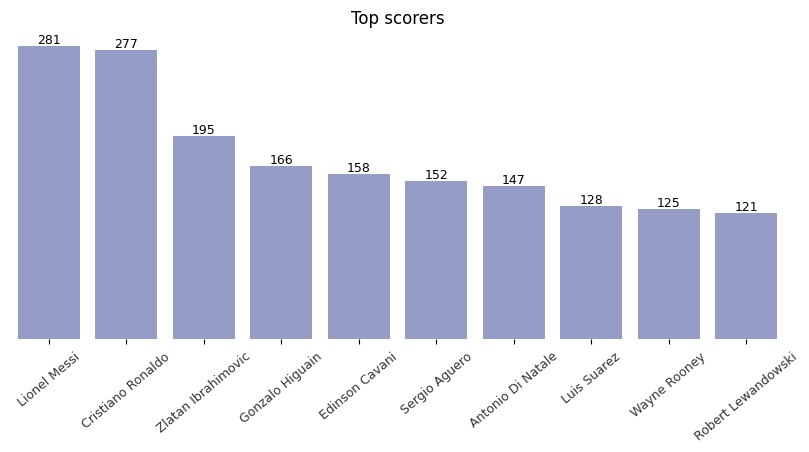

In [169]:
fig = plt.pyplot.figure(figsize=(10, 4))

ax = bar_plot_f(successful.head(10), name='Top scorers', color='#8D97CE')
ax.tick_params(axis='x', rotation=40)

sns.despine(left=True, bottom=True)

In [170]:
mask = goals.goal_type.isin(["p", "n"])

successful_league = goals[mask].groupby(['league', 'player_name']).player_name.count().sort_values(ascending=False)
successful_league.head(10)

league                  player_name       
Spain LIGA BBVA         Lionel Messi          281
                        Cristiano Ronaldo     259
Italy Serie A           Antonio Di Natale     147
England Premier League  Wayne Rooney          125
Germany 1. Bundesliga   Robert Lewandowski    121
England Premier League  Robin van Persie      116
France Ligue 1          Zlatan Ibrahimovic    113
Spain LIGA BBVA         Karim Benzema         111
Germany 1. Bundesliga   Stefan Kiessling      109
Spain LIGA BBVA         Aritz Aduriz          108
Name: player_name, dtype: int64

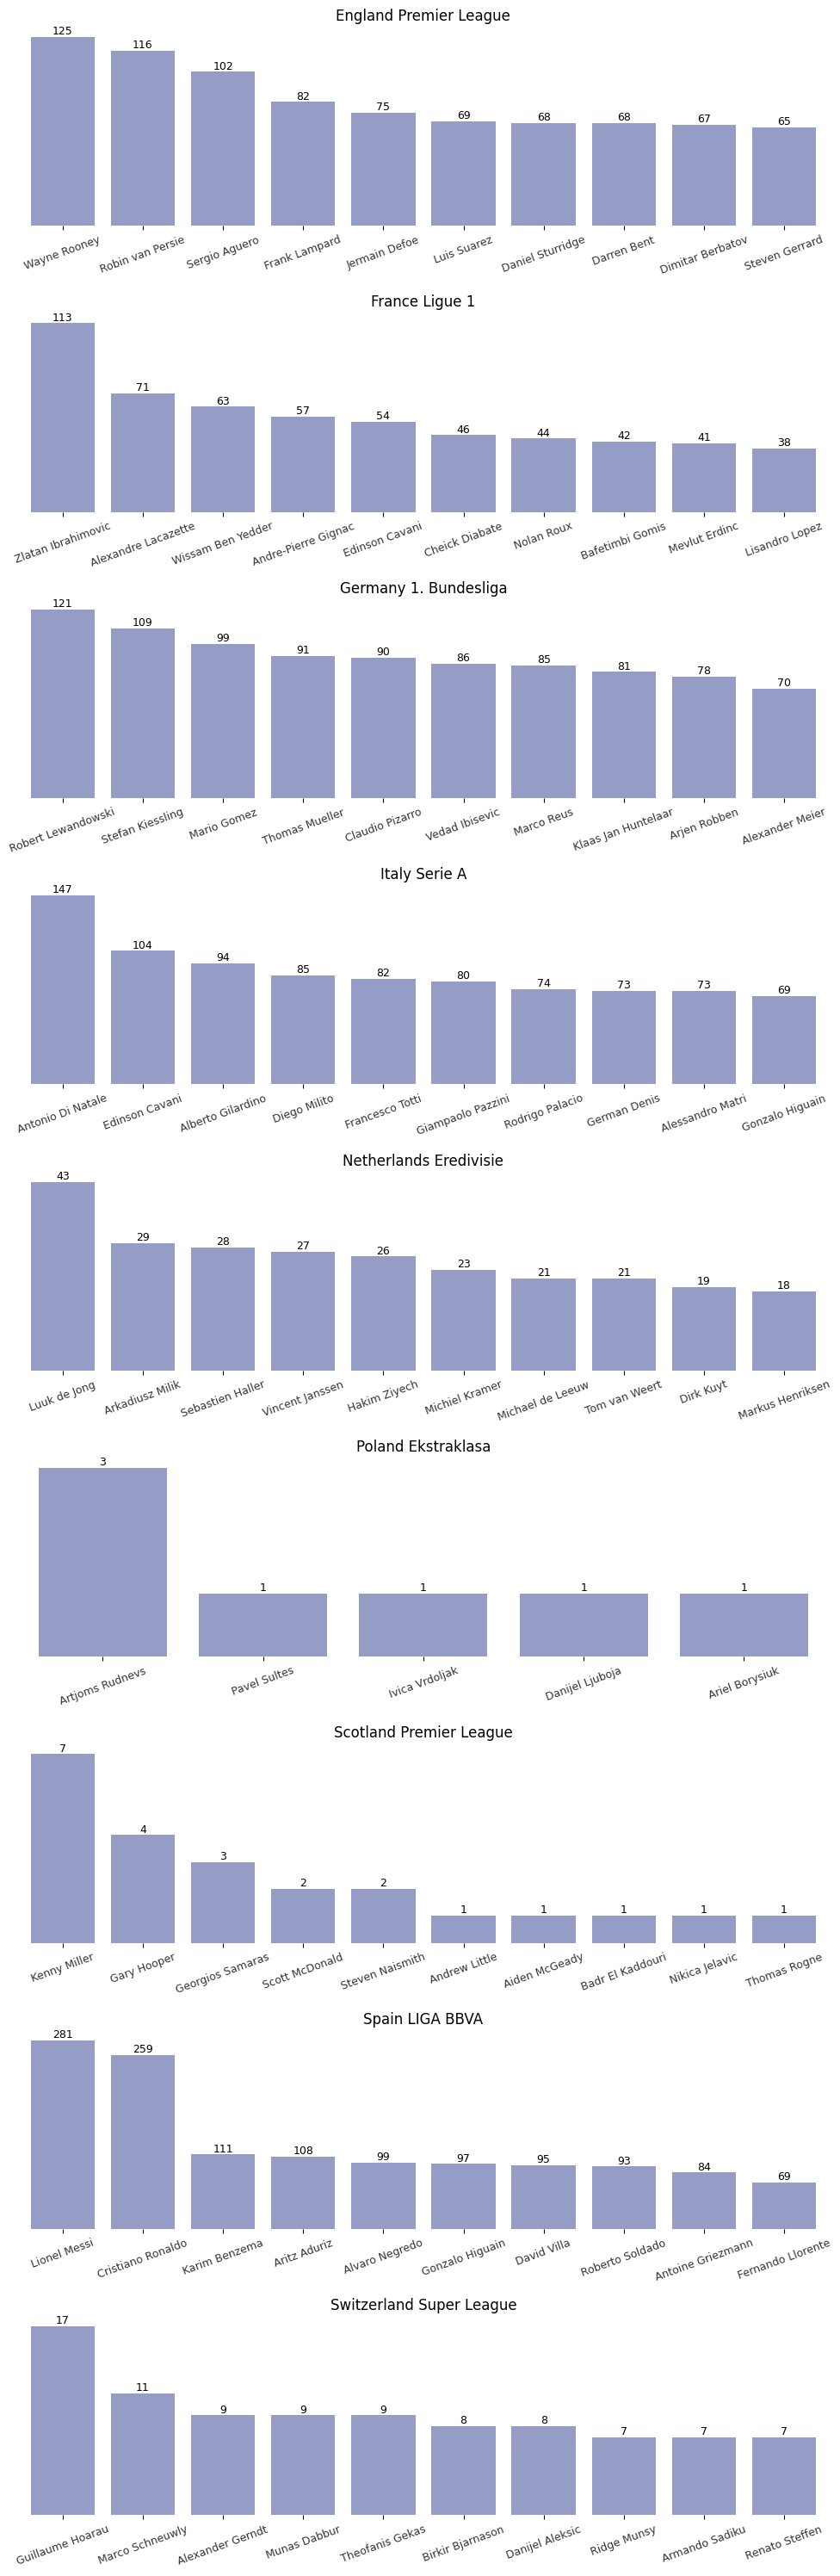

In [171]:
fig, axs = plt.pyplot.subplots(9, 1, figsize=(10, 30))

i = 0

for league in goals.league.unique():
    ax = bar_plot_f(successful_league[league].head(10), name=league, color='#8D97CE', ax=axs[i])
    ax.tick_params(axis='x', rotation=20)

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    i += 1

fig.tight_layout(pad=1)
sns.despine(left=True, bottom=True)

Highest scorers overall are from Spain LIGA BBVA, Lionel Messi and Christiano Ronaldo.

## For dashboard

In [172]:
file_exists = exists(r"data/player_info.csv")
if not file_exists:
    query = """
    WITH T1 AS (
        SELECT p.player_name, AVG(pa.overall_rating) average_rating, p.player_api_id
        FROM player_att pa
        JOIN player p ON p.player_api_id = pa.player_api_id
        GROUP BY p.player_name, p.player_api_id
        ORDER BY AVG(pa.overall_rating) DESC
        ),
        
        T2 AS (
        SELECT player_name, team_long_name, season, league, player_api_id, count(player_name) goals
        FROM goals        
        WHERE goal_type IN ('n', 'p')
        GROUP BY player_name, team_long_name, season, league, player_api_id
        )

    SELECT DISTINCT p.player_name, p.birthday, p.height, p.weight, p.year, 
        T1.average_rating, T2.team_long_name, T2.season, T2.league, COALESCE(T2.goals, 0) goals
    FROM player p
    JOIN T1 ON p.player_api_id = T1.player_api_id
    LEFT JOIN T2 ON p.player_api_id = T2.player_api_id
    ORDER BY p.player_name
    """
    player_info = db.sql(query).df()
    player_info.to_csv("data/player_info.csv", sep=",", index=False, encoding="utf-8")

# Hypothesis testing

After exploring the data, there are several questions, in which we can look into:

- Is there home advantage?
- Do taller players have higher overall score, compared to shorter ones?
- Do teams with build up speed fast make more goals compared to slow?

We can try to answer these questions using the data. Hypothesis testing will be applied to check if there is any statistical significance. $ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are few hypotheses Bonferroni Correction will be used: $ α $ is going to be divided by the number of hypoteses made – 3 (which results to roughly 0.0167).

## Home advantage

To check if there is home advantage or if it could be explained by chance, we are going to do chi-squared test. Null hypothesis is that there is no difference in chance to win for home or away team. Alternative hypothesis is that there is a difference.

In [173]:
def winner_f(df):
    '''
    This is a helper function to clasify who won the match: home or away team,
    or was it a draw.
    '''
    if df['home_team_goal'] > df['away_team_goal']:
        return 'home'
    elif df['home_team_goal'] < df['away_team_goal']:
        return 'away'
    else:
        return 'draw'


match['winner'] = match.apply(winner_f, axis=1)

In [174]:
match.head()

,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11,goal,shoton,shotoff,foulcommit,card,cross,corner,possession,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA,winner
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,1,2008/2009,1,2008-08-17,492473,9987,9993,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.73,3.40,5.00,1.75,3.35,4.20,1.85,3.2,3.5,1.80,3.3,3.75,NaN,NaN,NaN,1.70,3.30,4.33,1.90,3.3,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20,draw
2,1,2008/2009,1,2008-08-16,492474,10000,9994,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.95,3.20,3.60,1.80,3.30,3.95,1.90,3.2,3.5,1.90,3.2,3.50,NaN,NaN,NaN,1.83,3.30,3.60,1.95,3.3,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60,draw
3,1,2008/2009,1,2008-08-16,492475,9984,8635,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,2.38,3.30,2.75,2.40,3.30,2.55,2.60,3.1,2.3,2.50,3.2,2.50,NaN,NaN,NaN,2.50,3.25,2.40,2.63,3.3,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75,away
4,1,2008/2009,1,2008-08-17,492476,9991,9998,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.44,3.75,7.50,1.40,4.00,6.80,1.40,3.9,6.0,1.44,3.6,6.50,NaN,NaN,NaN,1.44,3.75,6.00,1.44,4.0,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50,home
5,1,2008/2009,1,2008-08-16,492477,7947,9985,1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,5.00,3.50,1.65,5.00,3.50,1.60,4.00,3.3,1.7,4.00,3.4,1.72,NaN,NaN,NaN,4.20,3.40,1.70,4.50,3.5,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67,away


In [175]:
match_outcome_count = match.winner.value_counts()

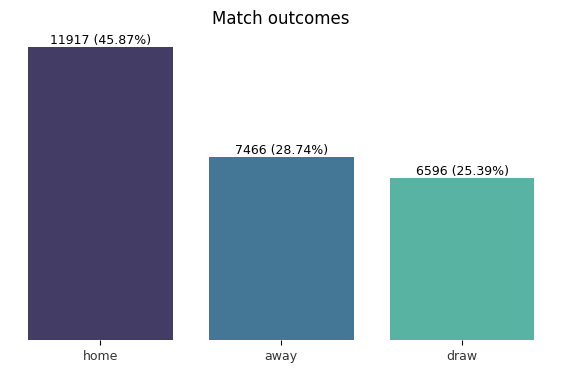

In [176]:
fig = plt.pyplot.figure(figsize=(7, 4))

ax = bar_plot_f_perc(match_outcome_count, name='Match outcomes', palet='mako')

sns.despine(left=True, bottom=True)

We can see that about 46% of matches are won by home team and about 29% by away team. About 25% of matches are draw. 

If there is no home advantage, amounts won by home and away team would be equal. We can check if there is statistical difference between would be scenario of equal wins and real stats by using chi-squared test.

In [177]:
# Amount of wins if the the chance to win is equal
equal = round((match_outcome_count.home + match_outcome_count.away) / 2, 0)
equal

9692.0

In [178]:
tmp = {'team': ['home', 'away'], 'real': [match_outcome_count.home, match_outcome_count.away], 'teo': [equal, equal]}
table = pd.DataFrame.from_dict(tmp).set_index('team')
table

,real,teo
team,,
home,11917,9692.0
away,7466,9692.0


In [179]:
stats.chi2_contingency(table)

Chi2ContingencyResult(statistic=517.4258203349501, pvalue=1.5367082069952406e-114, dof=1, expected_freq=array([[10804.22129646, 10804.77870354],
       [ 8578.77870354,  8579.22129646]]))

The first value (517.4) is the Chi-square value, followed by the p-value (1.5e-114), then comes the degrees of freedom (1), and lastly the expected frequencies as an array. The test results can be trusted, because all of the expected frequencies are greater than 5. We can reject the null hypothesis as the p-value is less than alpha. Therefore, there is statistical difference between age groups.

Therefore, we can say that there is a statistical advantage for home team to win.

## Tall vs Short

Checking if there is a difference between overall ratings for tallest and shortest players. Null hypothesis is that there is no difference and rating does not depend on height. Alternative hypothesis is that there is a difference.

In [180]:
query = """
WITH t1 AS (
    SELECT DISTINCT pa.player_fifa_api_id, p.height, pa.date, pa.overall_rating
    FROM player p
    JOIN player_att pa ON pa.player_fifa_api_id = p.player_fifa_api_id
    )

SELECT player_fifa_api_id, height, AVG(overall_rating) avg_rating
FROM T1
GROUP BY player_fifa_api_id, height
"""

player_avg_rating = db.sql(query).df()
player_avg_rating.head()

,player_fifa_api_id,height,avg_rating
0,197926,182.88,67.333333
1,193468,182.88,61.421053
2,200797,175.26,63.750000
3,203521,187.96,61.954545
4,186845,177.80,62.761905


In [181]:
player_avg_rating.iloc[:, 1:].describe()

,height,avg_rating
count,11060.000000,11060.000000
mean,181.867445,66.820208
std,6.369201,6.238135
min,157.480000,43.000000
25%,177.800000,62.818182
50%,182.880000,66.714286
75%,185.420000,70.956522
max,208.280000,92.192308


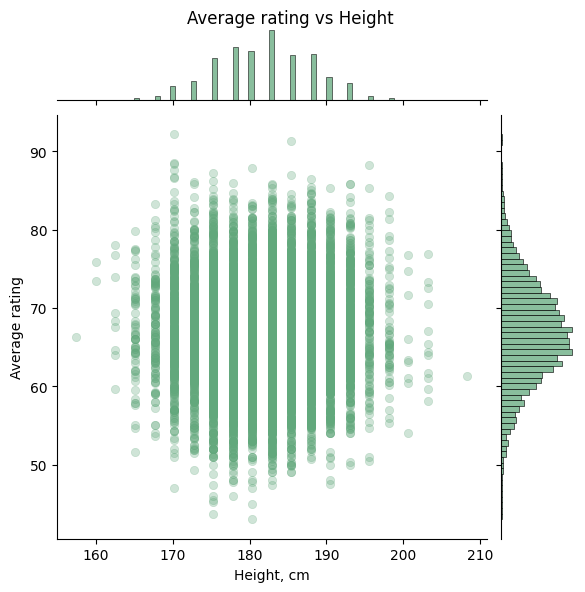

In [182]:
ax = sns.jointplot(player_avg_rating, x="height", y="avg_rating", color='#62A87C', alpha=0.3, edgecolor=None)
ax.fig.suptitle('Average rating vs Height')
ax.ax_joint.set_xlabel('Height, cm')
ax.ax_joint.set_ylabel('Average rating')
ax.fig.subplots_adjust(top=0.95);

There does not seem to be any relation between height and average player rating.

In [183]:
stats.pearsonr(player_avg_rating.height, player_avg_rating.avg_rating)

PearsonRResult(statistic=0.011691031650612612, pvalue=0.21891874872584777)

Correlation between height and average rating is low, and p value is high (0.22m, which is more than alpha 0.05), meaning that there is no statistical significance.

Next we are going to select                 

In [184]:
q75 = player_avg_rating.height.quantile(0.75)
mask = player_avg_rating.height >= q75
player_avg_rating_q75 = player_avg_rating.iloc[:, 1:][mask]
player_avg_rating_q75.describe()

,height,avg_rating
count,3916.000000,3916.000000
mean,188.651430,67.088193
std,3.237863,6.181302
min,185.420000,47.500000
25%,185.420000,63.000000
50%,187.960000,66.916667
75%,190.500000,71.116538
max,208.280000,91.280000


In [185]:
q25 = player_avg_rating.height.quantile(0.25)
mask = player_avg_rating.height <= q25
player_avg_rating_q25 = player_avg_rating.iloc[:, 1:][mask]
player_avg_rating_q25.describe()

,height,avg_rating
count,3802.000000,3802.000000
mean,174.917280,66.788253
std,3.181067,6.334541
min,157.480000,43.750000
25%,172.720000,62.750000
50%,175.260000,66.811012
75%,177.800000,71.000000
max,177.800000,92.192308


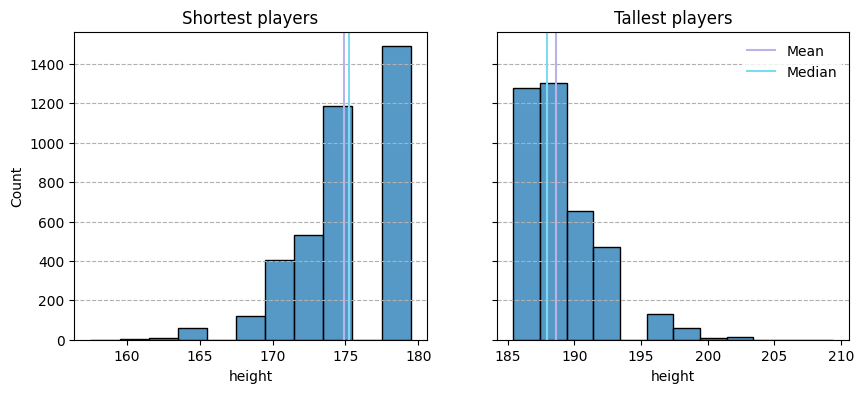

In [186]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))

ax0 = histplot_f(player_avg_rating_q25.height, name='Shortest players', ax=axs[0], binwidth=2)
ax0.get_legend().set_visible(False)

ax1 = histplot_f(player_avg_rating_q75.height, name='Tallest players', ax=axs[1], binwidth=2)

plt.pyplot.tight_layout;

Distributions of short and tall player heights are skewed because they are taken at from the both ends of the overall distribution.

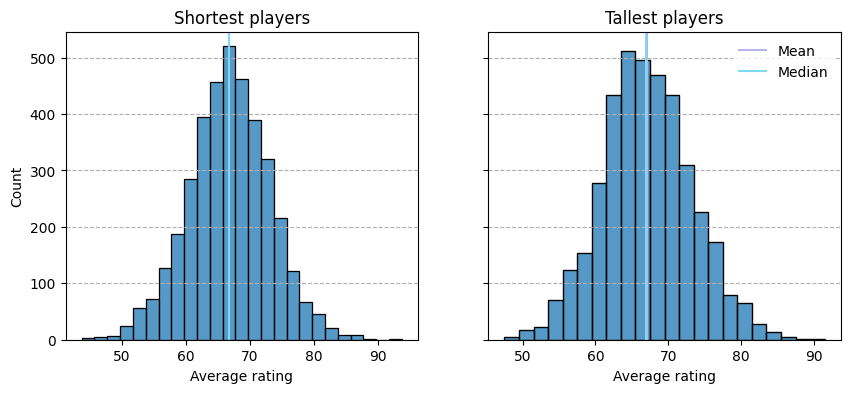

In [187]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))

ax0 = histplot_f(player_avg_rating_q25.avg_rating, name='Shortest players', ax=axs[0], binwidth=2)
ax0.get_legend().set_visible(False)
ax0.set(xlabel='Average rating')

ax1 = histplot_f(player_avg_rating_q75.avg_rating, name='Tallest players', ax=axs[1], binwidth=2)
ax1.set(xlabel='Average rating')

plt.pyplot.tight_layout;

Distributions for both shortest and tallest players average ratings are approximately normal. Range is approximately from 40 to 92.

Since there are a lot of data points, we can apply Central limit theorem, and test hypothesis using t-test and build confidence intervals. In addition we can check Mood’s median test and Mann-Whitney U test to check if this result holds up.

In [188]:
short_rating = player_avg_rating_q25.avg_rating
tall_rating = player_avg_rating_q75.avg_rating

In [189]:
conf_int_short_rating = stats.t.interval(
    0.95, df=len(short_rating) - 1, loc=short_rating.mean(), scale=short_rating.sem()
)
conf_int_short_rating

(66.5868362460061, 66.9896696391205)

In [190]:
conf_int_tall_rating = stats.t.interval(0.95, df=len(tall_rating) - 1, loc=tall_rating.mean(), scale=tall_rating.sem())
conf_int_tall_rating

(66.89453299764945, 67.28185393524284)

In [191]:
stats.ttest_ind(short_rating, tall_rating)

TtestResult(statistic=-2.1053586343405337, pvalue=0.03529233807887026, df=7716.0)

In [192]:
stats.median_test(short_rating, tall_rating)

MedianTestResult(statistic=0.2076592323236808, pvalue=0.6486082926751986, median=66.86363636363636, table=array([[1890, 1968],
       [1912, 1948]], dtype=int64))

In [193]:
stats.mannwhitneyu(short_rating, tall_rating)

MannwhitneyuResult(statistic=7301814.5, pvalue=0.14535519211641645)

Confidence intervals slightly overlap, p values for all the tests are higher than set significance level - 0.0167 in this case, due to Bonferroni Correction. Therefore, we failed to reject null hypotesis. The sample did not provide sufficient evidence to conclude that the there is a difference in short and tall player ratings.

## Fast vs slow build up speed

Checking if there is a difference between average goals per game for teams with slow build up speed compared to fast. Null hypothesis is that there is no difference and rating does not depend on height. Alternative hypothesis is that there is a difference.

In [194]:
query = """
WITH t1 AS (
    SELECT match_api_id, home_team_api_id team_api_id, home_team_goal goal, season
    FROM match
    UNION 
    SELECT match_api_id, away_team_api_id, away_team_goal, season year_match
    FROM match
    ),

    t2 AS (
    SELECT t.team_long_name, t.team_api_id, ta.buildUpPlaySpeedClass, season season_att
    FROM team_att ta
    JOIN team t ON t.team_api_id = ta.team_api_id
    WHERE ta.buildUpPlaySpeedClass IN ('Fast', 'Slow')
    ),

    t3 AS (
    SELECT DISTINCT t1.match_api_id, t2.team_long_name, t1.goal, t2.buildUpPlaySpeedClass
    FROM t1 
    JOIN t2 ON t2.season_att = t1.season AND t1.team_api_id =t2.team_api_id
    )

SELECT team_long_name, buildUpPlaySpeedClass, AVG(goal) avg_goals
FROM t3
GROUP BY team_long_name, buildUpPlaySpeedClass
"""

fast_slow = db.sql(query).df()
fast_slow.head()

,team_long_name,buildUpPlaySpeedClass,avg_goals
0,Livorno,Slow,0.710526
1,St. Johnstone FC,Fast,1.052632
2,CD Tenerife,Slow,1.052632
3,Portsmouth,Fast,0.894737
4,Roma,Fast,1.798246


In [195]:
mask = fast_slow.buildUpPlaySpeedClass == 'Fast'
fast = fast_slow[mask]
fast.describe()

,avg_goals
count,86.000000
mean,1.382906
std,0.425634
min,0.736842
25%,1.032895
50%,1.345588
75%,1.643627
max,2.647059


In [196]:
mask = fast_slow.buildUpPlaySpeedClass == 'Slow'
slow = fast_slow[mask]
slow.describe()

,avg_goals
count,64.000000
mean,1.329753
std,0.509278
min,0.666667
25%,1.000000
50%,1.183333
75%,1.555592
max,3.000000


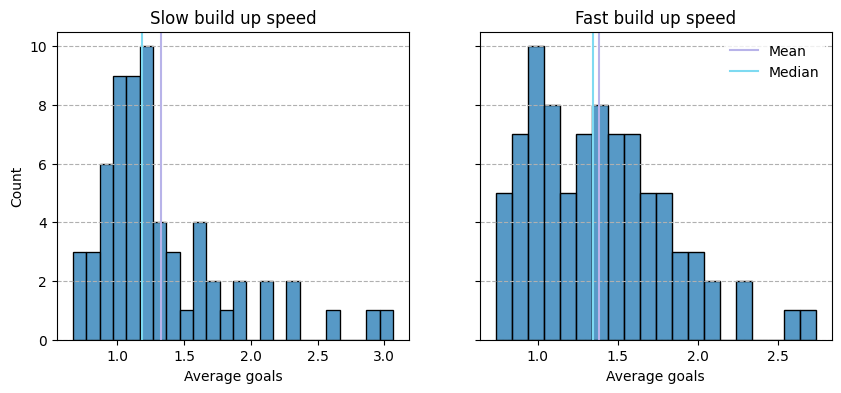

In [197]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))

ax0 = histplot_f(slow.avg_goals, name='Slow build up speed', ax=axs[0], binwidth=0.1)
ax0.get_legend().set_visible(False)
ax0.set(xlabel='Average goals')

ax1 = histplot_f(fast.avg_goals, name='Fast build up speed', ax=axs[1], binwidth=0.1)
ax1.set(xlabel='Average goals')

plt.pyplot.tight_layout;

Both distributions are skewed to the right with the range is from around 0.6 to 3 for slow build up speed and 2.25 for fast. Distributions are multimodal, meaning that there are several maximums.

Since there are a lot of data points, we can apply Central limit theorem, and test hypothesis using t-test and build confidence intervals, just like previously. In addition we can check Mood’s median test and Mann-Whitney U test to check if this result holds up.

In [198]:
conf_int_slow = stats.t.interval(
    0.95, df=len(slow.avg_goals) - 1, loc=slow.avg_goals.mean(), scale=slow.avg_goals.sem()
)
conf_int_slow

(1.2025394045649167, 1.4569670131337416)

In [199]:
conf_int_fast = stats.t.interval(
    0.95, df=len(fast.avg_goals) - 1, loc=fast.avg_goals.mean(), scale=fast.avg_goals.sem()
)
conf_int_fast

(1.2916497314997213, 1.4741618447173108)

In [200]:
stats.ttest_ind(slow.avg_goals, fast.avg_goals)

TtestResult(statistic=-0.6952693237238111, pvalue=0.4879767319911752, df=148.0)

In [201]:
stats.median_test(slow.avg_goals, fast.avg_goals)

MedianTestResult(statistic=4.605741279069767, pvalue=0.0318650743396294, median=1.256578947368421, table=array([[25, 50],
       [39, 36]], dtype=int64))

In [202]:
stats.mannwhitneyu(slow.avg_goals, fast.avg_goals)

MannwhitneyuResult(statistic=2404.0, pvalue=0.18666089459660584)

Confidence intervals overlap, p values for all the tests are higher than set significance level - 0.0167 in this case, due to Bonferroni Correction. Therefore, we failed to reject null hypotesis. The sample did not provide sufficient evidence to conclude that the there is a difference in slow and fast build up speed teams average goals per game.

# Modeling

For modeling I will try to answer these questions:
- Can we predict how many goals each team will score in each match?
- Can we predict which team will win the match?
  
I will use only Spain LIGA BBVA league data from seasons 2009/2010, 2010/2011, 2011/2012, 2013/2014, 2014/2015 and 2015/2016.

## Preparing and selecting data

### For predicting goals

Only numerical team attributes will be used and columns without missing values. Since there are two teams, difference between them is going to be calculated.

In [203]:
query = """
SELECT m.season, m.date, m.match_api_id, 
    m.home_team_api_id, m.away_team_api_id,
    m.winner, m.home_team_goal, m.away_team_goal, 
    ta.buildUpPlaySpeed - t.buildUpPlaySpeed buildUpPlaySpeed,
    ta.buildUpPlayPassing - t.buildUpPlayPassing buildUpPlayPassing,
    ta.chanceCreationPassing - t.chanceCreationPassing chanceCreationPassing,
    ta.chanceCreationCrossing - t.chanceCreationCrossing chanceCreationCrossing,
    ta.chanceCreationShooting - t.chanceCreationShooting chanceCreationShooting,
    ta.defencePressure - t.defencePressure defencePressure,
    ta.defenceAggression - t.defenceAggression defenceAggression,
    ta.defenceTeamWidth - t.defenceTeamWidth defenceTeamWidth
FROM match m
JOIN country_league cl ON cl.id = m.league_id
JOIN team_att ta ON ta.team_api_id = m.home_team_api_id
    AND ta.season = m.season
JOIN team_att t ON t.team_api_id = m.away_team_api_id
    AND t.season = m.season
WHERE cl.league = 'Spain LIGA BBVA' AND 
    m.season IN ('2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015', '2015/2016')
ORDER BY m.season
"""

spain_seasons = db.sql(query).df()
spain_seasons.head()

,season,date,match_api_id,home_team_api_id,away_team_api_id,winner,home_team_goal,away_team_goal,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
0,2009/2010,2009-12-06,684774,8558,8696,away,0,4,10,-15,0,-15,5,25,-5,10
1,2009/2010,2010-05-08,685187,8302,8634,away,2,3,-12,0,5,20,0,-10,40,-5
2,2009/2010,2010-01-24,684878,8558,8661,draw,1,1,15,0,20,15,20,25,10,15
3,2009/2010,2009-11-22,684750,9868,9869,draw,0,0,-40,-25,-20,-15,0,-25,-20,-10
4,2009/2010,2009-11-08,684735,8696,8315,away,0,2,-15,10,35,0,10,15,-15,15


In [204]:
spain_seasons.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2280 entries, 0 to 2279
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   season                  2280 non-null   object        
 1   date                    2280 non-null   datetime64[ns]
 2   match_api_id            2280 non-null   int64         
 3   home_team_api_id        2280 non-null   int64         
 4   away_team_api_id        2280 non-null   int64         
 5   winner                  2280 non-null   object        
 6   home_team_goal          2280 non-null   int64         
 7   away_team_goal          2280 non-null   int64         
 8   buildUpPlaySpeed        2280 non-null   int64         
 9   buildUpPlayPassing      2280 non-null   int64         
 10  chanceCreationPassing   2280 non-null   int64         
 11  chanceCreationCrossing  2280 non-null   int64         
 12  chanceCreationShooting  2280 non-null   int64   

In [205]:
diff_columns = spain_seasons.iloc[:, 8:].columns

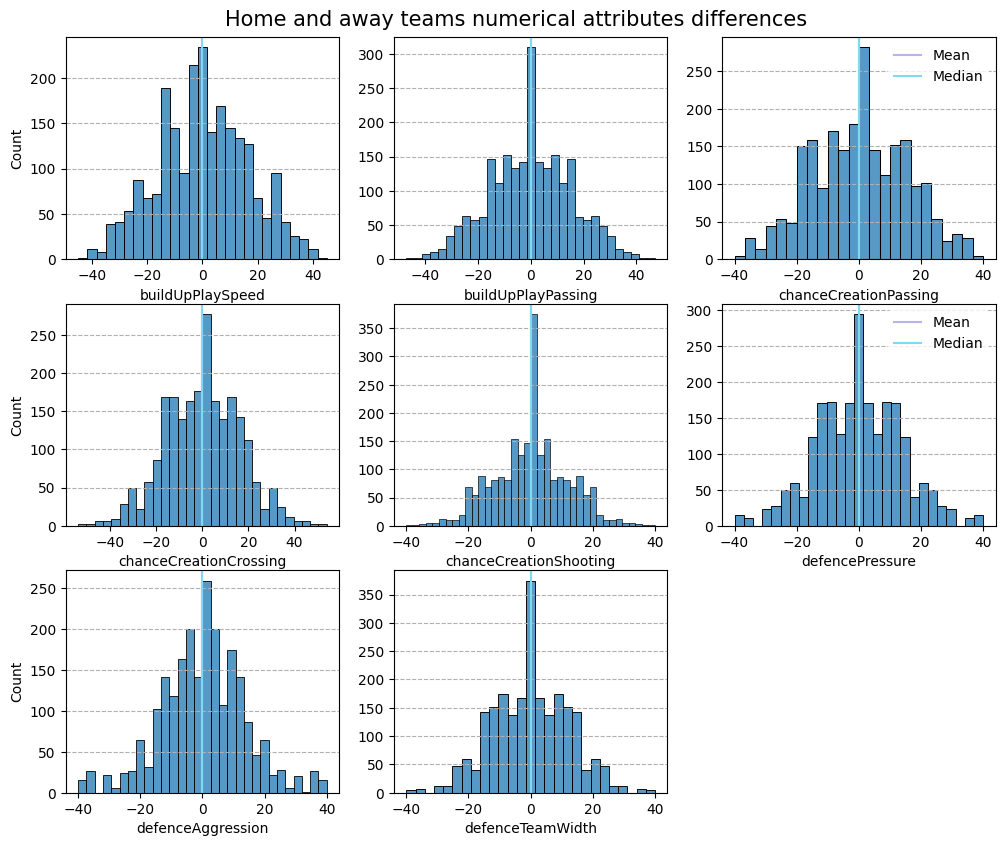

In [206]:
fig, axs = plt.pyplot.subplots(3, 3, figsize=(12, 9))
fig.suptitle('Home and away teams numerical attributes differences', fontsize=15)
fig.subplots_adjust(top=0.95)

i = 0
j = 0
for col in diff_columns:
    ax = histplot_f(spain_seasons.loc[:, col], ax=axs[j, i])

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    # Leaving only right most legends
    if i == 2:
        pass
    else:
        ax.get_legend().set_visible(False)

    i += 1
    if i == 3:
        i = 0
        j += 1

# Deleting empty ax
while i < 3:
    fig.delaxes(axs[j, i])
    i += 1

plt.pyplot.tight_layout;

All of the difference distributions are approximately normal. There are no outliers which would be too far off.

In [207]:
# Normalizing data for machine learning
for col in diff_columns:
    spain_seasons.loc[:, [col]] = preprocessing.normalize([spain_seasons.loc[:, col].dropna()])[0]

spain_seasons.iloc[:, 8:].describe()

,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
count,2.280000e+03,2.280000e+03,2.280000e+03,2.280000e+03,2.280000e+03,2.280000e+03,2.280000e+03,2.280000e+03
mean,1.278217e-19,-2.434700e-20,8.521449e-20,4.869399e-20,-5.478074e-20,-4.869399e-20,-4.869399e-20,2.434700e-20
std,2.094729e-02,2.094729e-02,2.094729e-02,2.094729e-02,2.094729e-02,2.094729e-02,2.094729e-02,2.094729e-02
min,-5.746634e-02,-6.475660e-02,-5.480367e-02,-6.985600e-02,-7.057451e-02,-6.026188e-02,-6.166733e-02,-6.791455e-02
25%,-1.404733e-02,-1.377800e-02,-1.507101e-02,-1.552356e-02,-1.235054e-02,-1.506547e-02,-1.387515e-02,-1.697864e-02
50%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.404733e-02,1.377800e-02,1.507101e-02,1.552356e-02,1.235054e-02,1.506547e-02,1.387515e-02,1.697864e-02
max,5.746634e-02,6.475660e-02,5.480367e-02,6.985600e-02,7.057451e-02,6.026188e-02,6.166733e-02,6.791455e-02


**No outliers vs full dataset:**
Models for dataset with no outliers is going to be compared with the one which is full.

In [208]:
outliers = outlier_f(spain_seasons.iloc[:, 6:])
outliers.count(axis=0)

home_team_goal            229
away_team_goal             11
buildUpPlaySpeed            2
buildUpPlayPassing          6
chanceCreationPassing       0
chanceCreationCrossing      4
chanceCreationShooting     54
defencePressure             0
defenceAggression          30
defenceTeamWidth            0
dtype: int64

In [209]:
out_index = outliers.dropna(axis=0, how='all').index
mask = spain_seasons.index.isin(out_index)
spain_seasons_noout = spain_seasons.loc[~mask]
spain_seasons_noout.head()

,season,date,match_api_id,home_team_api_id,away_team_api_id,winner,home_team_goal,away_team_goal,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
0,2009/2010,2009-12-06,684774,8558,8696,away,0,4,0.012770,-0.020667,0.000000,-0.019404,0.008822,0.037664,-0.007708,0.016979
2,2009/2010,2010-01-24,684878,8558,8661,draw,1,1,0.019155,0.000000,0.027402,0.019404,0.035287,0.037664,0.015417,0.025468
3,2009/2010,2009-11-22,684750,9868,9869,draw,0,0,-0.051081,-0.034445,-0.027402,-0.019404,0.000000,-0.037664,-0.030834,-0.016979
4,2009/2010,2009-11-08,684735,8696,8315,away,0,2,-0.019155,0.013778,0.047953,0.000000,0.017644,0.022598,-0.023125,0.025468
5,2009/2010,2010-01-31,684903,9906,9864,away,0,2,0.005108,-0.034445,0.034252,0.006468,0.000000,0.037664,-0.047792,0.016979


**Split between train and test:** Data from 2009/2010, 2010/2011, 2011/2012, 2013/2014 and 2014/2015 seasons will be used for training. 2015/2016 season results are going to be used for testing the model.

In [210]:
mask = spain_seasons.season.isin(['2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015'])

x_train = spain_seasons[mask].iloc[:, 8:]
y_train_home = spain_seasons[mask].home_team_goal
y_train_away = spain_seasons[mask].away_team_goal

In [211]:
mask = spain_seasons.season.isin(['2015/2016'])

x_test = spain_seasons[mask].iloc[:, 8:]
y_test_home = spain_seasons[mask].home_team_goal
y_test_away = spain_seasons[mask].away_team_goal

In [212]:
mask = spain_seasons_noout.season.isin(['2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015'])

x_train_noout = spain_seasons_noout[mask].iloc[:, 8:]
y_train_home_noout = spain_seasons_noout[mask].home_team_goal
y_train_away_noout = spain_seasons_noout[mask].away_team_goal

In [213]:
mask = spain_seasons_noout.season.isin(['2015/2016'])

x_test_noout = spain_seasons_noout[mask].iloc[:, 8:]
y_test_home_noout = spain_seasons_noout[mask].home_team_goal
y_test_away_noout = spain_seasons_noout[mask].away_team_goal

A balanced dataset is one that contains an equal or almost equal number of samples from the positive and negative classes. As some of the instances are more common than other, the dataset is unbalanced.

In [214]:
rus = RandomUnderSampler(random_state=42, sampling_strategy='majority')

# Balancing the data, using the dataset using undersampling.
x_resampled_home, y_resampled_home = rus.fit_resample(x_train, y_train_home)
x_resampled_away, y_resampled_away = rus.fit_resample(x_train, y_train_away)

### For predicting who will win the game

Only numerical team attributes will be used and columns without missing values.

In [215]:
query = """
SELECT m.season, m.date, m.match_api_id, 
    m.home_team_api_id, m.away_team_api_id,
    m.winner, m.home_team_goal, m.away_team_goal, 
    ta.buildUpPlaySpeed home_buildUpPlaySpeed,
    ta.buildUpPlayPassing home_buildUpPlayPassing,
    ta.chanceCreationPassing home_chanceCreationPassing,
    ta.chanceCreationCrossing home_chanceCreationCrossing,
    ta.chanceCreationShooting home_hanceCreationShooting,
    ta.defencePressure home_defencePressure,
    ta.defenceAggression home_defenceAggression,
    ta.defenceTeamWidth home_defenceTeamWidth,
    t.buildUpPlaySpeed away_buildUpPlaySpeed,
    t.buildUpPlayPassing away_buildUpPlayPassing,
    t.chanceCreationPassing away_chanceCreationPassing,
    t.chanceCreationCrossing away_chanceCreationCrossing,
    t.chanceCreationShooting away_chanceCreationShooting,
    t.defencePressure away_defencePressure,
    t.defenceAggression away_defenceAggression,
    t.defenceTeamWidth away_defenceTeamWidth
FROM match m
JOIN country_league cl ON cl.id = m.league_id
JOIN team_att ta ON ta.team_api_id = m.home_team_api_id
    AND ta.season = m.season
JOIN team_att t ON t.team_api_id = m.away_team_api_id
    AND t.season = m.season
WHERE cl.league = 'Spain LIGA BBVA' AND 
    m.season IN ('2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015', '2015/2016')
ORDER BY m.season
"""

spain_seasons2 = db.sql(query).df()
spain_seasons2.head()

,season,date,match_api_id,home_team_api_id,away_team_api_id,winner,home_team_goal,away_team_goal,home_buildUpPlaySpeed,home_buildUpPlayPassing,home_chanceCreationPassing,home_chanceCreationCrossing,home_hanceCreationShooting,home_defencePressure,home_defenceAggression,home_defenceTeamWidth,away_buildUpPlaySpeed,away_buildUpPlayPassing,away_chanceCreationPassing,away_chanceCreationCrossing,away_chanceCreationShooting,away_defencePressure,away_defenceAggression,away_defenceTeamWidth
0,2009/2010,2009-12-06,684774,8558,8696,away,0,4,55,40,70,55,70,70,50,60,45,55,70,70,65,45,55,50
1,2009/2010,2010-05-08,685187,8302,8634,away,2,3,30,30,70,60,70,60,70,65,42,30,65,40,70,70,30,70
2,2009/2010,2010-01-24,684878,8558,8661,draw,1,1,55,40,70,55,70,70,50,60,40,40,50,40,50,45,40,45
3,2009/2010,2009-11-22,684750,9868,9869,draw,0,0,30,30,45,35,70,45,50,45,70,55,65,50,70,70,70,55
4,2009/2010,2009-11-08,684735,8696,8315,away,0,2,45,55,70,70,65,45,55,50,60,45,35,70,55,30,70,35


**Outliers:** There are no outliers in this dataset.

In [216]:
outliers2 = outlier_f(spain_seasons.iloc[:, 8:])
outliers2.count(axis=0)

buildUpPlaySpeed           2
buildUpPlayPassing         6
chanceCreationPassing      0
chanceCreationCrossing     4
chanceCreationShooting    54
defencePressure            0
defenceAggression         30
defenceTeamWidth           0
dtype: int64

**Split between train and test:** Data from 2009/2010, 2010/2011, 2011/2012, 2013/2014 and 2014/2015 seasons will be used for training. 2015/2016 season results are going to be used for testing the model.

In [217]:
mask = spain_seasons2.season.isin(['2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015'])

x_train2 = spain_seasons2[mask].iloc[:, 8:]
y_train2 = spain_seasons[mask].winner

mask = spain_seasons2.season.isin(['2015/2016'])

x_test2 = spain_seasons2[mask].iloc[:, 8:]
y_test2 = spain_seasons2[mask].winner

In [218]:
smote = SMOTE()

# Balancing the data, using the dataset using oversamplingg.
x_resampled2, y_resampled2 = smote.fit_resample(x_train2, y_train2)

Selecting less of the attributes for the model.

In [219]:
query = """
SELECT m.season, m.date, m.match_api_id, 
    m.home_team_api_id, m.away_team_api_id,
    m.winner, m.home_team_goal, m.away_team_goal, 
    ta.chanceCreationPassing home_chanceCreationPassing,
    ta.chanceCreationCrossing home_chanceCreationCrossing,
    ta.defenceAggression home_defenceAggression,
    ta.defenceTeamWidth home_defenceTeamWidth,
    t.chanceCreationPassing away_chanceCreationPassing,
    t.chanceCreationCrossing away_chanceCreationCrossing,
    t.defenceAggression away_defenceAggression,
    t.defenceTeamWidth away_defenceTeamWidth
FROM match m
JOIN country_league cl ON cl.id = m.league_id
JOIN team_att ta ON ta.team_api_id = m.home_team_api_id
    AND ta.season = m.season
JOIN team_att t ON t.team_api_id = m.away_team_api_id
    AND t.season = m.season
WHERE cl.league = 'Spain LIGA BBVA' AND 
    m.season IN ('2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015', '2015/2016')
ORDER BY m.season
"""

spain_seasons3 = db.sql(query).df()
spain_seasons3.head()

,season,date,match_api_id,home_team_api_id,away_team_api_id,winner,home_team_goal,away_team_goal,home_chanceCreationPassing,home_chanceCreationCrossing,home_defenceAggression,home_defenceTeamWidth,away_chanceCreationPassing,away_chanceCreationCrossing,away_defenceAggression,away_defenceTeamWidth
0,2009/2010,2009-12-06,684774,8558,8696,away,0,4,70,55,50,60,70,70,55,50
1,2009/2010,2010-05-08,685187,8302,8634,away,2,3,70,60,70,65,65,40,30,70
2,2009/2010,2010-01-24,684878,8558,8661,draw,1,1,70,55,50,60,50,40,40,45
3,2009/2010,2009-11-22,684750,9868,9869,draw,0,0,45,35,50,45,65,50,70,55
4,2009/2010,2009-11-08,684735,8696,8315,away,0,2,70,70,55,50,35,70,70,35


In [220]:
mask = spain_seasons3.season.isin(['2009/2010', '2010/2011', '2011/2012', '2013/2014', '2014/2015'])

x_train3 = spain_seasons3[mask].iloc[:, 8:]
y_train3 = spain_seasons3[mask].winner

mask = spain_seasons3.season.isin(['2015/2016'])

x_test3 = spain_seasons3[mask].iloc[:, 8:]
y_test3 = spain_seasons3[mask].winner

In [221]:
smote = SMOTE()
x_resampled3, y_resampled3 = smote.fit_resample(x_train3, y_train3)

## Predicting how many goals each team will score in each match

### Model version 1

In [222]:
goals_home_linear = LinearRegression()
goals_home_linear.fit(x_train, y_train_home)

LinearRegression()

In [223]:
goals_away_linear = LinearRegression()
goals_away_linear.fit(x_train, y_train_away)

LinearRegression()

In [224]:
goals_home_linear_stats = sm.OLS(y_train_home, x_train).fit()
goals_home_linear_stats.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:         home_team_goal   R-squared (uncentered):                   0.019
Model:                            OLS   Adj. R-squared (uncentered):              0.015
Method:                 Least Squares   F-statistic:                              4.692
Date:                Mon, 25 Mar 2024   Prob (F-statistic):                    1.05e-05
Time:                        21:46:36   Log-Likelihood:                         -4113.1
No. Observations:                1900   AIC:                                      8242.
Df Residuals:                    1892   BIC:                                      8287.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
buildUpPlaySpeed           1.1505      3.185      0.361      0.718      -5.097       7.398
buildUpPlayPassing        -8.2141      3.114     -2.638      0.008     -14.322      -2.107
chanceCreationPassing      1.5604      2.810      0.555      0.579      -3.950       7.071
chanceCreationCrossing    -5.3407      2.664     -2.005      0.045     -10.565      -0.117
chanceCreationShooting     0.5533      2.481      0.223      0.824      -4.312       5.419
defencePressure            0.4936      2.630      0.188      0.851      -4.664       5.651
defenceAggression          3.2888      2.334      1.409      0.159      -1.288       7.866
defenceTeamWidth           7.6464      2.475      3.089      0.002       2.792      12.501
==============================================================================
Omnibus:                      259.313   Durbin-Watson:                   0.827
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              404.774
Skew:                           0.943   Prob(JB):                     1.27e-88
Kurtosis:                       4.249   Cond. No.                         2.75
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [225]:
goals_away_linear_stats = sm.OLS(y_train_away, x_train).fit()
goals_away_linear_stats.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:         away_team_goal   R-squared (uncentered):                   0.020
Model:                            OLS   Adj. R-squared (uncentered):              0.016
Method:                 Least Squares   F-statistic:                              4.814
Date:                Mon, 25 Mar 2024   Prob (F-statistic):                    6.95e-06
Time:                        21:46:36   Log-Likelihood:                         -3577.8
No. Observations:                1900   AIC:                                      7172.
Df Residuals:                    1892   BIC:                                      7216.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
buildUpPlaySpeed           0.5842      2.403      0.243      0.808      -4.129       5.298
buildUpPlayPassing         2.8441      2.350      1.210      0.226      -1.764       7.452
chanceCreationPassing     -3.8352      2.120     -1.809      0.071      -7.993       0.323
chanceCreationCrossing     3.7286      2.010      1.855      0.064      -0.213       7.670
chanceCreationShooting    -0.6613      1.872     -0.353      0.724      -4.332       3.010
defencePressure           -1.7461      1.984     -0.880      0.379      -5.638       2.145
defenceAggression         -1.3136      1.761     -0.746      0.456      -4.767       2.140
defenceTeamWidth          -6.7850      1.868     -3.633      0.000     -10.448      -3.122
==============================================================================
Omnibus:                      429.747   Durbin-Watson:                   0.989
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1008.698
Skew:                           1.242   Prob(JB):                    9.21e-220
Kurtosis:                       5.564   Cond. No.                         2.75
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [226]:
home_predict = goals_home_linear.predict(x_test)
home_predict_r = home_predict.round()

away_predict = goals_away_linear.predict(x_test)
away_predict_r = away_predict.round()

In [227]:
print(
    f'''
Test accuracy:
For home team - {accuracy_score(y_test_home, home_predict_r)}
For away team - {accuracy_score(y_test_away, away_predict_r)}
'''
)


Test accuracy:
For home team - 0.27631578947368424
For away team - 0.35526315789473684



In [228]:
r2_score(y_test_home, home_predict)

0.04139846140330372

In [229]:
r2_score(y_test_away, away_predict)

0.020917049610011174

In [230]:
residuals_home = home_predict - y_test_home
residuals_away = away_predict - y_test_away

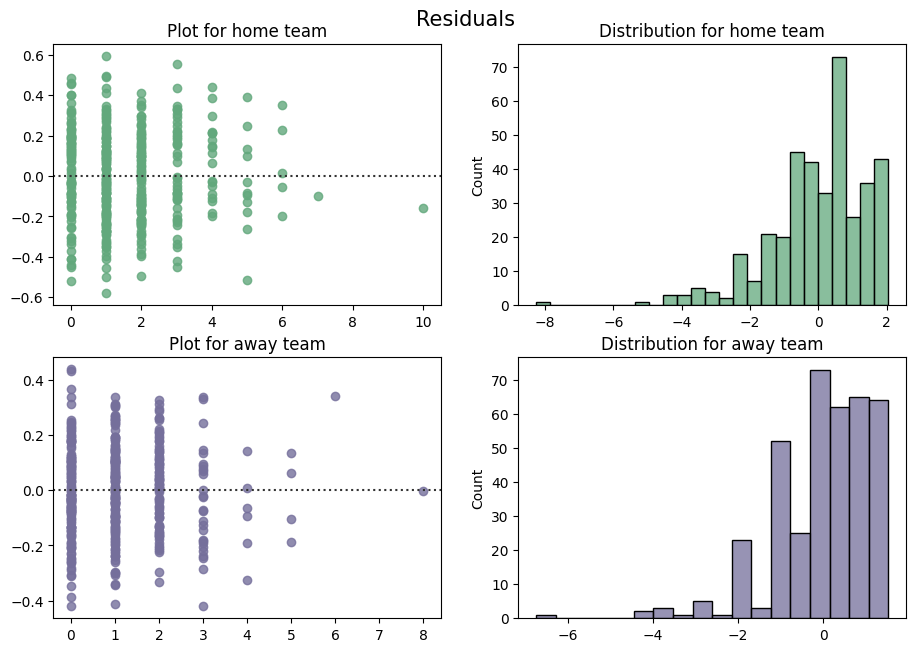

In [231]:
fig, axs = plt.pyplot.subplots(2, 2, figsize=(11, 7))
fig.suptitle('Residuals', fontsize=15)
fig.subplots_adjust(top=0.93)

ax0 = sns.residplot(x=y_test_home, y=home_predict, color='#62A87C', ax=axs[0, 0])
ax0.set(title='Plot for home team', xlabel='')
ax1 = sns.histplot(residuals_home, color='#62A87C', ax=axs[0, 1])
ax1.set(title='Distribution for home team', xlabel='')

ax2 = sns.residplot(x=y_test_away, y=away_predict, color='#756F9B', ax=axs[1, 0])
ax2.set(title='Plot for away team', xlabel='')
ax3 = sns.histplot(residuals_away, color='#756F9B', ax=axs[1, 1])
ax3.set(title='Distribution for away team', xlabel='')

plt.pyplot.tight_layout;

Residuals distribution is skewed to the left. Skewed residuals can indicate that the regression model is not adequately capturing the relationship between the predictor and response variables.

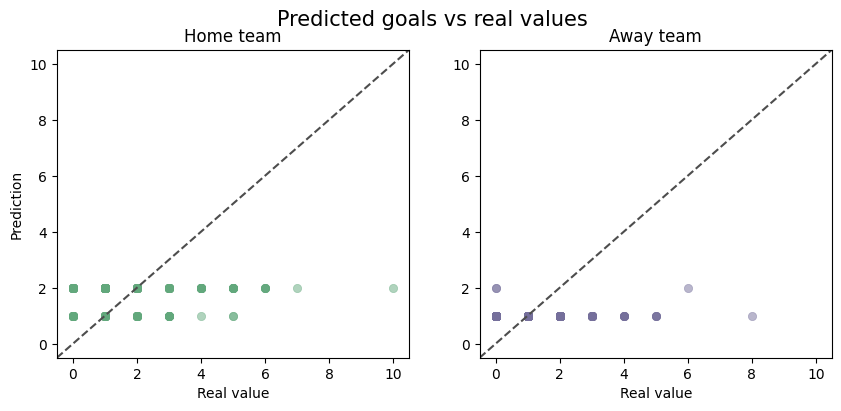

In [232]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Predicted goals vs real values', fontsize=15)

ax0 = sns.scatterplot(x=y_test_home, y=home_predict_r, edgecolor=None, color='#62A87C', alpha=0.5, ax=axs[0])
ax0.set(
    title='Home team',
    ylabel='Prediction',
    xlabel='Real value',
    ylim=[-0.5, 10.5],
    xlim=[-0.5, 10.5],
)
ax0.plot(ax0.get_xlim(), ax0.get_ylim(), ls="--", c=".3")

ax1 = sns.scatterplot(x=y_test_away, y=away_predict_r, edgecolor=None, color='#756F9B', alpha=0.5, ax=axs[1])
ax1.set(
    title='Away team',
    ylabel='',
    xlabel='Real value',
    ylim=[-0.5, 10.5],
    xlim=[-0.5, 10.5],
)
ax1.plot(ax1.get_xlim(), ax1.get_ylim(), ls="--", c=".3");

The model only predicts 1 or 2 goals, therefore it's accuracy is low.

### Model version 2

This is the model version, where the dataset is with no outliers.

In [233]:
goals_home_linear_noout = LinearRegression()
goals_home_linear_noout.fit(x_train_noout, y_train_home_noout)

LinearRegression()

In [234]:
goals_away_linear_noout = LinearRegression()
goals_away_linear_noout.fit(x_train_noout, y_train_away_noout)

LinearRegression()

In [235]:
goals_home_linear_stats_noout = sm.OLS(y_train_home_noout, x_train_noout).fit()
goals_home_linear_stats_noout.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:         home_team_goal   R-squared (uncentered):                   0.004
Model:                            OLS   Adj. R-squared (uncentered):             -0.001
Method:                 Least Squares   F-statistic:                             0.7490
Date:                Mon, 25 Mar 2024   Prob (F-statistic):                       0.648
Time:                        21:46:37   Log-Likelihood:                         -3068.9
No. Observations:                1620   AIC:                                      6154.
Df Residuals:                    1612   BIC:                                      6197.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
buildUpPlaySpeed          -0.2348      2.638     -0.089      0.929      -5.409       4.939
buildUpPlayPassing        -1.7619      2.568     -0.686      0.493      -6.798       3.274
chanceCreationPassing      0.3172      2.329      0.136      0.892      -4.251       4.885
chanceCreationCrossing     0.0389      2.245      0.017      0.986      -4.364       4.442
chanceCreationShooting    -2.3653      2.276     -1.039      0.299      -6.830       2.099
defencePressure            0.5210      2.208      0.236      0.813      -3.809       4.851
defenceAggression         -2.0126      2.048     -0.983      0.326      -6.029       2.004
defenceTeamWidth           3.1191      2.051      1.521      0.128      -0.903       7.141
==============================================================================
Omnibus:                      258.220   Durbin-Watson:                   0.740
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               75.401
Skew:                           0.258   Prob(JB):                     4.24e-17
Kurtosis:                       2.077   Cond. No.                         2.67
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [236]:
goals_away_linear_stats_noout = sm.OLS(y_train_away_noout, x_train_noout).fit()
goals_away_linear_stats_noout.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:         away_team_goal   R-squared (uncentered):                   0.022
Model:                            OLS   Adj. R-squared (uncentered):              0.017
Method:                 Least Squares   F-statistic:                              4.606
Date:                Mon, 25 Mar 2024   Prob (F-statistic):                    1.42e-05
Time:                        21:46:37   Log-Likelihood:                         -2999.9
No. Observations:                1620   AIC:                                      6016.
Df Residuals:                    1612   BIC:                                      6059.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
buildUpPlaySpeed           0.4865      2.528      0.192      0.847      -4.472       5.445
buildUpPlayPassing         3.4476      2.461      1.401      0.161      -1.379       8.274
chanceCreationPassing     -3.4924      2.232     -1.565      0.118      -7.870       0.885
chanceCreationCrossing     3.3064      2.151      1.537      0.124      -0.913       7.525
chanceCreationShooting    -2.5002      2.181     -1.146      0.252      -6.778       1.778
defencePressure           -1.0393      2.116     -0.491      0.623      -5.189       3.110
defenceAggression         -1.2075      1.962     -0.615      0.538      -5.056       2.641
defenceTeamWidth          -7.1698      1.965     -3.648      0.000     -11.024      -3.315
==============================================================================
Omnibus:                      168.396   Durbin-Watson:                   0.981
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              221.344
Skew:                           0.871   Prob(JB):                     8.62e-49
Kurtosis:                       3.494   Cond. No.                         2.67
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [237]:
home_predict_noout = goals_home_linear_noout.predict(x_test_noout)
home_predict_noout_r = home_predict_noout.round()

away_predict_noout = goals_away_linear_noout.predict(x_test_noout)
away_predict_noout_r = away_predict_noout.round()

In [238]:
print(
    f'''
Test accuracy:
For home team - {accuracy_score(y_test_home_noout, home_predict_noout_r)}
For away team - {accuracy_score(y_test_away_noout, away_predict_noout_r)}
'''
)


Test accuracy:
For home team - 0.36283185840707965
For away team - 0.35988200589970504



In [239]:
r2_score(y_test_home_noout, home_predict_noout)

0.0041063246006435294

In [240]:
r2_score(y_test_away_noout, away_predict_noout)

0.0007170994150866861

In [241]:
residuals_home_noout = home_predict_noout - y_test_home_noout
residuals_away_noout = away_predict_noout - y_test_away_noout

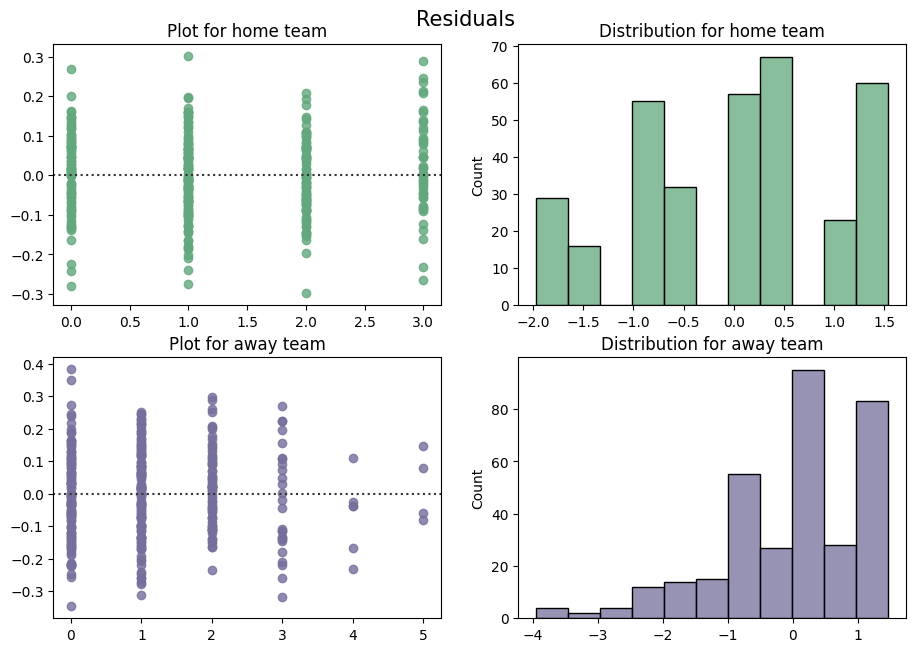

In [242]:
fig, axs = plt.pyplot.subplots(2, 2, figsize=(11, 7))
fig.suptitle('Residuals', fontsize=15)
fig.subplots_adjust(top=0.93)

ax0 = sns.residplot(x=y_test_home_noout, y=home_predict_noout, color='#62A87C', ax=axs[0, 0])
ax0.set(title='Plot for home team', xlabel='')
ax1 = sns.histplot(residuals_home_noout, color='#62A87C', ax=axs[0, 1])
ax1.set(title='Distribution for home team', xlabel='')

ax2 = sns.residplot(x=y_test_away_noout, y=away_predict_noout, color='#756F9B', ax=axs[1, 0])
ax2.set(title='Plot for away team', xlabel='')
ax3 = sns.histplot(residuals_away_noout, color='#756F9B', ax=axs[1, 1])
ax3.set(title='Distribution for away team', xlabel='')

plt.pyplot.tight_layout;

The distribution of residuals is skewed to the left.

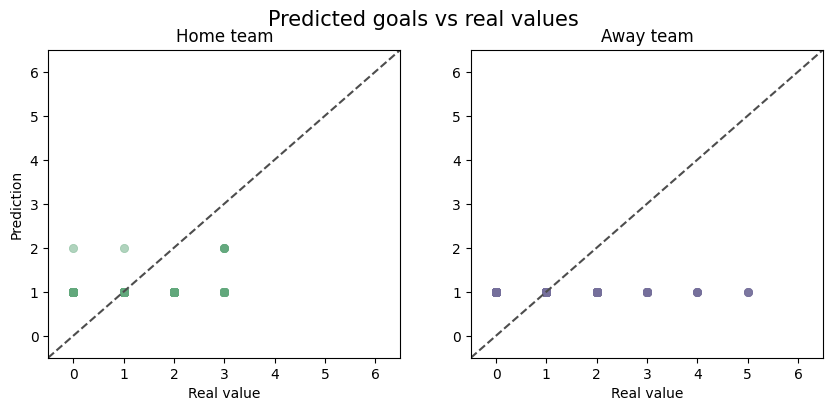

In [243]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Predicted goals vs real values', fontsize=15)

ax0 = sns.scatterplot(
    x=y_test_home_noout, y=home_predict_noout_r, edgecolor=None, color='#62A87C', alpha=0.5, ax=axs[0]
)
ax0.set(
    title='Home team',
    ylabel='Prediction',
    xlabel='Real value',
    ylim=[-0.5, 6.5],
    xlim=[-0.5, 6.5],
)
ax0.plot(ax0.get_xlim(), ax0.get_ylim(), ls="--", c=".3")

ax1 = sns.scatterplot(
    x=y_test_away_noout, y=away_predict_noout_r, edgecolor=None, color='#756F9B', alpha=0.5, ax=axs[1]
)
ax1.set(
    title='Away team',
    ylabel='',
    xlabel='Real value',
    ylim=[-0.5, 6.5],
    xlim=[-0.5, 6.5],
)
ax1.plot(ax1.get_xlim(), ax1.get_ylim(), ls="--", c=".3");

The model only guesses 1 or 2 goals every time.

### Model version 3

This model will use dataset which was balanced using random under sampling.

In [244]:
goals_home_linear_bal = LinearRegression()
goals_home_linear_bal.fit(x_resampled_home, y_resampled_home)

LinearRegression()

In [245]:
goals_away_linear_bal = LinearRegression()
goals_away_linear_bal.fit(x_resampled_away, y_resampled_away)

LinearRegression()

In [246]:
goals_home_linear_stats_bal = sm.OLS(y_resampled_home, x_resampled_home).fit()
goals_home_linear_stats_bal.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:         home_team_goal   R-squared (uncentered):                   0.038
Model:                            OLS   Adj. R-squared (uncentered):              0.032
Method:                 Least Squares   F-statistic:                              6.352
Date:                Mon, 25 Mar 2024   Prob (F-statistic):                    4.17e-08
Time:                        21:46:39   Log-Likelihood:                         -2994.0
No. Observations:                1296   AIC:                                      6004.
Df Residuals:                    1288   BIC:                                      6045.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
buildUpPlaySpeed          -0.8052      4.472     -0.180      0.857      -9.579       7.968
buildUpPlayPassing       -10.1091      4.404     -2.296      0.022     -18.748      -1.470
chanceCreationPassing      4.7125      3.919      1.203      0.229      -2.975      12.400
chanceCreationCrossing    -9.5953      3.741     -2.565      0.010     -16.935      -2.256
chanceCreationShooting     1.2569      3.397      0.370      0.711      -5.407       7.920
defencePressure            0.9630      3.682      0.262      0.794      -6.260       8.186
defenceAggression          4.9497      3.247      1.524      0.128      -1.420      11.320
defenceTeamWidth          12.9529      3.498      3.703      0.000       6.091      19.815
==============================================================================
Omnibus:                       30.856   Durbin-Watson:                   0.079
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               32.509
Skew:                           0.385   Prob(JB):                     8.73e-08
Kurtosis:                       3.087   Cond. No.                         2.79
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [247]:
goals_away_linear_stats_bal = sm.OLS(y_resampled_away, x_resampled_away).fit()
goals_away_linear_stats_bal.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:         away_team_goal   R-squared (uncentered):                   0.030
Model:                            OLS   Adj. R-squared (uncentered):              0.024
Method:                 Least Squares   F-statistic:                              4.702
Date:                Mon, 25 Mar 2024   Prob (F-statistic):                    1.09e-05
Time:                        21:46:39   Log-Likelihood:                         -2543.4
No. Observations:                1209   AIC:                                      5103.
Df Residuals:                    1201   BIC:                                      5144.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
buildUpPlaySpeed           0.7331      3.740      0.196      0.845      -6.604       8.070
buildUpPlayPassing         4.8380      3.668      1.319      0.187      -2.359      12.034
chanceCreationPassing     -5.9042      3.278     -1.801      0.072     -12.336       0.528
chanceCreationCrossing     5.7387      3.135      1.831      0.067      -0.411      11.889
chanceCreationShooting    -1.1037      2.881     -0.383      0.702      -6.757       4.550
defencePressure           -2.3981      3.028     -0.792      0.429      -8.339       3.543
defenceAggression         -1.9413      2.764     -0.702      0.483      -7.365       3.482
defenceTeamWidth         -10.1239      2.906     -3.484      0.001     -15.825      -4.423
==============================================================================
Omnibus:                      389.198   Durbin-Watson:                   0.060
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1334.063
Skew:                           1.562   Prob(JB):                    2.05e-290
Kurtosis:                       7.089   Cond. No.                         2.74
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [248]:
home_predict_bal = goals_home_linear_bal.predict(x_test)
home_predict_bal_r = home_predict_bal.round()

away_predict_bal = goals_away_linear_bal.predict(x_test)
away_predict_bal_r = away_predict_bal.round()

In [249]:
print(
    f'''
Test accuracy:
For home team - {accuracy_score(y_test_home, home_predict_bal_r)}
For away team - {accuracy_score(y_test_away, away_predict_bal_r)}
'''
)


Test accuracy:
For home team - 0.25526315789473686
For away team - 0.23157894736842105



In [250]:
r2_score(y_test_home, home_predict_bal)

0.008020059638167432

In [251]:
r2_score(y_test_away, away_predict_bal)

-0.25094893670172147

Negative r2 score can indicate overfiting of data. Overfitting is most likely caused by training data size being is too small and does not contain enough data samples to accurately represent all possible input data values.

In [252]:
residuals_home_bal = home_predict_bal - y_test_home
residuals_away_bal = away_predict_bal - y_test_away

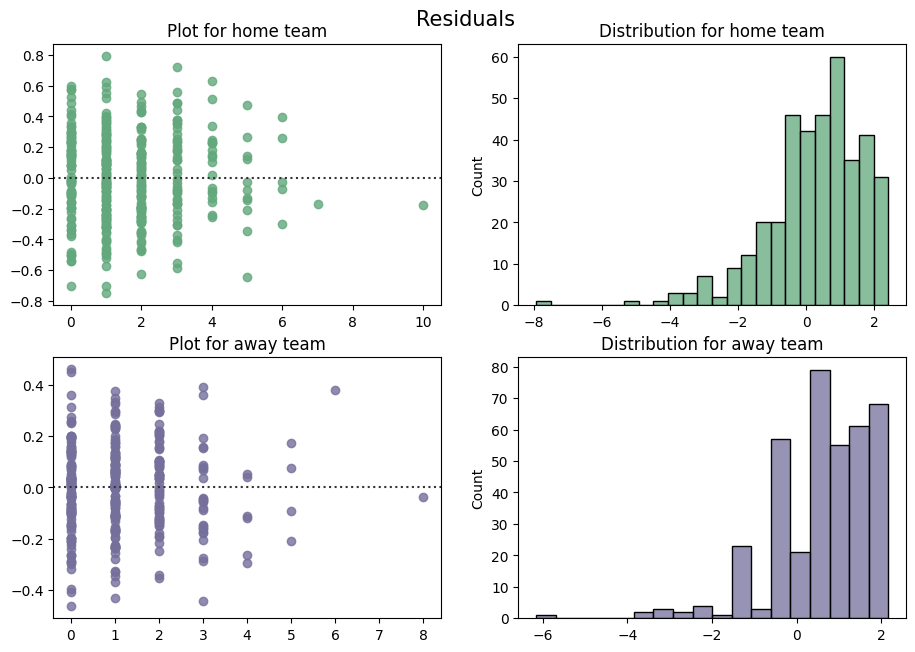

In [253]:
fig, axs = plt.pyplot.subplots(2, 2, figsize=(11, 7))
fig.suptitle('Residuals', fontsize=15)
fig.subplots_adjust(top=0.93)

ax0 = sns.residplot(x=y_test_home, y=home_predict_bal, color='#62A87C', ax=axs[0, 0])
ax0.set(title='Plot for home team', xlabel='')
ax1 = sns.histplot(residuals_home_bal, color='#62A87C', ax=axs[0, 1])
ax1.set(title='Distribution for home team', xlabel='')

ax2 = sns.residplot(x=y_test_away, y=away_predict_bal, color='#756F9B', ax=axs[1, 0])
ax2.set(title='Plot for away team', xlabel='')
ax3 = sns.histplot(residuals_away_bal, color='#756F9B', ax=axs[1, 1])
ax3.set(title='Distribution for away team', xlabel='')

plt.pyplot.tight_layout;

Residuals are skewed to the left.

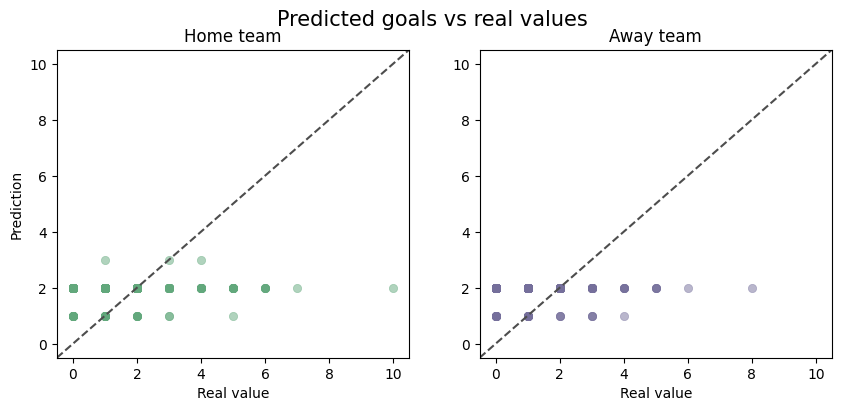

In [254]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Predicted goals vs real values', fontsize=15)

ax0 = sns.scatterplot(x=y_test_home, y=home_predict_bal_r, edgecolor=None, color='#62A87C', alpha=0.5, ax=axs[0])
ax0.set(
    title='Home team',
    ylabel='Prediction',
    xlabel='Real value',
    ylim=[-0.5, 10.5],
    xlim=[-0.5, 10.5],
)
ax0.plot(ax0.get_xlim(), ax0.get_ylim(), ls="--", c=".3")

ax1 = sns.scatterplot(x=y_test_away, y=away_predict_bal_r, edgecolor=None, color='#756F9B', alpha=0.5, ax=axs[1])
ax1.set(
    title='Away team',
    ylabel='',
    xlabel='Real value',
    ylim=[-0.5, 10.5],
    xlim=[-0.5, 10.5],
)
ax1.plot(ax1.get_xlim(), ax1.get_ylim(), ls="--", c=".3");

This model predicts 1, 2 or 3 goals for home teams and 1 or 2 goals for away team.

### Summary of first model

Linear regression model was used to predict how many goals each team - away and home - will make each game. Difference between opposing teams attributes was taken to make predictions. Results were rounded to integers as the it is impossible to "partly make a goal".

Version 1 had R square of 0,019 for home team and 0,02 for away. AIC for home team is 8242 and for away is 7172. Correct results were predicted 27,6% of the times for home team and 35,5% for the away team. Unfortunately, model only predicts 1 or 2 goals for home team and 1 goal all the time for away team.

Version 2 used dataset without any outliers - both as goals and attributes. It had R square of 0,004 for home team and 0,022 for away. AIC for home team is 6154 and for away is 6016. Correct results were predicted 36,3% of the times for home team and 36% for the away team. However, it always predicts just 1 goal for both away and home teams.

Version 3 used balanced dataset using random under sampling. It had R square of 0,038 for home team and 0,03 for away. AIC for home team is 6004 and for away is 5103. Correct results were predicted 25,5% of the times for home team and 23,2% for the away team. It predicts 1, 2 or 3 goals for home team and 1 or 2 goals for away team.

Overall, models never predict 0 goals for any of the games, therefore their performance is lacking. Performance of 3rd version of the model is the best, even if it's accuracy is lowest. That is because it has highest R square values and lowest AIC. It also has highest range of goals for games. However, the model needs further improvements or be redone using different attributes or methods, for example, logistic regression.  

## Predicting who will win the game

### Model version 1

In [255]:
winner_model = LogisticRegression()
winner_model.fit(x_train2, y_train2)

LogisticRegression()

In [256]:
winner_model_stats = sm.MNLogit(y_train2, x_train2).fit()
winner_model_stats.summary()

Optimization terminated successfully.
         Current function value: 1.010910
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 winner   No. Observations:                 1900
Model:                        MNLogit   Df Residuals:                     1868
Method:                           MLE   Df Model:                           30
Date:                Mon, 25 Mar 2024   Pseudo R-squ.:                 0.03295
Time:                        21:46:40   Log-Likelihood:                -1920.7
converged:                       True   LL-Null:                       -1986.2
Covariance Type:            nonrobust   LLR p-value:                 1.446e-14
===============================================================================================
                winner=draw       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_buildUpPlaySpeed          -0.0142      0.008     -1.870      0.061      -0.029       0.001
home_buildUpPlayPassing         0.0041      0.008      0.526      0.599      -0.011       0.019
home_chanceCreationPassing      0.0059      0.007      0.811      0.417      -0.008       0.020
home_chanceCreationCrossing     0.0055      0.007      0.830      0.407      -0.008       0.019
home_hanceCreationShooting      0.0062      0.007      0.877      0.381      -0.008       0.020
home_defencePressure           -0.0069      0.008     -0.909      0.363      -0.022       0.008
home_defenceAggression          0.0103      0.007      1.473      0.141      -0.003       0.024
home_defenceTeamWidth           0.0097      0.008      1.258      0.208      -0.005       0.025
away_buildUpPlaySpeed           0.0080      0.007      1.075      0.282      -0.007       0.022
away_buildUpPlayPassing         0.0057      0.008      0.722      0.470      -0.010       0.021
away_chanceCreationPassing     -0.0278      0.008     -3.690      0.000      -0.043      -0.013
away_chanceCreationCrossing     0.0134      0.007      2.028      0.043       0.000       0.026
away_chanceCreationShooting     0.0098      0.007      1.395      0.163      -0.004       0.024
away_defencePressure            0.0007      0.008      0.099      0.921      -0.014       0.016
away_defenceAggression         -0.0104      0.007     -1.528      0.127      -0.024       0.003
away_defenceTeamWidth          -0.0223      0.008     -2.883      0.004      -0.038      -0.007
-----------------------------------------------------------------------------------------------
                winner=home       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_buildUpPlaySpeed          -0.0012      0.006     -0.181      0.856      -0.014       0.011
home_buildUpPlayPassing        -0.0158      0.007     -2.328      0.020      -0.029      -0.002
home_chanceCreationPassing      0.0078      0.006      1.222      0.222      -0.005       0.020
home_chanceCreationCrossing    -0.0035      0.006     -0.605      0.545      -0.015       0.008
home_hanceCreationShooting      0.0033      0.006      0.553      0.580      -0.009       0.015
home_defencePressure            0.0099      0.006      1.537      0.124      -0.003       0.023
home_defenceAggression          0.0010      0.006      0.161      0.872      -0.011       0.013
home_defenceTeamWidth           0.0264      0.007      4.049      0.000       0.014       0.039
away_buildUpPlaySpeed           0.0085      0.006      1.332      0.183      -0.004       0.021
away_buildUpPlayPassing         0.0068      0.007      1.002      0.316      -0.007       0.020
away_chanceCreationPassing     -0.0159      0.007     -2.404      0.016      -0.029      -0.003
away_chanceCreationCrossing     0.0151      0.006      2.651      0.008  

In [257]:
predictions = winner_model.predict(x_test2)

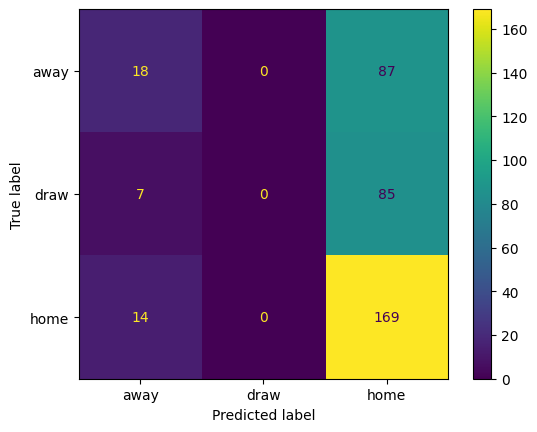

In [258]:
conf_matrix = confusion_matrix(y_test2, predictions, labels=winner_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=winner_model.classes_)
disp.plot();

In [259]:
# Ignoring warning: it is caused by model not predicting any draws.
warnings.filterwarnings('ignore')
print(classification_report(y_test2, predictions))

              precision    recall  f1-score   support

        away       0.46      0.17      0.25       105
        draw       0.00      0.00      0.00        92
        home       0.50      0.92      0.65       183

    accuracy                           0.49       380
   macro avg       0.32      0.36      0.30       380
weighted avg       0.37      0.49      0.38       380



The model predicts that home team will win most of the time. The model also never guessed draw as an outcome.

### Model version 2

Model using balancing of the data, using oversampling.

In [260]:
winner_model2 = LogisticRegression()
winner_model2.fit(x_resampled2, y_resampled2)

LogisticRegression()

In [261]:
winner_model_stats2 = sm.MNLogit(y_resampled2, x_resampled2).fit()
winner_model_stats2.summary()

Optimization terminated successfully.
         Current function value: 1.060261
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 winner   No. Observations:                 2787
Model:                        MNLogit   Df Residuals:                     2755
Method:                           MLE   Df Model:                           30
Date:                Mon, 25 Mar 2024   Pseudo R-squ.:                 0.03491
Time:                        21:46:41   Log-Likelihood:                -2954.9
converged:                       True   LL-Null:                       -3061.8
Covariance Type:            nonrobust   LLR p-value:                 1.275e-29
===============================================================================================
                winner=draw       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_buildUpPlaySpeed          -0.0203      0.006     -3.557      0.000      -0.032      -0.009
home_buildUpPlayPassing         0.0111      0.006      1.956      0.050   -2.28e-05       0.022
home_chanceCreationPassing      0.0116      0.006      2.075      0.038       0.001       0.023
home_chanceCreationCrossing     0.0010      0.005      0.203      0.839      -0.009       0.011
home_hanceCreationShooting      0.0093      0.005      1.742      0.082      -0.001       0.020
home_defencePressure           -0.0077      0.006     -1.339      0.180      -0.019       0.004
home_defenceAggression          0.0133      0.005      2.507      0.012       0.003       0.024
home_defenceTeamWidth           0.0073      0.006      1.254      0.210      -0.004       0.019
away_buildUpPlaySpeed           0.0128      0.006      2.284      0.022       0.002       0.024
away_buildUpPlayPassing        -0.0025      0.006     -0.416      0.677      -0.014       0.009
away_chanceCreationPassing     -0.0304      0.006     -5.320      0.000      -0.042      -0.019
away_chanceCreationCrossing     0.0168      0.005      3.451      0.001       0.007       0.026
away_chanceCreationShooting     0.0144      0.005      2.766      0.006       0.004       0.025
away_defencePressure           -0.0001      0.006     -0.024      0.981      -0.011       0.011
away_defenceAggression         -0.0128      0.005     -2.502      0.012      -0.023      -0.003
away_defenceTeamWidth          -0.0237      0.006     -4.091      0.000      -0.035      -0.012
-----------------------------------------------------------------------------------------------
                winner=home       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_buildUpPlaySpeed          -0.0022      0.006     -0.385      0.700      -0.013       0.009
home_buildUpPlayPassing        -0.0161      0.006     -2.755      0.006      -0.028      -0.005
home_chanceCreationPassing      0.0112      0.006      1.965      0.049    3.12e-05       0.022
home_chanceCreationCrossing    -0.0059      0.005     -1.173      0.241      -0.016       0.004
home_hanceCreationShooting      0.0046      0.005      0.861      0.389      -0.006       0.015
home_defencePressure            0.0096      0.006      1.677      0.093      -0.002       0.021
home_defenceAggression          0.0014      0.005      0.258      0.796      -0.009       0.012
home_defenceTeamWidth           0.0232      0.006      4.013      0.000       0.012       0.035
away_buildUpPlaySpeed           0.0121      0.006      2.126      0.033       0.001       0.023
away_buildUpPlayPassing         0.0005      0.006      0.090      0.928      -0.011       0.012
away_chanceCreationPassing     -0.0211      0.006     -3.627      0.000      -0.033      -0.010
away_chanceCreationCrossing     0.0168      0.005      3.383      0.001  

In [262]:
predictions2 = winner_model2.predict(x_test2)

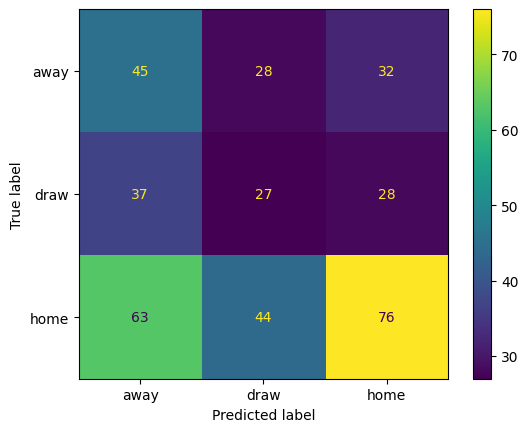

In [263]:
conf_matrix = confusion_matrix(y_test2, predictions2, labels=winner_model2.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=winner_model2.classes_)
disp.plot();

In [264]:
print(classification_report(y_test2, predictions2))

              precision    recall  f1-score   support

        away       0.31      0.43      0.36       105
        draw       0.27      0.29      0.28        92
        home       0.56      0.42      0.48       183

    accuracy                           0.39       380
   macro avg       0.38      0.38      0.37       380
weighted avg       0.42      0.39      0.40       380



Balanced model is able to guess match outcomes for draws as well. It has lower recall for matches won by home and higher precision. It also has higher recall for draw and away.

### Model version 3

The third version of model will use less of teams attributes to make a prediction. 

In [265]:
winner_model3 = LogisticRegression()
winner_model3.fit(x_train3, y_train3)

LogisticRegression()

In [266]:
winner_model_stats3 = sm.MNLogit(y_train3, x_train3).fit()
winner_model_stats3.summary()

Optimization terminated successfully.
         Current function value: 1.020786
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 winner   No. Observations:                 1900
Model:                        MNLogit   Df Residuals:                     1884
Method:                           MLE   Df Model:                           14
Date:                Mon, 25 Mar 2024   Pseudo R-squ.:                 0.02351
Time:                        21:46:41   Log-Likelihood:                -1939.5
converged:                       True   LL-Null:                       -1986.2
Covariance Type:            nonrobust   LLR p-value:                 8.727e-14
===============================================================================================
                winner=draw       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_chanceCreationPassing      0.0020      0.006      0.321      0.748      -0.010       0.014
home_chanceCreationCrossing     0.0048      0.006      0.808      0.419      -0.007       0.017
home_defenceAggression          0.0104      0.006      1.677      0.094      -0.002       0.023
home_defenceTeamWidth           0.0128      0.007      1.927      0.054      -0.000       0.026
away_chanceCreationPassing     -0.0200      0.006     -3.138      0.002      -0.032      -0.007
away_chanceCreationCrossing     0.0144      0.006      2.484      0.013       0.003       0.026
away_defenceAggression         -0.0061      0.006     -0.960      0.337      -0.018       0.006
away_defenceTeamWidth          -0.0205      0.007     -2.999      0.003      -0.034      -0.007
-----------------------------------------------------------------------------------------------
                winner=home       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_chanceCreationPassing      0.0130      0.005      2.387      0.017       0.002       0.024
home_chanceCreationCrossing    -0.0133      0.005     -2.594      0.009      -0.023      -0.003
home_defenceAggression          0.0011      0.005      0.212      0.832      -0.009       0.012
home_defenceTeamWidth           0.0346      0.006      5.966      0.000       0.023       0.046
away_chanceCreationPassing     -0.0098      0.006     -1.781      0.075      -0.021       0.001
away_chanceCreationCrossing     0.0170      0.005      3.386      0.001       0.007       0.027
away_defenceAggression         -0.0011      0.005     -0.207      0.836      -0.012       0.010
away_defenceTeamWidth          -0.0310      0.006     -5.300      0.000      -0.043      -0.020
===============================================================================================
"""

In [267]:
predictions3 = winner_model3.predict(x_test3)

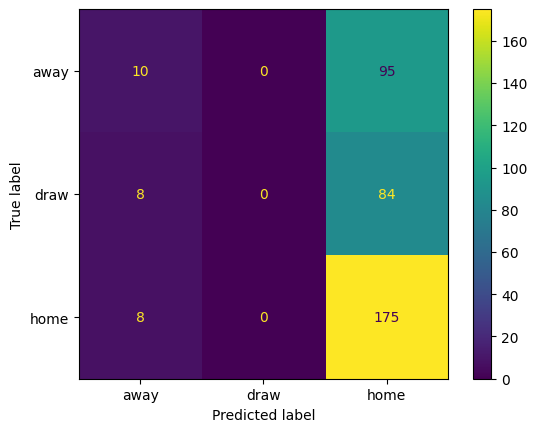

In [268]:
conf_matrix = confusion_matrix(y_test3, predictions3, labels=winner_model3.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=winner_model3.classes_)
disp.plot();

In [269]:
# Ignoring warning: it is caused by model not predicting any draws.
warnings.filterwarnings('ignore')
print(classification_report(y_test3, predictions3))

              precision    recall  f1-score   support

        away       0.38      0.10      0.15       105
        draw       0.00      0.00      0.00        92
        home       0.49      0.96      0.65       183

    accuracy                           0.49       380
   macro avg       0.29      0.35      0.27       380
weighted avg       0.34      0.49      0.36       380



This model is very similar to the first one, has high recall rate for home victories, but lower precision and lower recall for away victories. No predictions for a match ending in a draw.

### Model version 4

This model will use less of the attributes and balancing.

In [270]:
winner_model4 = LogisticRegression()
winner_model4.fit(x_resampled3, y_resampled3)

LogisticRegression()

In [271]:
winner_model_stats4 = sm.MNLogit(y_resampled3, x_resampled3).fit()
winner_model_stats4.summary()

Optimization terminated successfully.
         Current function value: 1.065717
         Iterations 4


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 winner   No. Observations:                 2787
Model:                        MNLogit   Df Residuals:                     2771
Method:                           MLE   Df Model:                           14
Date:                Mon, 25 Mar 2024   Pseudo R-squ.:                 0.02994
Time:                        21:46:41   Log-Likelihood:                -2970.2
converged:                       True   LL-Null:                       -3061.8
Covariance Type:            nonrobust   LLR p-value:                 1.349e-31
===============================================================================================
                winner=draw       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_chanceCreationPassing      0.0003      0.005      0.063      0.949      -0.009       0.010
home_chanceCreationCrossing     0.0067      0.005      1.469      0.142      -0.002       0.016
home_defenceAggression          0.0117      0.005      2.498      0.012       0.003       0.021
home_defenceTeamWidth           0.0161      0.005      3.228      0.001       0.006       0.026
away_chanceCreationPassing     -0.0205      0.005     -4.370      0.000      -0.030      -0.011
away_chanceCreationCrossing     0.0172      0.004      4.088      0.000       0.009       0.025
away_defenceAggression         -0.0058      0.005     -1.242      0.214      -0.015       0.003
away_defenceTeamWidth          -0.0241      0.005     -4.744      0.000      -0.034      -0.014
-----------------------------------------------------------------------------------------------
                winner=home       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
home_chanceCreationPassing      0.0151      0.005      3.111      0.002       0.006       0.025
home_chanceCreationCrossing    -0.0160      0.005     -3.541      0.000      -0.025      -0.007
home_defenceAggression         -0.0014      0.005     -0.291      0.771      -0.011       0.008
home_defenceTeamWidth           0.0389      0.005      7.499      0.000       0.029       0.049
away_chanceCreationPassing     -0.0115      0.005     -2.403      0.016      -0.021      -0.002
away_chanceCreationCrossing     0.0204      0.004      4.687      0.000       0.012       0.029
away_defenceAggression         -0.0036      0.005     -0.758      0.448      -0.013       0.006
away_defenceTeamWidth          -0.0416      0.005     -8.153      0.000      -0.052      -0.032
===============================================================================================
"""

In [272]:
predictions4 = winner_model4.predict(x_test3)

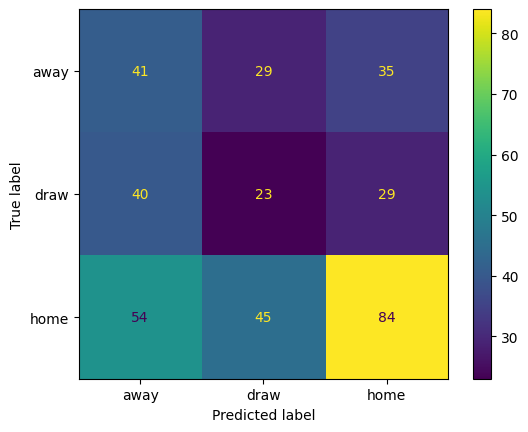

In [273]:
conf_matrix = confusion_matrix(y_test3, predictions4, labels=winner_model4.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=winner_model4.classes_)
disp.plot();

In [274]:
print(classification_report(y_test3, predictions4))

              precision    recall  f1-score   support

        away       0.30      0.39      0.34       105
        draw       0.24      0.25      0.24        92
        home       0.57      0.46      0.51       183

    accuracy                           0.39       380
   macro avg       0.37      0.37      0.36       380
weighted avg       0.41      0.39      0.40       380



Results are very similar to model two, with higher recall for matches which end up in draw and lower recall for away team victories.

## Summary of the second model

Model to predict outcome of the match was created, using away and home teams attributes. For version 1 of the model all attributes were used. Version 2 used all attributes, but also was balanced using oversampling. Version 3 used 4 of the attributes for away and home teams, which were selected by having lowest p-values in previous models and no significant correlation with each other (same attributes chosen for both away and home teams). Version 4 used the dataset with less attributes, but also was balanced using oversampling.

Overall, versions 1 and 3 performed similarly, just as versions 2 and 4. Both versions 1 and 3, did not predict that match would end up in a draw, and had high recall rate for home wins (v1 - 92%, v2 - 96%). Versions 2 and 4 have lower accuracy compared to version 1 and 3 (38% vs 49%), however they have higher precision for predicting draws, home and away victories.

R squared is low in every version of the model (it is highest in version 2 - 0,034 and lowest in version 3 - 0,024). Version 1 has Highest Log-Likelyhood (-1920,7), version 3 has similar (-1939,5). Versions 2 and 4 have lower Log-Likelyhoods (-2956,9 and -2977 respectively).

According to Log-Likelyhood, best version is 1, however versions with less attributes perform very similarly. Also versions 2 and 4 have better precision overall. Therefore, model version should be selected depending on needs, if we need to recall as many home victories as possible, versions 1 and 3 should be used. If we wish to try and predict if the match is a draw, home or away victory, versions 2 or 4 will do a better job.

# Summary

- There are 11 leagues in this dataset from 10 countries – two of the leagues are in the UK. 
- In total the dataset has 285 different teams and 11060 players.
- Top three highest rating players are Leonel Messi, Christiano Ronaldo and Franck Ribery.
- Match table has seasons from 2008/2009 to 2015/2016.
- Most goals scored by a team in a match was 10 and it happened twice: in season 2010/2011 Netherlands Eredivisie league in a match PSV vs Feyenoord, PSV scored 10 goals, and in Spain LIGA BBVA in season 2015/2016 in a match Real Madrid CF vs Rayo Vallecano, Real Madrid CF scored 10 goals, whole Rayo Vallecano scored only two.
- Most goals overall were scored in Spain LIGA BBVA, however Netherlands Eredivisie league has more goals on average per match.
- Most goals were made by Lionel Messi, closely followed by Cristiano Ronaldo. In third place by overall amount of goals is Zlatan Ibrahimovic.
- According to the dataset, there is home advantage, as home team wins 46% of the time, compared to away team – 29%.
- No difference between tall and short players overall scores found.
- Linear regression model was used to predict how many goals each team – away and home – will make each game. Models never predict 0 goals for any of the games, therefore it performance is lacking. 
- Logistic model was used to predict outcome of the match, using away and home teams attributes. Model had several different versions which should be selected depending on needs: if we need to recall as many home victories as possible, versions 1 and 3 should be used. If we wish to try and predict if the match is a draw, home or away victory, versions 2 or 4 will do a better job. 

# Suggestions for improvement

- Draw separate map for UK premier leagues, as there are two of them, or find a way to separate UK into countries and have Scotland and England in the map.
- Explain team attributes. Explain more of player attributes.
- Statistics for average team rating over the year.
- For team categorical attributes and numerical attributes graphs make better names.
- Add an interactive radar plot where one could chose a team to check their attributes.
- Remove duplicate entries in team_att, team, and player_att tables for better statistics.
- Include description how betting odds are calculated.
- Include player position analysis.
- Which minute goals were made and by which team.
- Which players made most assists.
- Top scoring team per season and overall.
- Top scoring player per season.
- Average goals per match for players.
- Correlations between different betting companies.
- Use player attributes for prediction models.
- Use team attributes instead of their differences for linear prediction model.
- Include waterfall plots for models.
- Categorize games into 0, 1, 2 and 3 or more goals and use logistic regression model to predict how many goals will be made. 